# Spotify: comprender y preparar los datos
## Unidad 1 · Análisis exploratorio y calidad de datos

Este cuaderno analiza el dataset **Spotify Tracks** para comprender la popularidad registrada, revisar la calidad de los datos y preparar representaciones útiles para su estudio. Cada bloque incluye código breve, explicación de sus instrucciones e interpretación de los resultados.

**Archivo necesario:** `Spotify_Tracks_Dataset.csv`, ubicado en la misma carpeta que este cuaderno. Se requiere Python con Pandas y Matplotlib. Ejecutar las celdas desde arriba hacia abajo; para reproducir el trabajo completo, reiniciar el kernel y ejecutar todas.

### Recorrido del cuaderno

1. Contexto, objetivos y metas de calidad.
2. [Carga del CSV](#carga) y [significado de las columnas](#columnas).
3. [Auditoría de calidad](#auditoria) y [limpieza justificada](#limpieza).
4. [Estadísticas y distribuciones](#descriptivo) y [relaciones con popularidad](#relaciones).
5. [Multi-Hot Encoding de géneros](#multihot).
6. [Escalamiento demostrativo](#escalamiento).
7. [Ética, sesgos y limitaciones](#etica).
8. [Cierre de los KPI y evidencias](#kpi).
9. [Conclusiones generales](#conclusiones).

**Conservación de datos:** el CSV original y `df` permanecen intactos. La limpieza se realiza en `df_limpio`; las representaciones por ID y las escalas se construyen en tablas auxiliares.

**Límite del escalamiento:** se ajusta con toda la muestra solo para aprender las fórmulas. Sus tablas de demostración no deben reutilizarse para evaluar modelos independientes; en esa etapa el ajuste debe hacerse únicamente con entrenamiento.


## 1. Contexto del proyecto

Spotify dispone de canciones con características como duración, energía, bailabilidad y popularidad. Utilizaremos el dataset **Spotify Tracks Dataset**, contenido en el archivo `Spotify_Tracks_Dataset.csv`.

En ese dataset, la popularidad se registra como un puntaje entre **0 y 100**. Es nuestra variable de interés: queremos conocer cómo se distribuye y explorar su relación con las características disponibles.

**Popularidad no significa calidad artística.** Un puntaje alto no demuestra que una canción sea mejor. Tampoco representa directamente un porcentaje de oyentes.

El archivo CSV se incorpora manualmente a la carpeta del cuaderno y se lee desde esa ubicación. La carga no requiere descargar datos desde internet.

**Limitación temporal:** no contamos con una fecha de extracción verificada. Como la popularidad cambia, describiremos lo registrado en esta muestra; no lo presentaremos como popularidad actual ni como éxito futuro.

### Justificación del dataset

El dataset permite aplicar la revisión de calidad y el análisis exploratorio a un contexto musical. Sus características numéricas y categóricas permiten estudiar distribuciones y relaciones con la popularidad.

**Contexto de uso:** una persona que analiza un catálogo musical necesita conocer la información disponible, detectar problemas de calidad y describir las canciones antes de plantear un modelo.

**Pregunta de esta etapa:** ¿qué información contiene el dataset de Spotify, qué problemas de calidad presenta y cómo se relacionan sus características con la popularidad registrada?

## 2. Objetivo general

**Comprender, revisar y preparar el dataset de Spotify mediante un análisis exploratorio, para describir la popularidad y sus relaciones con las características disponibles, documentando las decisiones de calidad y las limitaciones de los datos.**

Elegimos este objetivo porque corresponde a la unidad 1: conocer y preparar los datos. La predicción y la comparación de modelos se abordarán en una etapa posterior.

### Objetivos específicos

1. Identificar qué representa cada fila, qué significa cada columna y qué tipo de dato contiene.
2. Detectar datos faltantes, duplicados exactos y valores que requieran revisión.
3. Justificar los tratamientos de limpieza y registrar cuántas filas o valores modifica cada uno.
4. Describir la popularidad y las características musicales mediante estadísticas y gráficos sencillos.
5. Explorar relaciones entre variables, distinguiendo asociación de causalidad.
6. Reconocer posibles sesgos y límites de interpretación.

**Decisión:** todavía no fijamos una cantidad de filas que debamos eliminar ni una relación que debamos encontrar. El análisis puede revelar relaciones débiles y seguir siendo un trabajo válido.

## 3. Alcance de la unidad 1

El trabajo comprende carga y comprensión de los datos, auditoría, limpieza justificada, análisis descriptivo y relaciones con popularidad. Incluye Multi-Hot Encoding para conservar los géneros por canción y una demostración de escalamiento sobre tablas auxiliares.

El cierre reúne la reflexión ética, las metas de calidad con sus evidencias y las conclusiones generales. No se entrenan modelos ni se presentan métricas de predicción. Los resultados describen la muestra y las decisiones de preparación, con sus límites de interpretación.

## 4. ¿Qué es un KPI?

Un **KPI** es un indicador que elegimos para comprobar si estamos cumpliendo una meta importante del proyecto.

Conviene distinguir tres cosas:

| Elemento | Ejemplo |
|---|---|
| Objetivo | Preparar datos utilizables y documentados |
| Indicador | Porcentaje de filas con popularidad inválida sin resolver |
| Meta | Que ese porcentaje sea 0% en la base preparada |

Un KPI no es un modelo y no tiene que medir predicciones. En esta unidad mediremos la calidad y la trazabilidad de la preparación.

**Decisión:** no exigiremos conservar automáticamente el 99% de las filas. Eliminar mucho o poco no demuestra, por sí solo, que la limpieza sea correcta.

### KPI 1 · Popularidad válida en la base preparada

**Qué mide:** el porcentaje de filas cuya popularidad está ausente, no es numérica o queda fuera del intervalo permitido de 0 a 100.

**Cálculo:**

`filas con popularidad inválida / filas de la base preparada × 100`

**Meta propuesta:** 0% de filas con popularidad inválida en la base preparada, siempre que la base no esté vacía.

**¿Por qué?** La popularidad es la variable que queremos estudiar. Si falta o no es válida, esa fila no permite analizarla directamente.

**Ejemplo ficticio:** 5 filas inválidas entre 100 equivalen al 5%. No es un resultado del dataset.

**Cómo actuaremos:** revisaremos el origen del problema antes de corregirlo o excluir la fila de la base de análisis. No inventaremos su popularidad para cumplir el KPI. El archivo original permanecerá intacto.

**Detalle importante:** una popularidad igual a 0 es válida; no se eliminará por ser cero.

### KPI 2 · Duplicados exactos sin resolver

**Qué mide:** el porcentaje de filas adicionales que repiten exactamente el contenido de una fila anterior, usando las columnas de contenido definidas en la auditoría.

**Cálculo:**

`filas duplicadas adicionales / filas de la base preparada × 100`

**Meta propuesta:** 0% de duplicados exactos sin resolver en la base preparada, siempre que la base no esté vacía.

**¿Por qué?** Una repetición accidental puede dar más peso a una observación al calcular estadísticas.

**Ejemplo ficticio:** si una fila aparece tres veces, hay dos copias adicionales para esta medida.

**Precaución:** una canción repetida con otro género no es necesariamente un duplicado exacto ni un error. Primero estudiaremos qué representa cada fila. Un índice exportado del archivo tampoco debe ocultar repeticiones del contenido.

**Decisión:** no eliminaremos registros solo porque compartan título, artista o identificador sin revisar antes su significado.

### KPI 3 · Registro de las modificaciones

**Qué mide:** el porcentaje de operaciones de limpieza aplicadas que quedan documentadas con motivo y cantidad de filas o valores afectados.

**Cálculo:**

`operaciones documentadas / operaciones aplicadas × 100`

**Meta propuesta:** 100% de operaciones documentadas.

**¿Por qué?** Debemos poder explicar cómo pasamos del archivo original a la base preparada.

Registraremos para cada operación:

- Qué problema encontramos.
- Qué hicimos y por qué.
- Cuántas filas o valores afectó.
- Qué limitación o posible sesgo introduce.

**Si no hace falta modificar nada:** el indicador se marcará como «No aplica» y se explicará el motivo. No se calculará una división por cero.

### KPI 4 · Reglas de calidad con una conclusión

**Qué mide:** el porcentaje de reglas definidas en la auditoría inicial para las columnas seleccionadas que terminan con una conclusión y evidencia.

**Cálculo:**

`reglas revisadas y documentadas / reglas acordadas en la auditoría inicial × 100`

**Meta propuesta:** 100% de reglas con conclusión documentada.

**¿Por qué?** Detectar un valor extraño no basta: debemos decidir si es válido, corregible o si no puede utilizarse para el análisis previsto.

Una conclusión puede ser «no se detectan problemas», «se corrigió», «se excluyó de la base preparada» o «se conserva como valor válido y se explica la limitación».

**Ejemplo:** una canción muy larga puede ser un valor atípico válido. Identificarla no obliga a eliminarla.

**Definición operativa:** la sección 10.1 enumera los 13 aspectos de revisión antes de la limpieza. El cierre cuenta esos aspectos sin cambiar las reglas para mejorar el indicador. Las conclusiones que conservan alertas se distinguen de problemas resueltos.

### Metas de calidad y documentación

| KPI | Meta | Unidad del indicador |
|---|---|---|
| Popularidad inválida en la base preparada | 0% | Registros preparados |
| Copias exactas adicionales de contenido | 0% | Registros preparados |
| Operaciones de limpieza documentadas | 100% o no aplica | Operaciones aplicadas |
| Reglas de calidad con conclusión documentada | 100% | Aspectos de la auditoría inicial |

Las dos primeras metas se refieren a la base preparada, no a que el archivo original llegue perfecto. Las reglas operativas se detallan en la auditoría antes de aplicar la limpieza.

El [cierre final de KPI](#kpi), en la sección 25, reúne resultados, cálculos y evidencias. Su cumplimiento no garantiza ausencia de sesgos, representatividad ni calidad perfecta: comprueba aspectos concretos de preparación y documentación.

## 5. Qué hemos decidido y qué falta comprobar

| Decisión actual | Motivo |
|---|---|
| Utilizar el dataset de Spotify | Estudiar características musicales y su relación con la popularidad |
| Estudiar la popularidad registrada | Mantener una pregunta central clara |
| Comenzar con comprensión y preparación | Seguir el contenido de la unidad 1 |
| Conservar intacto el archivo original | Poder revisar y reproducir los cambios |
| Justificar cada tratamiento | Evitar eliminar datos por costumbre |
| Evaluar los resultados después de preparar | Comparar las metas con evidencias, sin anticipar cumplimiento |

**Antes de seguir, deberíamos poder responder:**

1. ¿Qué queremos estudiar y qué significa popularidad en este trabajo?
2. ¿Cuál es la diferencia entre un objetivo, un indicador y una meta?
3. ¿Por qué una canción con popularidad 0 no es automáticamente un error?
4. ¿Por qué una canción con varios géneros no es automáticamente un duplicado eliminable?
5. ¿Por qué conservar muchas filas no garantiza calidad?

**A continuación:** cargamos el CSV original y explicamos cada instrucción y su salida. La evaluación de los KPI se presenta al cierre, después de preparar y verificar los datos.

<a id="carga" ></a>

## 6. Carga del dataset

**Pregunta:** ¿podemos leer el archivo y reconocer qué contiene, antes de modificarlo?

Antes de ejecutar las celdas, coloca manualmente `Spotify_Tracks_Dataset.csv` en la misma carpeta que este archivo `.ipynb`. Conserva exactamente ese nombre, incluida la extensión `.csv`.

La carpeta debe contener:

```text
Spotify_Unidad_1.ipynb
Spotify_Tracks_Dataset.csv
```

Abre el cuaderno en Jupyter desde esa carpeta. La ruta relativa del código se interpreta desde la carpeta de trabajo del kernel, que normalmente coincide con la del cuaderno. En Colab, sube el CSV al panel de archivos de la sesión antes de ejecutar la lectura.

**Qué necesitamos:** Python y la biblioteca Pandas. Si aparece `ModuleNotFoundError: No module named 'pandas'`, Pandas no está instalado en el entorno que ejecuta el cuaderno.

Ejecuta las celdas desde arriba hacia abajo con **Shift + Enter**. Si cambias una celda, su salida anterior no se actualiza hasta ejecutarla de nuevo. Para repetir todo, reinicia el kernel y ejecuta todas las celdas.

### 6.1 Importar Pandas

**Línea:** `import pandas as pd`

- `import` incorpora una biblioteca para poder utilizarla.
- `pandas` es la biblioteca que permite leer y trabajar con tablas.
- `as pd` le asigna el nombre corto `pd`, habitual en los ejemplos de clase.

**Salida esperada:** ninguna tabla ni mensaje. La instrucción prepara la herramienta; todavía no carga datos. Una celda sin salida puede haberse ejecutado correctamente.

In [1]:
import pandas as pd

### 6.2 Indicar el nombre del archivo

**Línea:** `archivo_datos = "Spotify_Tracks_Dataset.csv"`

- `archivo_datos` es una variable: un nombre que guarda un valor.
- `=` asigna el texto de la derecha a ese nombre. No es una comparación.
- Las comillas indican que guardamos texto.
- `Spotify_Tracks_Dataset.csv` es el nombre exacto del archivo que se incorpora manualmente.
- Como no indicamos otras carpetas, Python lo buscará en su carpeta de trabajo.

**Salida esperada:** ninguna. Guardar el nombre todavía no lee ni modifica el CSV.

In [2]:
archivo_datos = "Spotify_Tracks_Dataset.csv"

### 6.3 Leer el CSV y guardarlo como tabla

**Línea:** `df = pd.read_csv(archivo_datos)`

- `pd` es el nombre corto de Pandas.
- `.read_csv()` es la función que lee un archivo CSV, cuyos valores están separados por comas en este caso.
- `archivo_datos`, dentro de los paréntesis, indica qué archivo local leer.
- `df =` guarda la tabla resultante con el nombre `df`.

`df` es una abreviatura habitual de **DataFrame**: una tabla organizada en filas y columnas. Podríamos elegir otro nombre; no es una palabra especial de Python.

**Salida esperada:** ninguna, porque guardamos la tabla sin pedir que se muestre.

**Si aparece `FileNotFoundError`:** comprueba que el CSV esté en la carpeta de trabajo y que su nombre sea exactamente `Spotify_Tracks_Dataset.csv`. Si el archivo y el cuaderno están juntos pero persiste el error, puedes consultar `import os` y luego `os.getcwd()` en una celda auxiliar para ver dónde busca Python. Si aparece `NameError`, ejecuta primero las celdas que definen `pd` y `archivo_datos`.

**Decisión:** leer no elimina, imputa ni renombra registros. El archivo CSV permanece intacto.

In [3]:
df = pd.read_csv(archivo_datos)

### 6.4 Mostrar las primeras filas

**Línea:** `df.head()`

- `df` es la tabla que acabamos de cargar.
- `.head()` muestra sus primeras cinco filas por defecto.
- Los paréntesis vacíos indican que aceptamos esa cantidad predeterminada.

En un cuaderno, dejar esta expresión al final de la celda muestra la tabla sin escribir `print()`.

**Importante:** mostrar cinco filas no significa que solo hayamos cargado cinco. Es una vista previa y no una muestra aleatoria o representativa.

In [4]:
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


### Cómo leer esta primera tabla

Cada fila es un **registro del archivo**. Antes de contar canciones únicas, debemos revisar identificadores y repeticiones entre géneros.

Algunos nombres que aparecen:

| Columna original | Lectura inicial |
|---|---|
| `track_id` | Identificador de la canción |
| `artists` | Artista o artistas |
| `track_name` | Nombre de la canción |
| `popularity` | Puntaje de popularidad registrado |
| `duration_ms` | Duración en milisegundos |
| `explicit` | Indicador de contenido explícito: `True` o `False` |
| `track_genre` | Género indicado en ese registro |

**Ejemplo real de la primera fila:** `Comedy`, de Gen Hoshino, tiene popularidad **73**, duración **230666 ms** y `explicit=False`.

- **73** es un puntaje, no 73% de oyentes ni 73% de aciertos.
- **230666 ms / 1000 = 230,666 segundos**, aproximadamente 3 minutos y 51 segundos.
- **False** indica que el archivo no la marca como contenido explícito.

Estos son atributos de una canción, no resultados de un modelo.

A la izquierda aparece el índice de Pandas, que comienza en 0. Además existe una columna llamada `Unnamed: 0`, cuyos primeros valores también son 0, 1, 2… Parece un índice exportado anteriormente, pero todavía no la eliminamos.

Si Jupyter muestra puntos suspensivos, está abreviando la presentación de columnas; no significa que se hayan perdido datos.

### 6.5 Conocer las dimensiones

**Línea:** `df.shape`

- `.shape` es una propiedad que informa el tamaño de la tabla.
- No lleva paréntesis porque consultamos una propiedad, en lugar de llamar a un método.
- Entrega dos números en este orden: **(filas, columnas)**.

In [5]:
df.shape

(114000, 21)

### Qué significa `(114000, 21)`

- **114000:** se cargaron 114.000 registros.
- **21:** el archivo contiene 21 columnas, incluyendo `Unnamed: 0`.
- El índice que Pandas muestra a la izquierda no se cuenta como una columna adicional.

Entre las 21 columnas aparece `Unnamed: 0`, que parece corresponder a un índice exportado. Revisaremos su contenido antes de decidir qué hacer.

**Conclusión permitida:** conocemos el tamaño de la tabla cargada.

**Conclusiones que todavía no podemos sacar:** que existan 114.000 canciones únicas, que no falten datos o que todas las filas sean válidas.

### 6.6 Ver los nombres de todas las columnas

**Línea:** `df.columns.tolist()`

- `df.columns` obtiene los nombres de las columnas.
- `.tolist()` los convierte en una lista de Python para mostrarlos juntos.
- No cambia los nombres ni modifica los datos.

**Salida esperada:** una lista de 21 nombres entre corchetes. Las comillas indican que cada nombre es texto.

Mantendremos los nombres originales en inglés por ahora. Primero aprenderemos su significado; si más adelante decidimos traducirlos, registraremos el cambio.

In [6]:
df.columns.tolist()

['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']

## 7. Cierre del paso de carga

**Comprobaciones realizadas:** el CSV se puede leer, la vista previa tiene columnas reconocibles y la tabla tiene **114.000 filas y 21 columnas**. Las salidas guardadas se obtuvieron ejecutando la lectura local de `Spotify_Tracks_Dataset.csv`. Si se utiliza otra versión del CSV, se deben ejecutar nuevamente las celdas y revisar los resultados.

**Todavía no hemos calculado los KPI.** Leer un archivo correctamente no demuestra que esté limpio. Las filas cargadas no se han eliminado ni transformado.

**Para comprobar que entendimos:**

1. ¿Por qué `import pandas as pd` no muestra una tabla?
2. ¿Qué diferencia hay entre guardar el nombre del archivo y ejecutar `read_csv()`?
3. ¿Por qué `head()` muestra cinco filas si se cargaron 114.000?
4. ¿Qué representa cada número de `shape`?
5. ¿Por qué 114.000 filas no equivalen necesariamente a 114.000 canciones únicas?

**Próximo paso:** revisar el significado y los tipos de las columnas. Después definiremos las reglas de calidad y mediremos faltantes, duplicados y rangos. No aplicaremos limpieza antes de comprender esos resultados.

<a id="columnas" ></a>

## 8. Significado de las columnas y tipos de datos

**Objetivo de esta sección:** comprender qué representa cada columna y cómo la almacena Pandas, antes de definir las reglas de calidad.

Distinguiremos dos conceptos:

- **Tipo técnico:** cómo guarda Python el dato, por ejemplo entero, decimal, texto o booleano.
- **Significado analítico:** qué representa, por ejemplo una medida, una categoría o un identificador.

Un número no siempre es una cantidad. Un código de tonalidad es numérico, pero no significa que una tonalidad sea mayor o mejor que otra.

Conservamos los nombres originales y el contenido de `df`. En esta sección no eliminamos filas, no rellenamos faltantes y no convertimos tipos.

### 8.1 Revisar la estructura con `info()`

**Línea:** `df.info()`

- `df` es la tabla cargada en las celdas anteriores.
- `.info()` muestra un resumen de su estructura.
- Los paréntesis llaman al método; no necesitamos argumentos para esta consulta.

La instrucción escribe un resumen. No hace falta envolverla en `print()`: hacerlo podría añadir `None`, porque el método muestra información pero no devuelve otra tabla.

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

### Cómo interpretar el resumen

| Parte de la salida | Qué significa |
|---|---|
| `pandas.DataFrame` | El objeto es una tabla de Pandas |
| `114000 entries` | Contiene 114.000 filas |
| `0 to 113999` | Su índice empieza en 0 y termina en 113.999; hay 114.000 posiciones |
| `total 21 columns` | Hay 21 columnas |
| `Column` | Nombre de cada columna |
| `Non-Null Count` | Número de valores que Pandas no reconoce como faltantes |
| `Dtype` | Tipo técnico detectado al leer el CSV |
| `memory usage` | Estimación de memoria utilizada, no el peso exacto del CSV |

**Resultado observado:** `artists`, `album_name` y `track_name` tienen **113.999 valores no nulos** cada una, frente a 114.000 filas. Por diferencia, hay un faltante reconocido por Pandas en cada columna.

Esto no permite afirmar todavía si los tres faltantes están en la misma fila. Tampoco comprueba si hay textos vacíos o signos como `?`: pueden aparecer como no nulos y requerir revisión.

**El resto de las columnas tiene 114.000 valores no nulos.** Eso informa de presencia, no de validez: un número fuera de rango puede estar presente y ser incorrecto.

La memoria y la etiqueta exacta de texto pueden variar entre versiones de Pandas. Si aparece `str`, `string` u `object` en columnas de texto, revisaremos esa salida sin tratar la diferencia de versión como un error del archivo.

### 8.2 Consultar los tipos de cada columna

**Línea:** `df.dtypes`

- `df` es la tabla.
- `.dtypes` obtiene el tipo de cada columna.
- No lleva paréntesis porque es una propiedad.

La salida es una **Serie de Pandas**: una lista etiquetada donde cada nombre de columna tiene asociado su tipo. Si al final aparece `dtype: object`, describe esa Serie de tipos, no afirma que todas las columnas del dataset sean texto.

In [8]:
df.dtypes

Unnamed: 0            int64
track_id                str
artists                 str
album_name              str
track_name              str
popularity            int64
duration_ms           int64
explicit               bool
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
time_signature        int64
track_genre             str
dtype: object

### Qué significa cada tipo técnico

| Tipo observado | Significado | Ejemplo del archivo |
|---|---|---|
| `int64` | Entero: se almacena sin parte decimal | `popularity`: 73 |
| `float64` | Número con decimales | `danceability`: 0.676 |
| `bool` | Valor lógico `True` o `False` | `explicit`: False |
| `str` | Texto | `track_name`: Comedy |

El **64** describe el tamaño de la representación numérica en bits. No es el número de registros, el máximo valor permitido ni una medida de calidad.

En otras versiones, las columnas de texto pueden figurar como `object` o `string`. `object` es un contenedor más general: por sí solo no garantiza que todos sus valores sean texto.

**Decisión:** no convertimos automáticamente `key`, `mode` ni `time_signature` a medidas continuas solo porque Pandas los lea como enteros.

### 8.3 Contar cuántas columnas hay de cada tipo

**Línea:** `df.dtypes.value_counts()`

- `df.dtypes` obtiene los tipos de las 21 columnas.
- `.value_counts()` cuenta cuántas veces aparece cada tipo en esa lista.

**Atención:** cuenta columnas por tipo; no cuenta canciones, géneros ni valores diferentes dentro de `df`.

El orden de la salida depende de las frecuencias; no representa importancia.

In [9]:
df.dtypes.value_counts()

float64    9
int64      6
str        5
bool       1
Name: count, dtype: int64

### Interpretación del conteo de tipos

En la lectura realizada se observan:

| Tipo | Cantidad de columnas |
|---|---:|
| `float64` | 9 |
| `int64` | 6 |
| Texto (`str` en este entorno) | 5 |
| `bool` | 1 |
| **Total** | **21** |

La suma **9 + 6 + 5 + 1 = 21** coincide con las dimensiones de la tabla.

Esto no equivale a tener 15 características musicales cuantitativas: entre los enteros hay un posible índice y códigos de categorías. Para decidir qué análisis tiene sentido debemos entender su significado.

### 8.4 Diccionario de datos · Identificación y contexto

La columna «tipo técnico» refleja la lectura de este archivo. La columna «uso» explica cómo interpretamos la variable, sin convertirla todavía.

| Columna | Tipo técnico | Significado | Uso o precaución |
|---|---|---|---|
| `Unnamed: 0` | `int64` | Columna sin nombre explícito; parece un índice exportado | No representa una característica musical. Confirmaremos su contenido antes de decidir su eliminación |
| `track_id` | Texto | Identificador Spotify de la canción | Identificar registros y revisar repeticiones; no tiene sentido calcular su promedio |
| `artists` | Texto | Artistas; las colaboraciones aparecen separadas por `;` | Texto descriptivo; una cadena con varios nombres no equivale a un solo artista individual |
| `album_name` | Texto | Nombre del álbum | Contexto descriptivo; revisar faltantes |
| `track_name` | Texto | Título de la canción | Un título por sí solo no identifica inequívocamente una canción |
| `track_genre` | Texto | Género asociado al registro | Categoría musical; una canción puede aparecer en registros de distintos géneros |

**Decisión:** conservar un identificador como texto evita tratar sus letras y números como una cantidad. No eliminamos canciones únicamente por compartir título.

### 8.5 Diccionario de datos · Variable de interés y características musicales

| Columna | Tipo técnico | Significado y unidad o escala |
|---|---|---|
| `popularity` | `int64` | Puntaje de popularidad, 0–100; variable de interés |
| `duration_ms` | `int64` | Duración en milisegundos |
| `explicit` | `bool` | Indicador de contenido explícito |
| `danceability` | `float64` | Bailabilidad, escala 0–1 |
| `energy` | `float64` | Intensidad y actividad percibidas, escala 0–1 |
| `key` | `int64` | Código de tonalidad: 0=Do, 1=Do sostenido/Re bemol, …, 11=Si; −1 significa no detectada |
| `loudness` | `float64` | Sonoridad media en decibelios (dB) |
| `mode` | `int64` | Modo musical: 0=menor; 1=mayor |
| `speechiness` | `float64` | Presencia de habla, escala 0–1 |
| `acousticness` | `float64` | Confianza en el carácter acústico, escala 0–1 |
| `instrumentalness` | `float64` | Estimación de ausencia de voces, escala 0–1 |
| `liveness` | `float64` | Indicios de interpretación en vivo, escala 0–1 |
| `valence` | `float64` | Positividad musical percibida, escala 0–1 |
| `tempo` | `float64` | Tempo estimado en pulsaciones por minuto (BPM) |
| `time_signature` | `int64` | Código del compás estimado; por ejemplo, 4 indica cuatro pulsos por compás |

Las escalas y códigos describen el significado de las variables, no una comprobación de que todos los registros los cumplan. Esa validación corresponde a la auditoría.

Fuentes de las definiciones: [características de audio de Spotify](https://developer.spotify.com/documentation/web-api/reference/get-audio-features) y [datos de una canción](https://developer.spotify.com/documentation/web-api/reference/get-track). Consultarlas sirve para interpretar el CSV local; el código no llama a la API.

### Precauciones al interpretar los valores

- **Escala no es porcentaje:** `danceability=0.676` no mide al público que bailó; es una puntuación del atributo.
- **Valores negativos:** un `loudness` negativo no es automáticamente inválido. No debemos eliminar números solo por su signo.
- **Categorías numéricas:** `mode=1` no representa el doble de `mode=0`. Son etiquetas.
- **Estimación no es certeza:** las características calculadas no sustituyen una verificación de la grabación.
- **`explicit=False`:** puede indicar ausencia de contenido explícito o información desconocida; no garantiza una revisión manual.
- **Ceros:** no todos los ceros representan faltantes. Su significado depende de la columna y debe justificarse antes de tratarlos.

Las variables de audio describen la canción; no indican por sí mismas cuánto gusta ni qué causa su popularidad.

### 8.6 Leer una selección pequeña de columnas

**Código:**

```python
columnas_ejemplo = ["track_name", "popularity", "duration_ms", "explicit", "key", "mode"]
df[columnas_ejemplo].head(3)
```

**Primera línea:**

- `columnas_ejemplo` guarda una lista de nombres de columnas.
- Los corchetes `[...]` crean la lista; cada nombre entre comillas es texto.
- Las comas separan los elementos.

**Segunda línea:**

- `df[columnas_ejemplo]` selecciona esas columnas para mostrarlas.
- `.head(3)` limita la vista a los primeros tres registros.
- La selección no elimina las demás columnas de `df`, porque no la reasignamos a `df`.

**¿Por qué?** Una vista corta facilita relacionar nombres, tipos y valores sin interpretar las 21 columnas a la vez.

In [10]:
columnas_ejemplo = ["track_name", "popularity", "duration_ms", "explicit", "key", "mode"]
df[columnas_ejemplo].head(3)

,track_name,popularity,duration_ms,explicit,key,mode
0,Comedy,73,230666,False,1,0
1,Ghost - Acoustic,55,149610,False,1,1
2,To Begin Again,57,210826,False,0,1


### Interpretación de la selección

En el primer registro:

| Valor observado | Interpretación |
|---|---|
| `Comedy` | Texto: título de la canción |
| `73` en `popularity` | Puntaje entero de popularidad |
| `230666` en `duration_ms` | Duración cuantitativa en milisegundos |
| `False` en `explicit` | Indicador booleano |
| `1` en `key` | Código de una tonalidad |
| `0` en `mode` | Categoría «menor»; no significa ausencia de dato |

**La diferencia central:** `popularity`, `duration_ms`, `key` y `mode` están almacenadas como enteros, pero no representan el mismo tipo de información.

La popularidad y la duración se pueden describir con promedios, atendiendo a sus límites de interpretación. Para tonalidad y modo, los conteos por categoría son más adecuados que promediar sus códigos.

## 9. Conclusiones de la revisión de columnas

1. El archivo tiene **21 columnas**: cinco de texto, seis enteras, nueve decimales y una booleana en la lectura realizada.
2. `popularity` es nuestra variable de interés, pero su puntaje no mide calidad artística ni un porcentaje de personas.
3. No todas las columnas numéricas son medidas: hay identificadores y categorías que requieren otro tratamiento analítico.
4. `info()` permite advertir faltantes reconocidos por Pandas en tres columnas. Todavía no determina sus causas ni su ubicación conjunta.
5. `Unnamed: 0` requiere revisión antes de decidir su tratamiento.
6. No se ha modificado la base ni evaluado el cumplimiento de los KPI.

**Preguntas de comprensión:**

- ¿Qué diferencia hay entre un tipo técnico y el significado de una variable?
- ¿Por qué `mode=0` no se debe tratar automáticamente como un dato faltante?
- ¿Qué diferencia hay entre `df.info()` y `df.dtypes`?
- ¿Por qué 114.000 valores no nulos no garantizan 114.000 valores válidos?
- ¿Qué cuenta `df.dtypes.value_counts()`?

**Siguiente etapa:** definir las reglas de calidad y auditar faltantes, duplicados y rangos. Cada decisión de limpieza se justificará con los datos observados.

<a id="auditoria" ></a>

## 10. Auditoría de calidad del dataset

**Objetivo:** identificar problemas y señales que requieren revisión antes de limpiar. Revisaremos faltantes, duplicados, rangos y códigos.

**Tres conceptos diferentes:**

- **Dato faltante:** no tenemos un valor reconocido por Pandas.
- **Dato inválido según una regla:** el valor contradice el significado esperado de la variable, por ejemplo una duración de cero.
- **Alerta:** el dato es poco habitual o necesita contexto; todavía no concluimos que sea un error.

Creamos tablas auxiliares y condiciones para consultar `df`. No eliminamos filas, no rellenamos valores ni modificamos columnas del dataset. El archivo CSV permanece intacto.

Los resultados describen **registros del CSV**, no necesariamente canciones únicas. Una misma canción puede aparecer en varios géneros.

### 10.1 Reglas de la auditoría

| Aspecto | Regla o criterio | Cómo actuaremos en esta sección |
|---|---|---|
| Faltantes | Contar nulos en las 21 columnas y localizar sus filas | Identificar, sin imputar |
| Texto | Buscar texto vacío, solo espacios o `?` en las cinco columnas de texto | Marcar para revisar |
| Duplicados | Comparar filas completas y contenido sin `Unnamed: 0` | Distinguir índice de contenido |
| ID repetido | Contar IDs y revisar sus géneros | No asumir que repetición equivale a error |
| Popularidad | Entre 0 y 100, ambos incluidos | Contar incumplimientos |
| Escalas de audio | Entre 0 y 1, ambos incluidos | Contar incumplimientos |
| Duración | Mayor que 0 ms | Contar incumplimientos |
| Tempo | Mayor que 0 BPM para una estimación utilizable | Marcar valores no positivos; pueden indicar falta de estimación |
| Tonalidad | Códigos −1 a 11; −1 indica no detectada | Separar código permitido de información desconocida |
| Modo | 0 o 1 | Comprobar categorías |
| Contenido explícito | Booleano `True` o `False` | Comprobar valores |
| Compás | Comparar con los códigos de referencia 3–7; revisar 0 y 1 por separado | No eliminar automáticamente |
| Sonoridad | Examinar mínimo y máximo; revisar positivos | No usar −60 a 0 como límite físico obligatorio |

La referencia de Spotify describe compases 3–7. El archivo histórico puede contener otros códigos: una discrepancia se documenta y se revisa, no se oculta ni se convierte automáticamente en una fila descartada.

Fuentes de significado: [características de audio](https://developer.spotify.com/documentation/web-api/reference/get-audio-features) y [datos de una canción](https://developer.spotify.com/documentation/web-api/reference/get-track). No se necesita conexión a estas páginas para ejecutar la auditoría.

### 10.2 Contar los valores faltantes

```python
faltantes = df.isna().sum()
porcentaje_faltantes = faltantes / len(df) * 100
resumen_faltantes = pd.DataFrame({"faltantes": faltantes, "porcentaje": porcentaje_faltantes})
resumen_faltantes
```

**Línea 1:** `df.isna()` produce una tabla de `True` y `False`: `True` señala un faltante. `.sum()` suma por columna; cada `True` cuenta como 1.

**Línea 2:** `len(df)` obtiene el número de filas. Dividimos cada conteo por ese total y multiplicamos por 100. El denominador son registros, no columnas.

**Línea 3:** `pd.DataFrame(...)` crea una tabla auxiliar. Las llaves `{...}` definen un diccionario: los textos de la izquierda nombran columnas y las variables de la derecha aportan sus valores. Las series se alinean por el nombre de la columna original.

**Línea 4:** muestra la tabla auxiliar sin alterar `df`.

In [11]:
faltantes = df.isna().sum()
porcentaje_faltantes = faltantes / len(df) * 100
resumen_faltantes = pd.DataFrame({"faltantes": faltantes, "porcentaje": porcentaje_faltantes})
resumen_faltantes

,faltantes,porcentaje
Unnamed: 0,0,0.000000
track_id,0,0.000000
artists,1,0.000877
album_name,1,0.000877
track_name,1,0.000877
popularity,0,0.000000
duration_ms,0,0.000000
explicit,0,0.000000
danceability,0,0.000000
energy,0,0.000000


### Interpretación del conteo de faltantes

Hay **1 faltante en `artists`, 1 en `album_name` y 1 en `track_name`**. Las demás columnas tienen cero faltantes reconocidos por Pandas.

Cada uno equivale a aproximadamente **0,000877% de las 114.000 filas**. Puede mostrarse como `0.000877` o en notación científica, según el formato de la salida.

Sumar tres celdas vacías no demuestra que existan tres filas incompletas. Primero debemos localizar las filas.

**Decisión pendiente:** el porcentaje pequeño no basta para decidir una eliminación. Importan la función de la columna y el motivo del faltante.

### 10.3 Localizar los registros incompletos

**Línea 1:** `filas_con_faltantes = df.isna().any(axis=1)`

- `df.isna()` vuelve a identificar los faltantes.
- `.any(axis=1)` pregunta si existe al menos uno en cada fila. `axis=1` recorre las columnas de esa fila.
- El resultado es una máscara: una Serie de `True` y `False` que indica qué filas seleccionar.

**Línea 2:** `df.loc[filas_con_faltantes]` selecciona mediante `.loc` las filas marcadas como `True`, mostrando todas sus columnas. No las elimina ni crea reemplazos.

In [12]:
filas_con_faltantes = df.isna().any(axis=1)
df.loc[filas_con_faltantes]

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,7,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


### Interpretación de las filas incompletas

Se muestra **una sola fila**, con `track_id` **`1kR4gIb7nGxHPI3D2ifs59`**. En ella faltan artista, álbum y título.

Por tanto, en esta base **tres celdas faltantes pertenecen al mismo registro**. `NaN` es una representación de ausencia; no es un artista llamado «NaN».

La fila mantiene otros atributos, como su ID y popularidad. Más adelante evaluaremos si resulta utilizable para cada análisis. No la descartamos todavía.

### 10.4 Buscar faltantes escritos como texto

Un `?` o una cadena con espacios puede ser texto para Pandas, aunque no sea información útil.

**Línea 1:** la lista `columnas_texto` selecciona las cinco columnas descriptivas identificadas anteriormente.

**Línea 2:** se aplica una operación a cada columna seleccionada:

- `.apply(...)` repite la misma operación por columna.
- `lambda columna:` define una función breve; `columna` representa cada Serie que recibe.
- `.astype("string")` obtiene una representación temporal de texto, preservando faltantes. No se asigna a `df`.
- `.str.strip()` quita espacios al principio y al final en esa representación temporal.
- `.isin(["", "?"])` marca cadenas vacías y el marcador `?`.
- `.sum()` cuenta las marcas.

**Línea 3:** muestra el resultado. Los nulos ya detectados se cuentan en el apartado anterior; esta consulta busca marcadores de texto adicionales.

In [13]:
columnas_texto = ["track_id", "artists", "album_name", "track_name", "track_genre"]
marcadores_texto = df[columnas_texto].apply(lambda columna: columna.astype("string").str.strip().isin(["", "?"]).sum())
marcadores_texto

track_id        0
artists         0
album_name     20
track_name      0
track_genre     0
dtype: int64

### Interpretación de los marcadores

El resultado muestra **20 marcadores en `album_name`** y **0 en las otras cuatro columnas**. Estos 20 casos se suman como observación de calidad al faltante de álbum reconocido por Pandas, pero corresponden a un criterio diferente. Todavía no sustituimos sus valores.

**Cero** significa que no se encontraron esos dos marcadores después de quitar espacios externos.

No demuestra ausencia de todos los errores de texto: por ejemplo, no comprueba faltas de ortografía, nombres incorrectos ni otros marcadores como «desconocido». El alcance de esta regla es concreto y limitado.

### 10.5 Comparar filas completamente idénticas

**Línea:** `df.duplicated().sum()`

- `.duplicated()` compara las filas usando todas las columnas.
- Mantiene la primera aparición sin marcar y marca las copias adicionales.
- `.sum()` cuenta esas copias.

Si una fila aparece tres veces, este conteo es 2, no 3. La consulta no elimina ninguna fila.

In [14]:
df.duplicated().sum()

np.int64(0)

### Interpretación del primer conteo de duplicados

El resultado es **0** al comparar las 21 columnas.

Sin embargo, `Unnamed: 0` cambia entre filas. Un índice diferente puede ocultar que el contenido musical sea idéntico. Por eso hacemos una segunda comparación sin incluir esa columna.

### 10.6 Comparar el contenido sin la columna de índice

**Línea 1:** `columnas_contenido = df.columns.drop("Unnamed: 0")` obtiene los nombres de columnas y excluye uno de esa lista. **No elimina la columna del DataFrame.**

**Línea 2:** `duplicados_contenido = df.duplicated(subset=columnas_contenido)` compara solo esas columnas. `subset=` define qué contenido se considera para la comparación.

**Línea 3:** `duplicados_contenido.sum()` cuenta las copias adicionales.

In [15]:
columnas_contenido = df.columns.drop("Unnamed: 0")
duplicados_contenido = df.duplicated(subset=columnas_contenido)
duplicados_contenido.sum()

np.int64(450)

### Interpretación del segundo conteo

Se encuentran **450 copias adicionales de contenido idéntico**, aproximadamente **0,395% de las filas**.

Esto no implica 450 canciones diferentes ni 450 grupos de duplicados. Son registros adicionales respecto de la primera aparición.

La diferencia entre 0 y 450 muestra por qué debemos definir qué entendemos por duplicado. Para el KPI de duplicados exactos utilizaremos las columnas de contenido, excluyendo el posible índice técnico.

**Decisión pendiente:** revisar ejemplos y justificar su tratamiento. Ninguna copia se ha eliminado.

### 10.7 Ver ejemplos de copias adicionales

**Línea:** `df.loc[duplicados_contenido, ["track_id", "track_name", "track_genre"]].head()`

- `.loc[filas, columnas]` selecciona por la máscara de filas y por la lista de nombres.
- `duplicados_contenido` identifica las copias adicionales, no todas las primeras apariciones.
- La lista limita la vista a ID, título y género.
- `.head()` muestra cinco ejemplos, no todas las copias.

La comparación que produjo la máscara utilizó las 20 columnas de contenido; mostrar tres no cambia ese criterio.

In [16]:
df.loc[duplicados_contenido, ["track_id", "track_name", "track_genre"]].head()

,track_id,track_name,track_genre
1925,0CDucx9lKxuCZplLXUz0iX,Song for Rollins,afrobeat
2155,2aibwv5hGXSgw7Yru8IYTO,Snow (Hey Oh),alt-rock
3738,7mULVp0DJrI2Nd6GesLvxn,Love Will Tear Us Apart,alternative
4648,6d3RIvHfVkoOtW1WHXmbX3,Margot,ambient
5769,481beimUiUnMUzSbOAFcUT,突破口,anime


### 10.8 Distinguir duplicado de ID repetido

**Línea 1:** `ids_unicos = df["track_id"].nunique()` cuenta IDs distintos, sin contar faltantes por defecto.

**Línea 2:** `repeticiones_id = df.duplicated(subset=["track_id"]).sum()` cuenta apariciones adicionales de cada ID, sin exigir igualdad en género ni otras columnas.

**Línea 3:** el diccionario muestra ambos conteos con etiquetas. Las llaves crean una estructura de pares nombre–valor; no es una tabla del dataset.

In [17]:
ids_unicos = df["track_id"].nunique()
repeticiones_id = df.duplicated(subset=["track_id"]).sum()
{"IDs distintos": ids_unicos, "apariciones adicionales de ID": repeticiones_id}

{'IDs distintos': 89741, 'apariciones adicionales de ID': np.int64(24259)}

### Interpretación de los IDs

Hay **89.741 IDs distintos** y **26.259 apariciones adicionales de ID**. Su suma es 114.000 porque en esta lectura `track_id` no tiene faltantes.

Las 26.259 repeticiones incluyen casos con distintos géneros y las copias de contenido ya contadas. **No se deben sumar 26.259 y 450 como si fueran problemas independientes.**

Un ID identifica la canción en la fuente, pero una grabación o reedición puede tener otro ID. Este conteo tampoco demuestra el número de obras musicales únicas.

### 10.9 Ver un ejemplo de ID con varios registros

**Línea 1:** `df.loc[df["track_id"].duplicated(), "track_id"]` obtiene IDs de apariciones adicionales. `.iloc[0]` toma el primero por posición y lo guarda en `id_ejemplo`. Esta selección presupone que existen repeticiones, como comprobamos en la celda anterior.

**Línea 2:** `df["track_id"] == id_ejemplo` crea una máscara de igualdad. `.loc` muestra sus registros y las columnas elegidas.

No usamos la repetición como orden de eliminación; la usamos para comprender la estructura.

In [18]:
id_ejemplo = df.loc[df["track_id"].duplicated(), "track_id"].iloc[0]
df.loc[df["track_id"] == id_ejemplo, ["track_id", "artists", "track_name", "track_genre"]]

,track_id,artists,track_name,track_genre
1874,0CDucx9lKxuCZplLXUz0iX,Buena Onda Reggae Club,Song for Rollins,afrobeat
1925,0CDucx9lKxuCZplLXUz0iX,Buena Onda Reggae Club,Song for Rollins,afrobeat


### Cómo leer el ejemplo repetido

Cada fila mostrada comparte ID. Compara `track_genre`: cuando cambia, la repetición conserva información de pertenencia a géneros.

Si dos registros coinciden en todas las columnas de contenido, corresponden al criterio de copia exacta. Si difieren en género, no son copias exactas según esa regla.

Antes de modelar habrá que decidir la unidad de análisis. En esta auditoría conservamos todos los registros para describir la fuente.

### 10.10 Observar mínimos y máximos

**Línea 1:** `df.select_dtypes(include="number").columns` obtiene los nombres de columnas numéricas; no selecciona las de texto ni la booleana.

**Línea 2:** `df[columnas_numericas].agg(["min", "max"]).T`

- `df[columnas_numericas]` selecciona esas columnas para consultar.
- `.agg(["min", "max"])` calcula mínimo y máximo de cada una, ignorando faltantes por defecto.
- `.T` transpone la tabla: facilita leer una fila por variable.

La expresión solo muestra el rango observado. No decide qué es válido ni cambia las escalas.

In [19]:
columnas_numericas = df.select_dtypes(include="number").columns
df[columnas_numericas].agg(["min", "max"]).T

,min,max
Unnamed: 0,0.000,113999.000
popularity,0.000,100.000
duration_ms,0.000,5237295.000
danceability,0.000,0.985
energy,0.000,1.000
key,0.000,11.000
loudness,-49.531,4.532
mode,0.000,1.000
speechiness,0.000,0.965
acousticness,0.000,0.996


### Interpretación de los rangos observados

- `popularity` va de **0 a 100**, dentro de su escala declarada.
- Las nueve columnas decimales no son todas escalas 0–1: `loudness` está en dB y `tempo` en BPM.
- `duration_ms` tiene mínimo **0**: requiere revisión porque una duración utilizable debe ser positiva.
- `tempo` tiene mínimo **0**: no es una estimación positiva de tempo; puede señalar falta de detección.
- `loudness` va de **−49,531 a +4,532 dB**. Los negativos son habituales. Los positivos requieren revisar la definición y procedencia; no los descartamos automáticamente.
- `time_signature` incluye **0** y **1**, que requieren interpretación frente a la referencia.
- `Unnamed: 0` va de **0 a 113.999**. Es compatible con un índice exportado, pero ese rango por sí solo no prueba toda su secuencia.

Un mínimo o máximo correcto no detecta todos los problemas. Complementamos la observación con conteos de incumplimiento y de valores desconocidos.

### 10.11 Contar valores fuera de las reglas numéricas

Construimos un diccionario de máscaras: cada nombre describe una regla y cada condición identifica registros que la incumplen.

**Cómo leer las condiciones:**

- `df["columna"]` selecciona una Serie.
- `.notna()` marca valores presentes. Los faltantes ya se auditan por separado.
- `.between(0, 1)` comprueba pertenencia al intervalo incluyendo ambos extremos.
- `~` invierte la condición: «no está entre».
- `&` exige que ambas condiciones se cumplan. Los paréntesis separan cada condición.
- `<= 0` identifica valores no positivos.
- `for columna in [...]` repite la misma comprobación para las siete escalas 0–1; se explica cada nombre en el diccionario de datos.
- `reglas_numericas[columna + " fuera de 0–1"] = ...` incorpora una máscara al diccionario, sin modificar `df`.

`popularity`, duración y tempo tienen condiciones separadas porque usan escalas diferentes.

In [20]:
reglas_numericas = {
    "Popularidad fuera de 0–100": df["popularity"].notna() & ~df["popularity"].between(0, 100),
    "Duración no positiva": df["duration_ms"].notna() & (df["duration_ms"] <= 0),
    "Tempo no positivo (revisar estimación)": df["tempo"].notna() & (df["tempo"] <= 0)
}
for columna in ["danceability", "energy", "speechiness", "acousticness", "instrumentalness", "liveness", "valence"]:
    reglas_numericas[columna + " fuera de 0–1"] = df[columna].notna() & ~df[columna].between(0, 1)

### Mostrar los conteos de las reglas

**Línea 1:** `registros_reglas = []` crea una lista vacía para las filas del resumen.

**Línea 2:** el bucle `for nombre, mascara in reglas_numericas.items():` recorre cada nombre de regla y su máscara de registros.

**Línea 3:** `.append(...)` añade un diccionario a la lista. `mascara.sum()` cuenta filas señaladas y `mascara.mean() * 100` calcula su porcentaje: en una máscara booleana, `True` vale 1 y `False` vale 0.

**Línea 4:** `pd.DataFrame(registros_reglas)` convierte los diccionarios en una tabla auxiliar.

**Línea 5:** muestra el resumen. Una fila del dataset puede incumplir varias reglas; no sumaremos estos conteos como si fueran filas distintas.

In [21]:
registros_reglas = []
for nombre, mascara in reglas_numericas.items():
    registros_reglas.append({"regla": nombre, "registros_señalados": mascara.sum(), "porcentaje": mascara.mean() * 100})
resumen_reglas = pd.DataFrame(registros_reglas)
resumen_reglas

,regla,registros_señalados,porcentaje
0,Popularidad fuera de 0–100,0,0.000000
1,Duración no positiva,1,0.000877
2,Tempo no positivo (revisar estimación),157,0.137719
3,danceability fuera de 0–1,0,0.000000
4,energy fuera de 0–1,0,0.000000
5,speechiness fuera de 0–1,0,0.000000
6,acousticness fuera de 0–1,0,0.000000
7,instrumentalness fuera de 0–1,0,0.000000
8,liveness fuera de 0–1,0,0.000000
9,valence fuera de 0–1,0,0.000000


### Interpretación de las reglas numéricas

- **Popularidad:** 0 valores presentes fuera de 0–100.
- **Duración:** 1 registro no positivo, aproximadamente **0,000877%**.
- **Tempo:** 157 registros no positivos, aproximadamente **0,138%**. Observando el mínimo, son ceros y no negativos.
- **Las siete escalas 0–1:** 0 valores presentes fuera de intervalo en cada columna.

**Cero incumplimientos no significa cero sesgos ni exactitud garantizada.** Estas pruebas solo verifican los rangos declarados.

**Decisión pendiente:** una duración cero y un tempo sin detección no deben confundirse con una popularidad cero, que sí está dentro de la escala válida. No aplicamos una eliminación conjunta por tener algún cero.

### 10.12 Revisar códigos y valores que necesitan contexto

Usamos `~.isin([...])` para señalar códigos que no están en una lista permitida; los nulos se excluyen con `.notna()`.

- En `key` aceptamos −1 a 11; además contamos −1 por separado porque significa tonalidad no detectada.
- En `mode` aceptamos 0 y 1.
- En `explicit` comprobamos `True` y `False`; el tipo booleano ya fue revisado en `info()`.
- En compás, mostramos códigos fuera de 3–7 como **alertas**, no como eliminaciones. Los ceros y unos se cuentan por separado.
- En sonoridad, `> 0` es una alerta contextual, no una regla de descarte.

`pd.Series({...})` crea una lista etiquetada de conteos. Las expresiones `.sum()` cuentan registros de cada condición.

In [22]:
revision_codigos = pd.Series({
    "Tonalidad fuera de −1 a 11": (df["key"].notna() & ~df["key"].between(-1, 11)).sum(),
    "Tonalidad no detectada (−1)": (df["key"] == -1).sum(),
    "Modo fuera de 0 y 1": (df["mode"].notna() & ~df["mode"].isin([0, 1])).sum(),
    "Explicit fuera de True y False": (df["explicit"].notna() & ~df["explicit"].isin([True, False])).sum(),
    "Compás fuera de referencia 3–7 (revisar)": (df["time_signature"].notna() & ~df["time_signature"].between(3, 7)).sum(),
    "Compás igual a 0 (revisar)": (df["time_signature"] == 0).sum(),
    "Compás igual a 1 (revisar)": (df["time_signature"] == 1).sum(),
    "Sonoridad positiva en dB (revisar)": (df["loudness"] > 0).sum()
})
revision_codigos

Tonalidad fuera de −1 a 11                     0
Tonalidad no detectada (−1)                    0
Modo fuera de 0 y 1                            0
Explicit fuera de True y False                 0
Compás fuera de referencia 3–7 (revisar)    1136
Compás igual a 0 (revisar)                   163
Compás igual a 1 (revisar)                   973
Sonoridad positiva en dB (revisar)            90
dtype: int64

### 10.13 Ver las frecuencias de compás

**Línea:** `df["time_signature"].value_counts(dropna=False).sort_index()`

- Seleccionamos `time_signature`.
- `.value_counts(dropna=False)` cuenta cada código e incluiría faltantes si existieran. Aquí cuenta registros por categoría, a diferencia del conteo anterior de tipos por columna.
- `.sort_index()` ordena por el código del compás, no por su frecuencia.

**Interpretación:** 0 y 1 aparecen en el archivo, pero están fuera del intervalo 3–7 descrito por la referencia consultada. El compás 0 aparece **163 veces**. El código **1 aparece 973 veces**. En total, **163 + 973 = 1.136 registros** están fuera de la referencia 3–7 y se conservan como alertas para investigar su significado.

En la revisión de códigos, tonalidad, modo y contenido explícito tienen **0 incumplimientos** de sus reglas; no se encontraron tonalidades −1. Hay **90 registros con sonoridad positiva**, que requieren contexto antes de considerarse inválidos.

No imputamos un compás ni agrupamos todas estas alertas bajo la etiqueta «fila errónea».

In [23]:
df["time_signature"].value_counts(dropna=False).sort_index()

time_signature
0       163
1       973
3      9195
4    101843
5      1826
Name: count, dtype: int64

### 10.14 Examinar registros señalados

**Línea 1:** la máscara `filas_revision` combina con `|` («o») tres condiciones: duración no positiva, tempo no positivo o compás fuera de referencia. Una fila puede cumplir más de una.

**Línea 2:** `.loc` selecciona esos registros y siete columnas de contexto. `.head(10)` muestra como máximo diez ejemplos.

Los ejemplos no reemplazan los conteos completos y no constituyen una lista de eliminación.

In [24]:
filas_revision = (df["duration_ms"] <= 0) | (df["tempo"] <= 0) | ~df["time_signature"].between(3, 7)
df.loc[filas_revision, ["track_id", "track_name", "track_genre", "popularity", "duration_ms", "tempo", "time_signature"]].head(10)

,track_id,track_name,track_genre,popularity,duration_ms,tempo,time_signature
117,65VhbQdqvozUntjnlFkFbZ,You Are My Sunshine,acoustic,60,123609,80.004,1
186,4bXoVtbp6fN8FaSQvGQB41,Tortured Soul,acoustic,53,246613,86.966,1
248,6OCsvPU6P84wJ0erggCRv4,Christmas Comes But Once A Year,acoustic,0,272640,93.269,1
249,7qJtNgmUyzy3R86vJwk9Wp,Christmas Comes But Once A Year,acoustic,0,272640,93.269,1
286,2Dz5WpEWA0vhnMmEPYiZ2y,She Is Love,acoustic,60,146066,134.295,1
394,7wbSp6u3cGj5GTN0lNxZ4X,Burn It All!,acoustic,33,193874,99.696,1
778,6P82NfCXl3lLcUNSYEmq1u,Seeing Other People,acoustic,50,186143,76.959,1
855,68ngc4vLwImhAeWHmXKcEI,Teenage Dream,acoustic,48,197195,179.911,1
955,1fQeGoPKxnT2dLbEjs6jsm,We Don't Talk Anymore,acoustic,26,193762,85.504,1
1159,3aYnx0DinQBKrjS5OjSDEq,Go Back,afrobeat,29,337493,82.340,1


### 10.15 Contar los ceros sin considerarlos automáticamente errores

**Línea:** `(df[columnas_numericas] == 0).sum()`

- Seleccionamos las columnas numéricas identificadas anteriormente.
- `== 0` compara sus valores con cero; no asigna nada.
- `.sum()` cuenta los ceros de cada columna.

El resultado mezcla significados distintos: un índice que comienza en cero, una tonalidad codificada como cero y una duración cero requieren lecturas diferentes.

In [25]:
(df[columnas_numericas] == 0).sum()

Unnamed: 0              1
popularity          16020
duration_ms             1
danceability          157
energy                  1
key                 13061
loudness                0
mode                41319
speechiness           157
acousticness           39
instrumentalness    38763
liveness                2
valence               176
tempo                 157
time_signature        163
dtype: int64

### Interpretación de algunos ceros

| Columna | Registros con cero | Lectura |
|---|---:|---|
| `popularity` | 16.020 | Valor permitido de popularidad; no es automáticamente faltante |
| `key` | 13.061 | Código de Do; válido |
| `mode` | 41.319 | Modo menor; válido |
| `instrumentalness` | 38.763 | Extremo permitido de la escala |
| `danceability` | 157 | Dentro de la escala; revisar contexto antes de decidir tratamiento |
| `duration_ms` | 1 | No cumple la duración positiva definida |
| `tempo` | 157 | No proporciona una estimación positiva de BPM |

**Decisión metodológica:** no usaremos «cualquier cero = eliminar fila». Las reglas se aplican por significado de columna.

## 11. Balance de la auditoría antes de limpiar

| Hallazgo | Resultado | Estado o decisión pendiente |
|---|---|---|
| Faltantes reconocidos por Pandas | 3 celdas en una sola fila | Decidir utilidad por análisis y documentar tratamiento |
| Marcadores de texto | 20 en `album_name`; 0 en las demás columnas | Justificar su tratamiento por separado de los nulos |
| Copias exactas incluyendo índice | 0 | El índice puede ocultar repeticiones de contenido |
| Copias adicionales sin índice | 450 | Justificar su tratamiento antes de eliminar |
| IDs distintos | 89.741 | Conservar la diferencia entre canción e inscripción por género |
| Apariciones adicionales de ID | 26.259 | No equiparar automáticamente a errores |
| Popularidad y siete escalas de audio fuera de rango | 0 en cada regla | Rangos comprobados; no garantiza calidad total |
| Duración no positiva | 1 | Requiere tratamiento justificado |
| Tempo no positivo | 157 | Revisar ausencia de estimación y contexto |
| Compás fuera de referencia 3–7 | 1.136: 163 ceros y 973 unos | Revisar antes de tratar |
| Sonoridad positiva | 90 | Mantener como alerta hasta justificar su significado |

**Relación con los KPI:** esta auditoría establece el diagnóstico inicial. La popularidad no presenta faltantes ni incumplimientos de rango en el archivo leído, pero todavía no evaluamos la base preparada. Las 450 copias muestran que el criterio de duplicado debe excluir el índice técnico. Los KPI de documentación se calcularán al aplicar y registrar los tratamientos.

**Ninguna fila ha sido eliminada ni ningún valor ha sido imputado.** Los conteos pueden solaparse y no deben sumarse para anticipar cuántas filas se perderán.

**Preguntas para comprobar comprensión:**

1. ¿Por qué hay tres celdas faltantes pero una sola fila incompleta?
2. ¿Por qué obtenemos 0 y 450 al usar dos criterios de duplicación?
3. ¿Por qué repetir un ID con distinto género no prueba un error?
4. ¿Qué diferencia hay entre un valor fuera de rango y una alerta contextual?
5. ¿Por qué `mode=0` y `duration_ms=0` no se tratan igual?

**Siguiente etapa:** acordar y documentar la limpieza a partir de estos hallazgos, manteniendo intacto el archivo original.

<a id="limpieza" ></a>

## 12. Limpieza justificada del dataset

**Objetivo:** preparar una base para el análisis exploratorio corrigiendo problemas identificados en la auditoría, sin sobrescribir el archivo original.

Trabajaremos con **`df_limpio`**, una copia de `df`. El nombre distingue la versión preparada; no significa que sea perfecta ni que todas sus limitaciones desaparezcan.

**Decisiones, antes de modificar:**

| Hallazgo | Decisión | Justificación |
|---|---|---|
| `Unnamed: 0` parece un índice exportado | Verificar su secuencia y retirarlo de la copia | No describe música y oculta copias de contenido |
| 450 copias adicionales de contenido | Conservar la primera aparición de cada fila idéntica | Evitar peso adicional por repeticiones exactas |
| Una duración igual a cero | Excluir esa fila de la base preparada | No representa una duración positiva utilizable; conserva trazabilidad aparte |
| Una fila sin artista, álbum y título | Revisar su coincidencia con la duración cero | No contabilizar el mismo registro dos veces |
| Marcadores `?` en álbum | Sustituir los marcadores por `DESCONOCIDO` | Etiqueta explícita de ausencia, no un álbum inventado |
| Tempo igual a cero | Representarlo como faltante | No se interpreta como una velocidad real ni se inventa una estimación |
| Compás igual a cero | Representarlo como faltante | No se interpreta como compás determinado |
| Compás igual a uno | Conservar con limitación documentada | No hay evidencia suficiente para corregirlo o eliminar la canción |
| Sonoridad positiva | Conservar con limitación documentada | Un valor atípico requiere contexto; no existe aquí evidencia suficiente de error |
| Ceros en popularidad y escalas 0–1 | Conservar | Están dentro de sus escalas válidas |
| ID repetido con distintos géneros | Conservar | Los registros aportan información de géneros |

No imputamos media, mediana o moda. Para el análisis exploratorio se puede mantener una ausencia explícita; más adelante deberá informarse cuántos registros participan en cada cálculo.

### 12.1 Crear una copia y un registro de operaciones

**Línea 1:** `df_limpio = df.copy(deep=True)` crea una copia independiente para modificar. `deep=True` copia los datos de la tabla; las operaciones de esta sección se asignarán únicamente a `df_limpio`.

**Línea 2:** `registro_limpieza = []` prepara una lista vacía donde documentaremos cada transformación.

No usamos `to_csv()` ni ninguna instrucción de escritura sobre el CSV original.

In [26]:
df_limpio = df.copy(deep=True)
registro_limpieza = []

### 12.2 Confirmar el índice exportado

**Línea:** `df_limpio["Unnamed: 0"].eq(df_limpio.index).all()`

- Selecciona la columna `Unnamed: 0`.
- `.eq(df_limpio.index)` compara sus valores con el índice actual, posición por posición.
- `.all()` devuelve `True` si todas las comparaciones son verdaderas.

**Resultado observado:** `True`. En este archivo, la columna reproduce exactamente la secuencia del índice. Eso respalda retirarla de la copia; no estamos eliminando una variable musical.

Si al usar otra versión del archivo devuelve `False`, debe revisarse el contenido antes de continuar con esta decisión.

In [27]:
df_limpio["Unnamed: 0"].eq(df_limpio.index).all()

np.True_

### Retirar la columna de la copia

**Línea 1:** `df_limpio = df_limpio.drop(columns=["Unnamed: 0"])` crea una tabla sin esa columna y la asigna a `df_limpio`. `df` conserva las 21 columnas originales.

**Línea 2:** `.append({...})` agrega al registro un diccionario con el nombre de la operación, la cantidad afectada, la unidad y la justificación. Aquí se afecta **una columna**, no una fila.

**Línea 3:** `.shape` muestra las dimensiones resultantes.

In [28]:
df_limpio = df_limpio.drop(columns=["Unnamed: 0"])
registro_limpieza.append({"operacion": "Retirar índice exportado", "cantidad": 1, "unidad": "columna", "motivo": "Reproduce el índice y no describe la canción"})
df_limpio.shape

(114000, 20)

**Resultado:** `(114000, 20)`. Se conserva el mismo número de filas; queda una columna menos.

### 12.3 Retirar las copias exactas de contenido

**Línea 1:** `filas_antes = len(df_limpio)` guarda la cantidad previa.

**Línea 2:** `.drop_duplicates(keep="first")` conserva la primera aparición y elimina las copias exactas de las 20 columnas actuales. **No compara únicamente el ID.**

**Línea 3:** la resta calcula cuántas filas se retiraron y guarda ese resultado en `copias_retiradas`.

**Línea 4:** documenta operación, cantidad, unidad y motivo.

**Línea 5:** muestra las dimensiones. Este orden importa: retiramos primero el índice técnico para que no oculte los duplicados.

In [29]:
filas_antes = len(df_limpio)
df_limpio = df_limpio.drop_duplicates(keep="first")
copias_retiradas = filas_antes - len(df_limpio)
registro_limpieza.append({"operacion": "Retirar copias exactas", "cantidad": copias_retiradas, "unidad": "filas", "motivo": "Contenido idéntico en las 20 columnas; conservar primera aparición"})
df_limpio.shape

(113550, 20)

**Resultado:** `(113550, 20)`. Se retiraron **450 copias adicionales**. Las filas de una canción que difieren por género permanecen porque su contenido no es idéntico.

### 12.4 Localizar y conservar la fila de duración no positiva

**Línea 1:** `duracion_no_valida = df_limpio["duration_ms"] <= 0` marca los registros no positivos. La auditoría ya comprobó que duración es numérica y no tiene nulos.

**Línea 2:** `.loc[duracion_no_valida].copy()` conserva las filas señaladas en `filas_excluidas_duracion`, una tabla auxiliar para trazabilidad.

**Línea 3:** muestra esa tabla.

**Resultado observado:** una fila con ID `1kR4gIb7nGxHPI3D2ifs59`. Es la misma que tiene artista, álbum y título faltantes. El motivo de exclusión que registraremos es la duración cero; no sumamos tres exclusiones adicionales por sus campos vacíos.

In [30]:
duracion_no_valida = df_limpio["duration_ms"] <= 0
filas_excluidas_duracion = df_limpio.loc[duracion_no_valida].copy()
filas_excluidas_duracion

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,7,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


### Excluirla de la base preparada

**Línea 1:** `~duracion_no_valida` invierte la máscara. `.loc[...]` conserva las filas que no tienen ese problema y `.copy()` crea la tabla preparada resultante.

**Línea 2:** se registra cuántas filas se excluyeron usando `len(filas_excluidas_duracion)`.

**Línea 3:** muestra las dimensiones.

La fila sigue disponible en `df`, en el CSV original y en la tabla auxiliar. Esta exclusión reduce la cobertura de la muestra y se comunica como una decisión metodológica, no como una corrección del dato original.

In [31]:
df_limpio = df_limpio.loc[~duracion_no_valida].copy()
registro_limpieza.append({"operacion": "Excluir duración no positiva", "cantidad": len(filas_excluidas_duracion), "unidad": "fila", "motivo": "Duración cero; fila conservada en tabla auxiliar para trazabilidad"})
df_limpio.shape

(113549, 20)

**Resultado:** `(113549, 20)`. Se retiró una fila adicional. En total se han excluido **451 registros**: 450 copias y una duración cero. Los faltantes de artista y título desaparecen de esta base porque estaban en esa misma fila.

### 12.5 Etiquetar los álbumes no informados

**Línea 1:** combina dos condiciones con `|` («o»): nulo reconocido por Pandas o texto vacío/`?` después de quitar espacios externos. `.astype("string")` y `.str.strip()` se utilizan para detectar, sin reescribir todos los nombres.

**Línea 2:** guarda la cantidad señalada antes de modificarla.

**Línea 3:** `.loc[album_no_informado, "album_name"] = "DESCONOCIDO"` cambia solamente las celdas seleccionadas en la copia.

**Línea 4:** documenta la sustitución.

**Línea 5:** muestra el conteo.

`DESCONOCIDO` expresa falta de información. No significa que se haya identificado un álbum con ese nombre. Se conserva la máscara `album_no_informado` y el registro de la transformación.

In [32]:
album_no_informado = df_limpio["album_name"].isna() | df_limpio["album_name"].astype("string").str.strip().isin(["", "?"])
albumes_etiquetados = album_no_informado.sum()
df_limpio.loc[album_no_informado, "album_name"] = "DESCONOCIDO"
registro_limpieza.append({"operacion": "Etiquetar álbum no informado", "cantidad": albumes_etiquetados, "unidad": "celdas", "motivo": "Explicitar ausencia sin inventar el nombre del álbum"})
albumes_etiquetados

np.int64(20)

**Resultado:** **20 celdas** sustituidas. No son 21 porque la fila que tenía álbum nulo ya se excluyó por duración cero.

La etiqueta hace visible la ausencia, pero no recupera el dato real. Su desaparición del conteo de nulos no debe interpretarse como recuperación de información.

### 12.6 Representar tempo cero como dato no determinado

**Línea 1:** `tempo_no_determinado = df_limpio["tempo"] <= 0` identifica las estimaciones no positivas.

**Línea 2:** guarda el conteo antes de cambiar los valores.

**Línea 3:** `.mask(tempo_no_determinado)` reemplaza los valores señalados por faltantes, porque no proporcionamos un valor de sustitución. Se asigna el resultado solo a `df_limpio["tempo"]`.

**Línea 4:** documenta el cambio.

**Línea 5:** cuenta los faltantes resultantes con `.isna().sum()`.

**Justificación:** un tempo cero no se usa como si fuera una velocidad real. Conservarlo como ausencia permite mantener los demás atributos de esas canciones sin inventarles el tempo.

In [33]:
tempo_no_determinado = df_limpio["tempo"] <= 0
tempos_marcados = tempo_no_determinado.sum()
df_limpio["tempo"] = df_limpio["tempo"].mask(tempo_no_determinado)
registro_limpieza.append({"operacion": "Marcar tempo no determinado", "cantidad": tempos_marcados, "unidad": "celdas", "motivo": "Valor no positivo no utilizable como estimación de BPM; conservar fila"})
df_limpio["tempo"].isna().sum()

np.int64(157)

**Resultado:** **157 tempos faltantes**. No aparecieron por una nueva falla: hicimos explícita una ausencia de estimación representada originalmente por cero.

No se retiró ninguna fila. Al calcular estadísticas de tempo, Pandas suele omitir estos faltantes; habrá que informar cuántos registros se utilizaron. Un futuro modelo deberá definir su tratamiento dentro de la preparación correspondiente.

### 12.7 Representar compás cero como no determinado

**Línea 1:** `.eq(0)` identifica los compases iguales a cero.

**Línea 2:** guarda cuántos hay.

**Línea 3:** `.astype("Int64")` usa el tipo entero nullable de Pandas, con **I mayúscula**. Permite mantener códigos enteros y representar ausencias.

**Línea 4:** `.mask(compas_no_determinado)` transforma esos ceros en faltantes, mostrados como `<NA>`.

**Línea 5:** documenta la transformación.

**Línea 6:** cuenta los faltantes del compás.

No hacemos lo mismo con `mode=0` ni `key=0`, porque en esas columnas cero es un código musical válido.

In [34]:
compas_no_determinado = df_limpio["time_signature"].eq(0)
compases_marcados = compas_no_determinado.sum()
df_limpio["time_signature"] = df_limpio["time_signature"].astype("Int64")
df_limpio["time_signature"] = df_limpio["time_signature"].mask(compas_no_determinado)
registro_limpieza.append({"operacion": "Marcar compás no determinado", "cantidad": compases_marcados, "unidad": "celdas", "motivo": "Código 0 no representa un compás determinado; conservar fila y usar entero nullable"})
df_limpio["time_signature"].isna().sum()

np.int64(163)

**Resultado:** **163 compases faltantes**. Se conservan las canciones.

Los **967 registros con compás 1** que permanecen después de retirar duplicados se conservan como categoría observada con limitación. No afirmamos que el código esté validado por la referencia 3–7. Antes de usar esta variable para modelar o interpretar ritmos, deberá resolverse esa discrepancia de significado.

También se conservan las sonoridades positivas. Se señalarán como observaciones atípicas, sin afirmar que sean errores confirmados.

### 12.8 Actualizar el índice de la tabla preparada

**Línea 1:** `.reset_index(drop=True)` crea un índice consecutivo después de las exclusiones. `drop=True` evita convertir el índice viejo en otra columna.

**Línea 2:** documenta el ajuste técnico.

**Línea 3:** muestra tres registros para verificar la presentación.

Esto cambia las etiquetas de fila, no los IDs de canción. Las máscaras de las transformaciones anteriores se conservan con el índice previo como trazabilidad y no deben reutilizarse directamente sobre el índice nuevo. Los conteos ya se registraron; para una nueva consulta se debe calcular una máscara desde `df_limpio`.

In [35]:
df_limpio = df_limpio.reset_index(drop=True)
registro_limpieza.append({"operacion": "Reiniciar índice de la copia", "cantidad": len(df_limpio), "unidad": "etiquetas de fila", "motivo": "Índice consecutivo para consultar la base preparada sin agregar columnas"})
df_limpio.head(3)

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.461,1,-6.746,0,0.1430,0.0322,0.000001,0.358,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.166,1,-17.235,1,0.0763,0.9240,0.000006,0.101,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.359,0,-9.734,1,0.0557,0.2100,0.000000,0.117,0.120,76.332,4,acoustic


### 12.9 Revisar el registro de transformaciones

**Línea 1:** `pd.DataFrame(registro_limpieza)` convierte los diccionarios en una tabla, una fila por operación.

**Línea 2:** muestra la tabla.

Las unidades importan: no sumamos columnas, filas y celdas. Tampoco sumamos las etiquetas de fila reiniciadas como si se hubieran eliminado registros.

**Resultado esperado:** siete operaciones documentadas. Las decisiones de conservar valores se explican en el balance de reglas, aunque no generen una transformación de datos.

In [36]:
tabla_limpieza = pd.DataFrame(registro_limpieza)
tabla_limpieza

,operacion,cantidad,unidad,motivo
0,Retirar índice exportado,1,columna,Reproduce el índice y no describe la canción
1,Retirar copias exactas,450,filas,Contenido idéntico en las 20 columnas; conserv...
2,Excluir duración no positiva,1,fila,Duración cero; fila conservada en tabla auxili...
3,Etiquetar álbum no informado,20,celdas,Explicitar ausencia sin inventar el nombre del...
4,Marcar tempo no determinado,157,celdas,Valor no positivo no utilizable como estimació...
5,Marcar compás no determinado,163,celdas,Código 0 no representa un compás determinado; ...
6,Reiniciar índice de la copia,113549,etiquetas de fila,Índice consecutivo para consultar la base prep...


## 13. Verificación de la base preparada

No basta con ejecutar transformaciones: comprobamos qué cambió y qué limitaciones quedan.

**Línea 1:** `pd.Series({...})` prepara un balance con etiquetas.

- `len(...)` cuenta filas.
- `.shape[1]` obtiene el número de columnas: la posición 0 es filas y la 1 es columnas.
- `.duplicated().sum()` vuelve a contar copias exactas usando las 20 columnas preparadas.
- `.isna().sum().sum()` suma primero por columna y luego suma esos resultados: cuenta celdas faltantes, no filas incompletas.

**Línea 2:** muestra el balance.

In [37]:
balance_limpieza = pd.Series({
    "Filas originales": len(df),
    "Filas preparadas": len(df_limpio),
    "Filas retiradas": len(df) - len(df_limpio),
    "Columnas originales": df.shape[1],
    "Columnas preparadas": df_limpio.shape[1],
    "Copias exactas restantes": df_limpio.duplicated().sum(),
    "Celdas faltantes en base preparada": df_limpio.isna().sum().sum()
})
balance_limpieza

Filas originales                      114000
Filas preparadas                      113549
Filas retiradas                          451
Columnas originales                       21
Columnas preparadas                       20
Copias exactas restantes                   0
Celdas faltantes en base preparada       320
dtype: int64

### Interpretación del balance

- **114.000 → 113.549 filas:** 451 registros retirados; se conserva aproximadamente **99,604%**. Es una descripción, no una garantía de calidad.
- **21 → 20 columnas:** se retiró el índice exportado de la copia.
- **0 copias exactas restantes:** se cumple ese criterio concreto de preparación.
- **320 celdas faltantes:** 157 tempos y 163 compases no determinados. Sus filas pueden solaparse; no equivalen a 320 canciones distintas.

La base preparada puede tener más nulos explícitos que el archivo original y ser más clara sobre lo que realmente sabemos. No se inventaron datos para reducir el conteo.

### 13.1 Comprobar faltantes por columna

**Línea:** `df_limpio.isna().sum()` repite el conteo sobre la versión preparada.

**Lectura:** únicamente `tempo` y `time_signature` tienen ausencias en esta versión. Los campos descriptivos incompletos pertenecían a la fila excluida, y los marcadores de álbum se reemplazaron por una etiqueta explícita.

In [38]:
df_limpio.isna().sum()

track_id              0
artists               0
album_name            0
track_name            0
popularity            0
duration_ms           0
explicit              0
danceability          0
energy                0
key                   0
loudness              0
mode                  0
speechiness           0
acousticness          0
instrumentalness      0
liveness              0
valence               0
tempo               157
time_signature      163
track_genre           0
dtype: int64

### 13.2 Comprobar que `df` mantiene el contenido original

**Línea 1:** `pd.read_csv(archivo_datos)` vuelve a leer el CSV local sin modificarlo y guarda una referencia de comparación.

**Línea 2:** `.equals(...)` compara contenido, índice y tipos con `df`.

**Resultado observado:** `True`. La tabla original en memoria sigue coincidiendo con el archivo leído. Todas las transformaciones se hicieron sobre `df_limpio`.

Esta comparación no es una operación de escritura. El cuaderno no exporta ni sobrescribe CSV; la base preparada permanece en memoria y se reconstruye ejecutando las celdas en orden.

In [39]:
df_original_comprobacion = pd.read_csv(archivo_datos)
df.equals(df_original_comprobacion)

True

### 13.3 Calcular dos KPI de la base preparada

**Línea 1:** la condición marca popularidad ausente o fuera de 0–100. `.mean() * 100` obtiene su porcentaje sobre las filas preparadas.

**Línea 2:** calcula el porcentaje de copias exactas adicionales en las 20 columnas de contenido.

**Línea 3:** muestra ambos porcentajes con etiquetas.

La base preparada no está vacía; por eso estas medias tienen un denominador válido. Los otros KPI requieren revisar el registro de operaciones y las conclusiones de reglas.

In [40]:
kpi_popularidad = (df_limpio["popularity"].isna() | ~df_limpio["popularity"].between(0, 100)).mean() * 100
kpi_duplicados = df_limpio.duplicated().mean() * 100
pd.Series({"Popularidad inválida (%)": kpi_popularidad, "Copias exactas adicionales (%)": kpi_duplicados})

Popularidad inválida (%)          0.0
Copias exactas adicionales (%)    0.0
dtype: float64

## 14. Conclusiones y limitaciones de la limpieza

| Regla de auditoría | Conclusión en la base preparada |
|---|---|
| Nulos originales | La única fila incompleta fue excluida por duración cero |
| Marcadores de texto | Se etiquetaron 20 álbumes como `DESCONOCIDO` |
| Duplicados de contenido | Se retiraron 450 copias; no quedan copias exactas |
| ID repetido por género | Se conserva la representación de la fuente; no es aún una base de una fila por canción |
| Popularidad | Se conserva completa y dentro de 0–100; sus ceros son válidos |
| Escalas 0–1 | Se conservan, incluidos sus ceros; no se detectaron valores fuera del rango |
| Duración | Se excluyó una duración cero; los registros restantes tienen duración positiva |
| Tempo | 157 ceros se marcaron como no determinados, sin retirar canciones |
| Tonalidad, modo y explicit | Se conservan al cumplir los códigos comprobados |
| Compás | 163 ceros se marcaron como ausentes; se conservan 967 unos con advertencia de significado |
| Sonoridad | Se conserva; los valores positivos siguen siendo una limitación a revisar |
| Índice técnico | Se verificó su secuencia y se retiró de la copia |

**KPI:** popularidad inválida **0%** y copias exactas adicionales **0%** en la base preparada. Las siete transformaciones aplicadas están documentadas con motivo y cantidad. Las reglas tienen conclusiones explícitas, incluidas decisiones de conservación con limitación; eso no convierte en confirmados los valores atípicos.

**Límites del análisis:**

- Los registros con varios géneros permanecen; las estadísticas globales por fila pueden dar más peso a canciones presentes en varios géneros. Antes de describir canciones únicas hay que definir esa unidad de análisis.
- Los faltantes explícitos de tempo y compás requieren informar el número de datos utilizados en cada cálculo.
- `DESCONOCIDO` no recupera el nombre real del álbum.
- La exclusión de una fila y las decisiones sobre códigos no garantizan ausencia de sesgos.
- Los rangos no demuestran que los valores de Spotify sean mediciones exactas o actuales.

**Preguntas de comprensión:**

1. ¿Por qué se modifica `df_limpio` y no `df`?
2. ¿Por qué desaparecen los faltantes de artista y título sin imputarlos?
3. ¿Por qué 450 copias retiradas no equivalen a 450 canciones distintas?
4. ¿Por qué hay más celdas nulas explícitas después de preparar los datos?
5. ¿Qué diferencia hay entre conservar compás 1 con advertencia y declararlo validado?

**Siguiente etapa:** explorar las distribuciones de las variables, definiendo qué unidad representa cada análisis y explicando las estadísticas y los gráficos.

<a id="descriptivo" ></a>

## 15. Análisis exploratorio: estadísticas y gráficos

**Objetivo:** describir la popularidad y las características del dataset limpio, explicando el significado de cada resultado.

Antes de calcular promedios debemos decidir **qué cuenta como una observación**. `df_limpio` tiene 113.549 registros, pero una canción puede aparecer en varios géneros. Si utilizamos todas sus filas, algunas canciones pesan más que otras.

Para las distribuciones globales usaremos una tabla auxiliar con **una observación por `track_id`**. Para estudiar presencia de géneros conservaremos todos los pares ID–género. No modificaremos `df_limpio` ni el archivo original.

En este análisis, «canción» significa **ID de Spotify**. Dos reediciones con IDs distintos pueden corresponder a una misma obra; esa limitación permanece.

### 15.1 Verificar si un ID tiene medidas diferentes

**Línea 1:** la lista `variables_cuantitativas` contiene popularidad y las diez medidas numéricas. Excluye códigos categóricos como `key` y `mode`: promediar sus códigos no tiene una interpretación musical directa.

**Línea 2:** `.groupby("track_id")` reúne registros de un mismo ID; seleccionar la lista limita las columnas. `.nunique(dropna=False)` cuenta valores distintos por ID e incluye la ausencia como un estado posible.

**Línea 3:** `(variacion_por_id > 1).sum()` cuenta cuántos IDs tienen más de un valor en cada variable.

No estamos contando repeticiones de filas, sino discrepancias de medidas dentro de un ID.

In [41]:
variables_cuantitativas = ["popularity", "duration_ms", "danceability", "energy", "loudness", "speechiness", "acousticness", "instrumentalness", "liveness", "valence", "tempo"]
variacion_por_id = df_limpio.groupby("track_id")[variables_cuantitativas].nunique(dropna=False)
(variacion_por_id > 1).sum()

popularity          720
duration_ms           0
danceability          0
energy                0
loudness              0
speechiness           0
acousticness          0
instrumentalness      0
liveness              0
valence               0
tempo                 0
dtype: int64

### Interpretación de las discrepancias

Se encuentran **720 IDs con más de un valor de popularidad**. Las otras diez medidas no presentan discrepancias dentro de un mismo ID, considerando también sus ausencias.

No conocemos la causa de esas diferencias de popularidad ni disponemos de fechas para identificar cuál sería el valor más reciente. Elegir la primera fila ocultaría una decisión dependiente del orden.

**Decisión para este análisis:** resumir cada ID mediante la **mediana** de sus valores registrados. En popularidad es un resumen robusto, no una recuperación de la verdad ni del dato actual. En las demás medidas, que coinciden por ID, conserva su valor observado.

Limitación: la mediana se calcula sobre los registros disponibles de cada ID; sus repeticiones y géneros pueden influir en ese resumen. No elimina la incertidumbre de la fuente.

### 15.2 Crear la tabla auxiliar por canción

**Línea 1:** `.groupby("track_id")[variables_cuantitativas].median()` calcula una mediana por ID y variable. El ID queda como índice. Los faltantes se omiten al calcular; si un ID no tiene un valor disponible de una variable, permanece ausente.

**Línea 2:** `.shape` informa cuántos IDs y variables contiene la tabla auxiliar.

`df_canciones` se utiliza para describir distribuciones; no reemplaza la tabla limpia ni elimina sus géneros.

In [42]:
df_canciones = df_limpio.groupby("track_id")[variables_cuantitativas].median()
df_canciones.shape

(89740, 11)

**Resultado:** **89.740 IDs y 11 variables cuantitativas**. Son una variable de interés y diez características. La fila de duración cero excluida en la limpieza tenía un ID propio, por eso queda un ID menos que en el archivo original.

La agregación puede representar enteros como decimales y producir una popularidad intermedia, como 32,5, si los valores centrales difieren. No convertimos ni redondeamos esos valores a enteros para ocultar el resumen.

### 15.3 Entender los estadísticos descriptivos

| Estadístico | Qué responde | Precaución |
|---|---|---|
| `count` | ¿Cuántos IDs tienen un valor disponible? | No siempre coincide con todos los IDs |
| `mean` | ¿Cuál es el promedio? | Puede moverse por valores extremos |
| `std` | ¿Cuánta dispersión hay alrededor de la media? | No es error del modelo ni margen de confianza |
| `min` | ¿Cuál es el menor valor observado? | No demuestra el mínimo posible en toda Spotify |
| `25%` o Q1 | ¿Dónde queda aproximadamente el primer cuarto de la distribución? | Puede haber empates |
| `50%` o mediana | ¿Cuál es el valor central? | No es el porcentaje de aciertos |
| `75%` o Q3 | ¿Dónde queda aproximadamente el tercer cuarto? | Puede haber empates |
| `max` | ¿Cuál es el mayor valor observado? | No implica que sea el más frecuente |

`std` utiliza la desviación estándar muestral, con divisor n−1. Se expresa en las mismas unidades que la variable; no permite comparar directamente dispersión de milisegundos con puntuaciones 0–1.

### 15.4 Describir la popularidad

**Línea:** `df_canciones["popularity"].describe()`

- Selecciona la popularidad resumida por ID.
- `.describe()` produce cantidad disponible, media, desviación estándar, extremos y cuartiles.
- No entrena ningún modelo ni mide la calidad de una predicción.

In [43]:
df_canciones["popularity"].describe()

count    89740.000000
mean        33.198267
std         20.577679
min          0.000000
25%         19.000000
50%         33.000000
75%         49.000000
max        100.000000
Name: popularity, dtype: float64

### Interpretación de la popularidad

En esta tabla por ID, usando la mediana de los registros:

- **Cantidad disponible: 89.740.** No hay popularidades ausentes en la tabla auxiliar.
- **Media: 33,20 puntos.** Es el promedio de las popularidades resumidas de los IDs.
- **Mediana: 33,00 puntos.** Aproximadamente la mitad de las observaciones queda a cada lado, con posibles empates.
- **Desviación estándar: 20,58 puntos.** La popularidad presenta dispersión considerable respecto de su escala; no significa que cada canción esté a esa distancia de la media.
- **Q1: 19,00; Q3: 49,00.** La mitad central se encuentra aproximadamente entre esos valores.
- **Mínimo: 0; máximo: 100.** La muestra cubre ambos extremos de la escala.

**¿Son números buenos o malos?** No son notas del proyecto. Describen el catálogo observado. Una media baja no es una falla del análisis y una desviación grande no demuestra un error de datos.

Que media y mediana sean próximas no prueba simetría ni una distribución normal. Para entender la forma necesitamos observar el histograma.

### 15.5 Comparar los promedios por registro y por ID

**Línea:** `pd.Series({...})` muestra dos medias y sus etiquetas.

- `df_limpio["popularity"].mean()` cuenta cada registro de la fuente.
- `df_canciones["popularity"].mean()` cuenta cada ID una vez con su resumen por mediana.

La diferencia combina el cambio de ponderación y la resolución de discrepancias por ID. No la atribuiremos exclusivamente a los géneros.

In [44]:
pd.Series({
    "Media por registro limpio": df_limpio["popularity"].mean(),
    "Media por ID (mediana de registros)": df_canciones["popularity"].mean()
})

Media por registro limpio              33.324433
Media por ID (mediana de registros)    33.198267
dtype: float64

**Resultados:** 33,32 frente a 33,20 puntos. No son dos ejecuciones contradictorias: responden a unidades de análisis distintas. Mantendremos la segunda unidad para las distribuciones globales de esta sección.

### 15.6 Cuantificar popularidad cero y la parte superior de la escala

**Línea 1:** `.eq(0).sum()` cuenta IDs cuya popularidad resumida es exactamente cero.

**Línea 2:** `.ge(60).sum()` cuenta valores iguales o superiores a 60.

**Línea 3:** el diccionario muestra cantidades y porcentajes; `len(df_canciones)` es el total de IDs.

El corte **60** es una referencia descriptiva explícita para esta consulta, no una frontera natural ni un requisito de clasificación. No creamos una nueva variable objetivo.

In [45]:
popularidad_cero = df_canciones["popularity"].eq(0).sum()
popularidad_60_o_mas = df_canciones["popularity"].ge(60).sum()
pd.Series({
    "IDs con popularidad 0": popularidad_cero,
    "Porcentaje con 0": popularidad_cero / len(df_canciones) * 100,
    "IDs con popularidad al menos 60": popularidad_60_o_mas,
    "Porcentaje con al menos 60": popularidad_60_o_mas / len(df_canciones) * 100
})

IDs con popularidad 0              9393.000000
Porcentaje con 0                     10.466904
IDs con popularidad al menos 60    9797.000000
Porcentaje con al menos 60           10.917094
dtype: float64

**Resultados:** **9.393 IDs (10,47%)** tienen popularidad resumida cero y **9.797 (10,92%)** alcanzan al menos 60.

Son porcentajes de **IDs del dataset**, no de oyentes ni de reproducciones. Popularidad cero no significa necesariamente ausencia absoluta de reproducciones. Estos valores no representan el catálogo completo de Spotify.

### 15.7 Preparar los gráficos

**Línea:** `import matplotlib.pyplot as plt` importa las herramientas de gráficos con el nombre corto `plt`.

Los gráficos mostrarán los mismos datos de las tablas. Ninguno implica causalidad o capacidad predictiva.

In [46]:
import matplotlib.pyplot as plt

### Histograma de popularidad: instrucciones

1. `fig, ax = plt.subplots(figsize=(10, 4))` crea una figura de 10 × 4 pulgadas y un eje donde dibujar.
2. `ax.hist(..., bins=20, ...)` reparte los valores en 20 intervalos y cuenta observaciones en cada uno; son intervalos de aproximadamente cinco puntos en esta muestra. El extremo final incluye el máximo.
3. `ax.axvline(...mean()...)` añade una línea vertical para la media. `linestyle="--"` indica trazo discontinuo.
4. La segunda `ax.axvline(...median()...)` añade la mediana.
5. `ax.set(...)` asigna título y etiquetas; el eje vertical cuenta IDs.
6. `ax.legend()` identifica las líneas.
7. `fig.tight_layout()` ajusta espacios.
8. `plt.show()` muestra la figura.

Los colores distinguen elementos; no son categorías calculadas por un modelo.

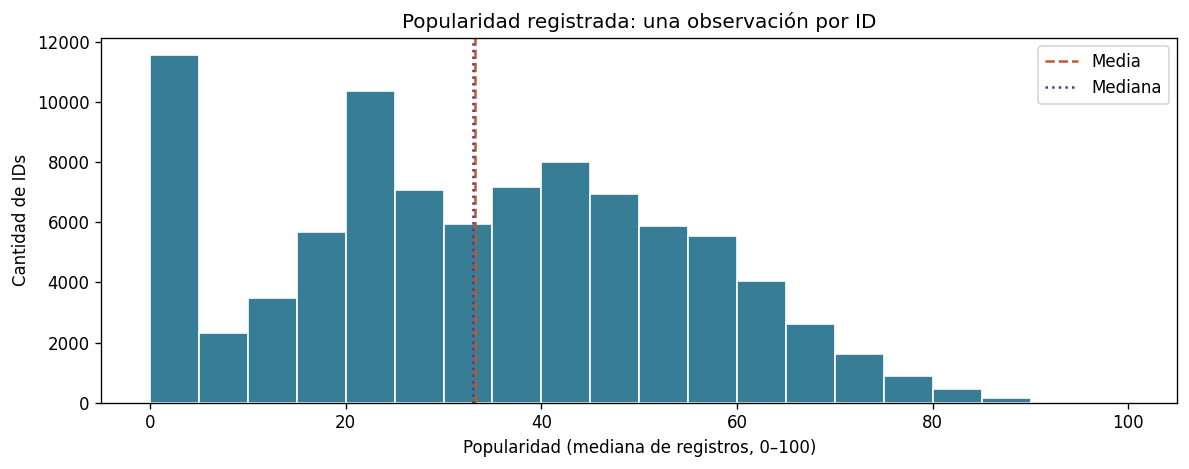

In [47]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(df_canciones["popularity"], bins=20, color="#377D96", edgecolor="white")
ax.axvline(df_canciones["popularity"].mean(), color="#C45926", linestyle="--", label="Media")
ax.axvline(df_canciones["popularity"].median(), color="#553B82", linestyle=":", label="Mediana")
ax.set(title="Popularidad registrada: una observación por ID", xlabel="Popularidad (mediana de registros, 0–100)", ylabel="Cantidad de IDs")
ax.legend()
fig.tight_layout()
plt.show()

### Cómo leer el histograma

- **Eje horizontal:** intervalos de puntajes, no géneros ni fechas.
- **Eje vertical:** cantidad de IDs en cada intervalo.
- **Altura de una barra:** frecuencia, no popularidad media.
- Las líneas ubican media y mediana; no son metas de calidad.

El intervalo próximo a cero contiene tanto valores exactamente cero como otros valores pequeños. Su altura no equivale directamente al conteo exacto de ceros, por eso lo calculamos aparte.

Se observan muchos valores bajos e intermedios y relativamente pocos en el extremo alto. La forma no sigue una campana uniforme: la acumulación cerca de cero merece atención al interpretar el promedio.

Cambiar `bins` modifica la apariencia de las barras, no cambia los datos ni las estadísticas calculadas.

### 15.8 Diagrama de caja e IQR de popularidad

**Línea 1:** `.quantile(0.25)` calcula Q1.

**Línea 2:** `.quantile(0.75)` calcula Q3.

**Línea 3:** la diferencia `q3 - q1` es el rango intercuartílico (IQR).

**Líneas 4 y 5:** construyen los límites de referencia Q1−1,5×IQR y Q3+1,5×IQR.

**Línea 6:** combina con `|` los valores por debajo o por encima de los límites y los cuenta. `.lt()` significa «menor que» y `.gt()` «mayor que».

**Línea 7:** muestra los resultados. Son referencias de detección estadística, no límites de validez de Spotify.

In [48]:
q1 = df_canciones["popularity"].quantile(0.25)
q3 = df_canciones["popularity"].quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr
atipicos_popularidad = (df_canciones["popularity"].lt(limite_inferior) | df_canciones["popularity"].gt(limite_superior)).sum()
pd.Series({"Q1": q1, "Q3": q3, "IQR": iqr, "Límite inferior IQR": limite_inferior, "Límite superior IQR": limite_superior, "IDs fuera de límites IQR": atipicos_popularidad})

Q1                          19.0
Q3                          49.0
IQR                         30.0
Límite inferior IQR        -26.0
Límite superior IQR         94.0
IDs fuera de límites IQR    11.0
dtype: float64

**Resultados:** IQR **30,00**, límite inferior **-26,00** y superior **94,00**. Hay **11 IDs** fuera de esos límites.

El límite inferior puede ser negativo aunque la escala válida comience en cero. Eso no autoriza popularidades negativas: describe una regla estadística diferente.

Los puntajes por encima del límite superior pueden ser válidos dentro de 0–100. **No los eliminamos por ser éxitos poco frecuentes.**

### Dibujar el diagrama de caja

1. `plt.subplots(...)` crea figura y eje.
2. `ax.boxplot(..., vert=False, whis=1.5)` dibuja una caja horizontal con la regla IQR calculada. Los puntos fuera de los bigotes se muestran aparte.
3. `ax.set(...)` define título y eje.
4. `ax.set_yticks([])` quita una etiqueta numérica de grupo innecesaria, porque solo hay una distribución.
5. `tight_layout()` ajusta espacios y `show()` muestra el gráfico.

La caja va de Q1 a Q3 y su línea interna es la mediana. Los bigotes llegan a los valores observados extremos dentro de los límites IQR; **no tienen por qué coincidir exactamente con los límites calculados**.

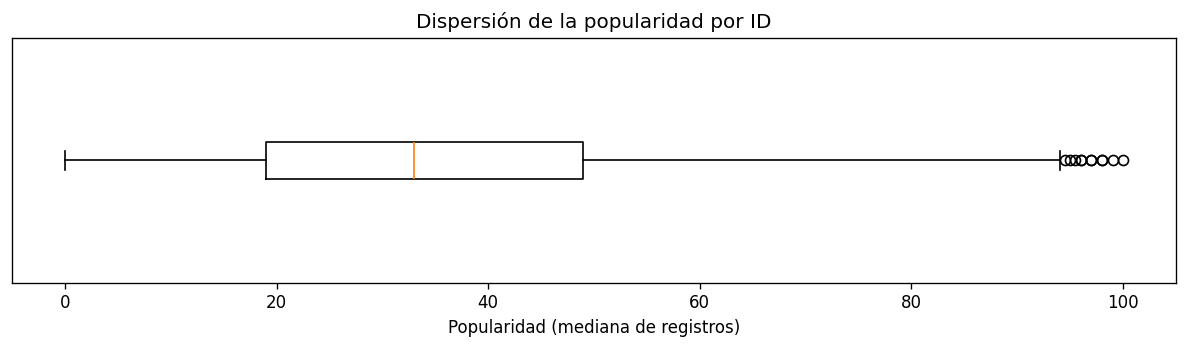

In [49]:
fig, ax = plt.subplots(figsize=(10, 3))
ax.boxplot(df_canciones["popularity"], vert=False, whis=1.5)
ax.set(title="Dispersión de la popularidad por ID", xlabel="Popularidad (mediana de registros)")
ax.set_yticks([])
fig.tight_layout()
plt.show()

### 15.9 Describir las demás medidas con unidades claras

**Línea 1:** `df_canciones["duration_ms"] / 60000` convierte milisegundos a minutos. Guardamos el resultado como columna auxiliar `duration_min` sin cambiar `duration_ms` ni `df_limpio`.

**Línea 2:** una lista selecciona popularidad, duración en minutos y las otras nueve medidas.

**Línea 3:** `.describe()` calcula las estadísticas, `.T` pone una variable por fila y `.round(3)` redondea únicamente la tabla presentada. No redondea ni reemplaza los datos de análisis.

No incluimos tonalidad, modo ni compás en esta tabla de promedios.

In [50]:
df_canciones["duration_min"] = df_canciones["duration_ms"] / 60000
medidas_eda = ["popularity", "duration_min", "danceability", "energy", "loudness", "speechiness", "acousticness", "instrumentalness", "liveness", "valence", "tempo"]
df_canciones[medidas_eda].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
popularity,89740.0,33.198,20.578,0.000,19.000,33.000,49.000,100.000
duration_min,89740.0,3.819,1.882,0.143,2.884,3.555,4.405,87.288
danceability,89740.0,0.562,0.177,0.000,0.450,0.576,0.692,0.985
energy,89740.0,0.634,0.257,0.000,0.457,0.676,0.853,1.000
loudness,89740.0,-8.499,5.222,-49.531,-10.322,-7.185,-5.108,4.532
speechiness,89740.0,0.087,0.113,0.000,0.036,0.049,0.086,0.965
acousticness,89740.0,0.328,0.338,0.000,0.017,0.188,0.625,0.996
instrumentalness,89740.0,0.173,0.324,0.000,0.000,0.000,0.098,1.000
liveness,89740.0,0.217,0.195,0.000,0.098,0.132,0.279,1.000
valence,89740.0,0.469,0.263,0.000,0.249,0.457,0.682,0.995


### Interpretación de la tabla general

- **Duración:** mediana **3,55 minutos**, media **3,82 minutos** y máximo **87,29 minutos**. El máximo muy alto contribuye a que la media supere a la mediana; requiere contexto, no eliminación automática.
- **Bailabilidad:** mediana **0,576** en la escala 0–1. No es el porcentaje de personas que bailaron.
- **Energía:** mediana **0,676** en la escala 0–1. No mide popularidad.
- **Sonoridad:** mediana **-7,185 dB**. Sus unidades y valores negativos no se comparan directamente con escalas 0–1.
- **Instrumentalidad:** mediana **0,000058**. Una mediana cercana a cero indica que al menos la mitad está cerca del extremo de menor instrumentalidad, sin describir por sí sola el resto de la distribución.
- **Tempo:** media **122,27 BPM**, calculada con **89.583 IDs** que tienen tempo disponible. Quedan **157** sin estimación.

`count` permite comprobar cuántos datos participan. Un promedio calculado omitiendo faltantes no equivale a haberlos completado.

Los promedios entre variables no se ordenan para declarar cuál es «más importante»: tienen escalas y significados distintos.

### 15.10 Histogramas de las características musicales

**Línea 1:** la lista `otras_medidas` selecciona las diez características, excluyendo popularidad y usando minutos para duración.

**Línea 2:** `.hist(...)` crea un histograma por columna. `bins=20` fija intervalos; `layout=(5, 2)` distribuye diez gráficos en cinco filas y dos columnas; `figsize=(12, 16)` reserva espacio; `grid=False` oculta la cuadrícula. Los ejes horizontales usan las unidades de cada columna y los verticales cuentan IDs con datos disponibles.

**Línea 3:** `plt.suptitle(...)` añade un título conjunto.

**Línea 4:** `plt.tight_layout(rect=(0, 0, 1, 0.97))` ajusta los paneles dejando espacio para el título.

**Línea 5:** muestra la figura. Pandas omite faltantes en estos histogramas; no crea valores para ellos.

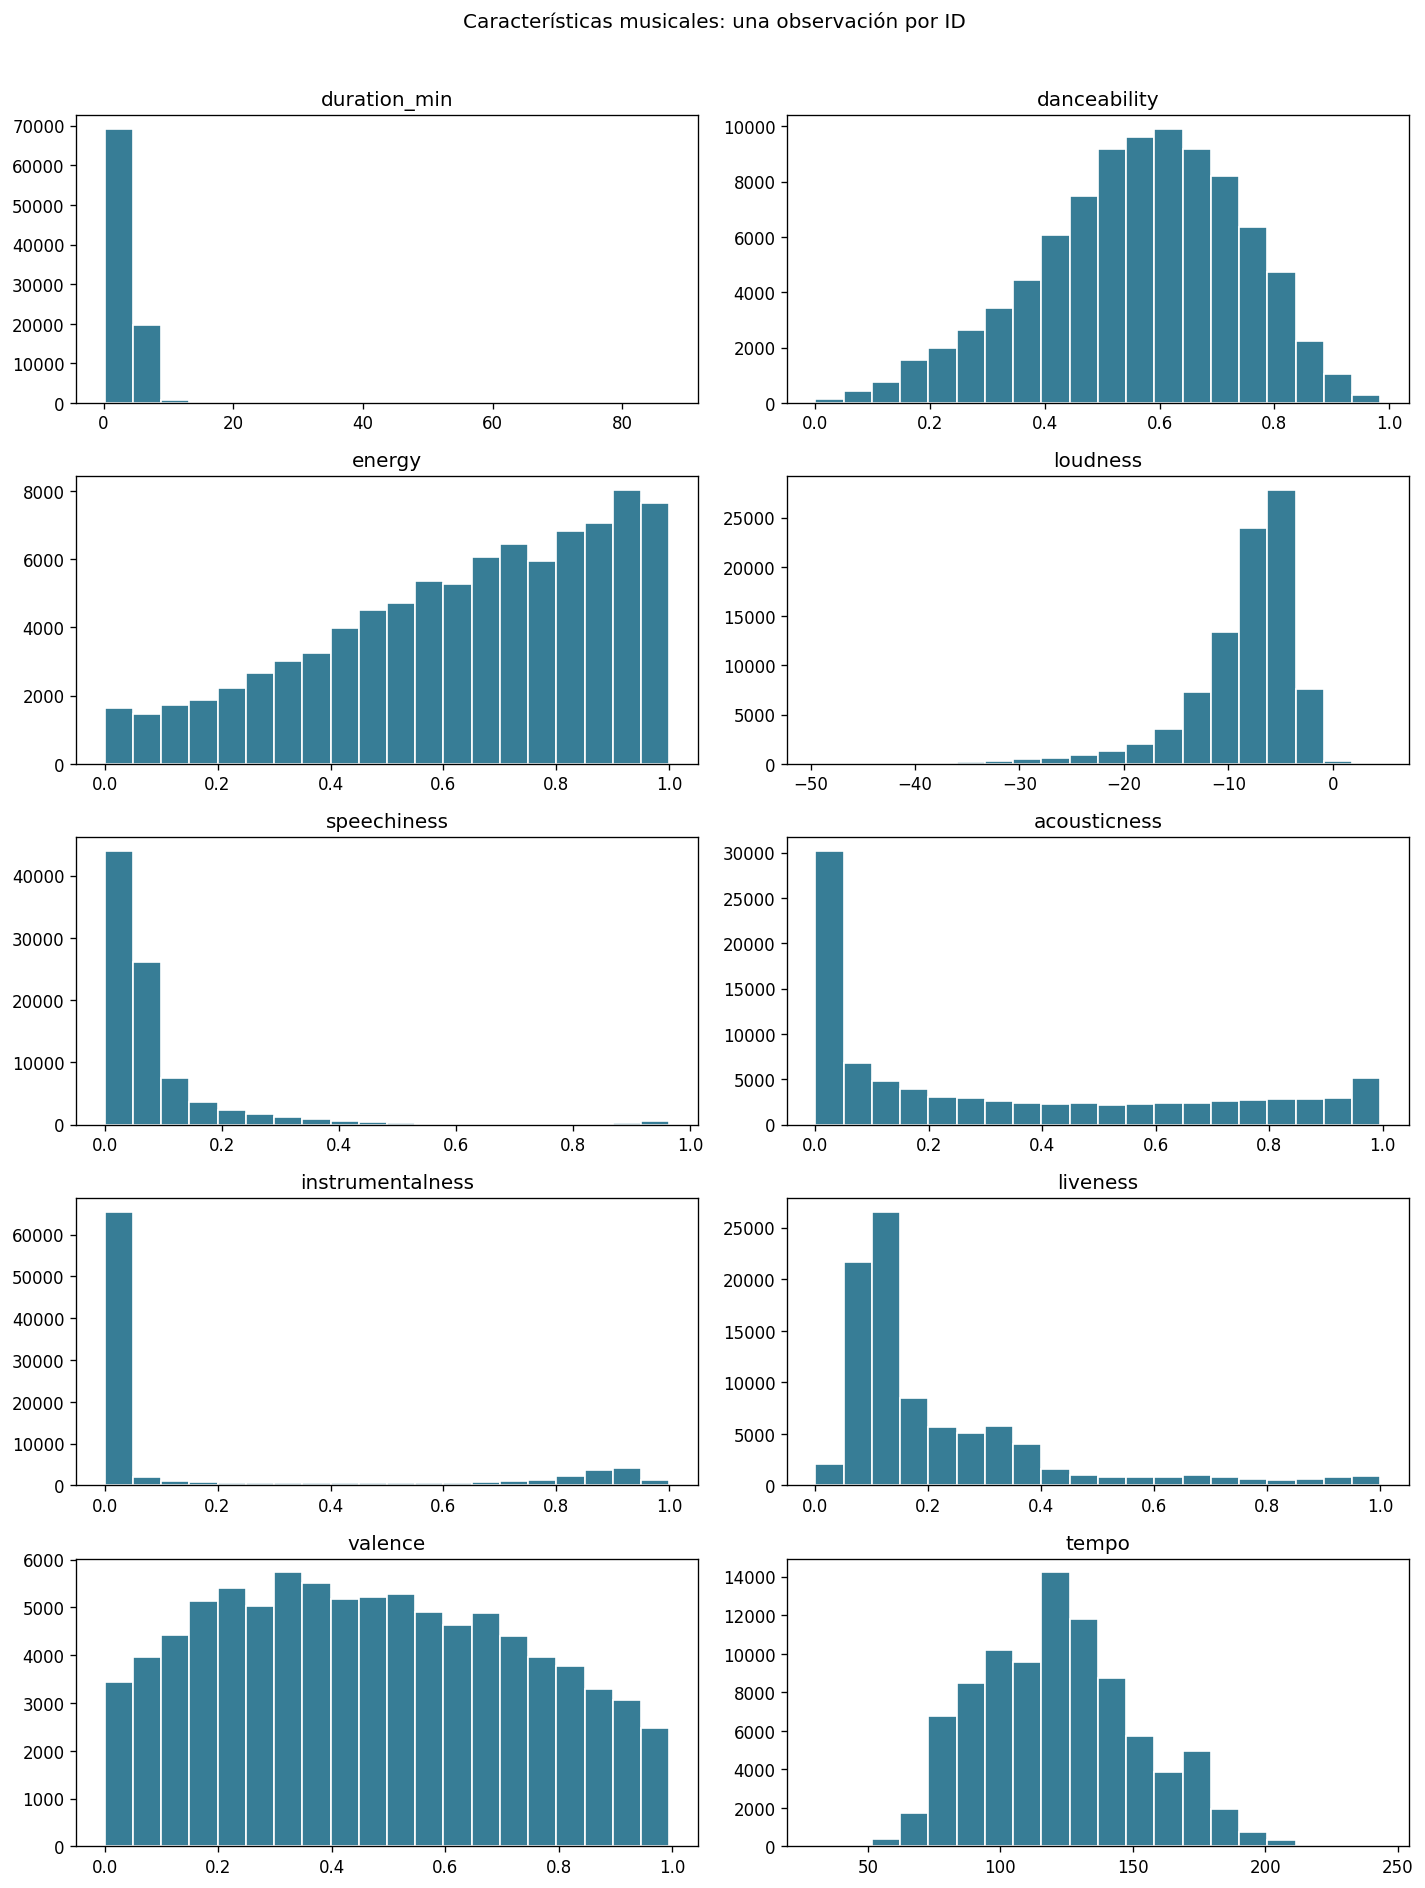

In [51]:
otras_medidas = ["duration_min", "danceability", "energy", "loudness", "speechiness", "acousticness", "instrumentalness", "liveness", "valence", "tempo"]
df_canciones[otras_medidas].hist(bins=20, layout=(5, 2), figsize=(12, 16), grid=False, color="#377D96", edgecolor="white")
plt.suptitle("Características musicales: una observación por ID")
plt.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

### Cómo interpretar los diez histogramas

- **Duración:** una cola larga hacia valores altos puede comprimir visualmente las duraciones habituales. Conservamos la escala completa para no ocultar extremos.
- **Habla, instrumentalidad y presencia en vivo:** observa si hay acumulación en valores bajos; el promedio por sí solo puede ocultar esa concentración.
- **Acusticidad:** observa cómo se reparten valores cercanos a ambos extremos; no presupongas una campana.
- **Energía, bailabilidad y positividad:** compara sus formas dentro de sus escalas, sin convertir sus índices en porcentajes de oyentes.
- **Tempo y sonoridad:** sus ejes tienen unidades diferentes. Una barra alta cuenta IDs, no indica una medida más intensa.

Las alturas no son directamente comparables entre paneles si sus ejes verticales se ajustan por separado. Estos gráficos describen una variable a la vez: no demuestran relaciones con popularidad.

### 15.11 Describir categorías sin promediar códigos

**Línea 1:** `categorias_eda` selecciona ID, contenido explícito, modo y compás.

**Línea 2:** agrupa por ID y cuenta categorías distintas, incluyendo ausencias, para comprobar que coinciden entre sus registros.

**Línea 3:** muestra cuántos IDs tienen discrepancias. El resultado observado es cero en estas tres columnas, por lo que conservar una fila por ID mantiene sus valores categóricos sin elegir entre alternativas diferentes.

In [52]:
categorias_eda = ["explicit", "mode", "time_signature"]
variacion_categorias = df_limpio.groupby("track_id")[categorias_eda].nunique(dropna=False)
(variacion_categorias > 1).sum()

explicit          0
mode              0
time_signature    0
dtype: int64

### Crear una tabla y leer sus frecuencias

**Línea 1:** seleccionamos ID y categorías; `.drop_duplicates(subset="track_id")` conserva una fila por ID, ahora que se comprobó la coincidencia de sus categorías. `.copy()` crea una tabla auxiliar.

**Línea 2:** `.value_counts(dropna=False)` cuenta cada categoría de compás, incluyendo ausencias, y `.sort_index()` ordena sus códigos.

El compás 1 permanece como categoría observada con la limitación documentada en la limpieza. `<NA>` indica ausencia explícita, no otro tipo de compás.

In [53]:
df_categorias = df_limpio[["track_id"] + categorias_eda].drop_duplicates(subset="track_id").copy()
df_categorias["time_signature"].value_counts(dropna=False).sort_index()

time_signature
1         846
3        7604
4       79543
5        1585
<NA>      162
Name: count, dtype: Int64

### Graficar frecuencias categóricas

1. `plt.subplots(1, 3, ...)` crea tres paneles en una fila.
2. `for eje, columna in zip(ejes, categorias_eda):` vincula cada eje con una categoría.
3. `.astype("string").fillna("No determinado")` crea etiquetas temporales para mostrar las ausencias; no modifica la tabla limpia.
4. `.value_counts()` cuenta las etiquetas.
5. `.plot.bar(ax=eje, ...)` dibuja un gráfico de barras en el panel correspondiente; `rot=0` deja etiquetas horizontales.
6. `eje.set(...)` asigna título y eje vertical.
7. `tight_layout()` ajusta espacios y `show()` muestra la figura.

A diferencia de un histograma, cada barra representa aquí una categoría separada.

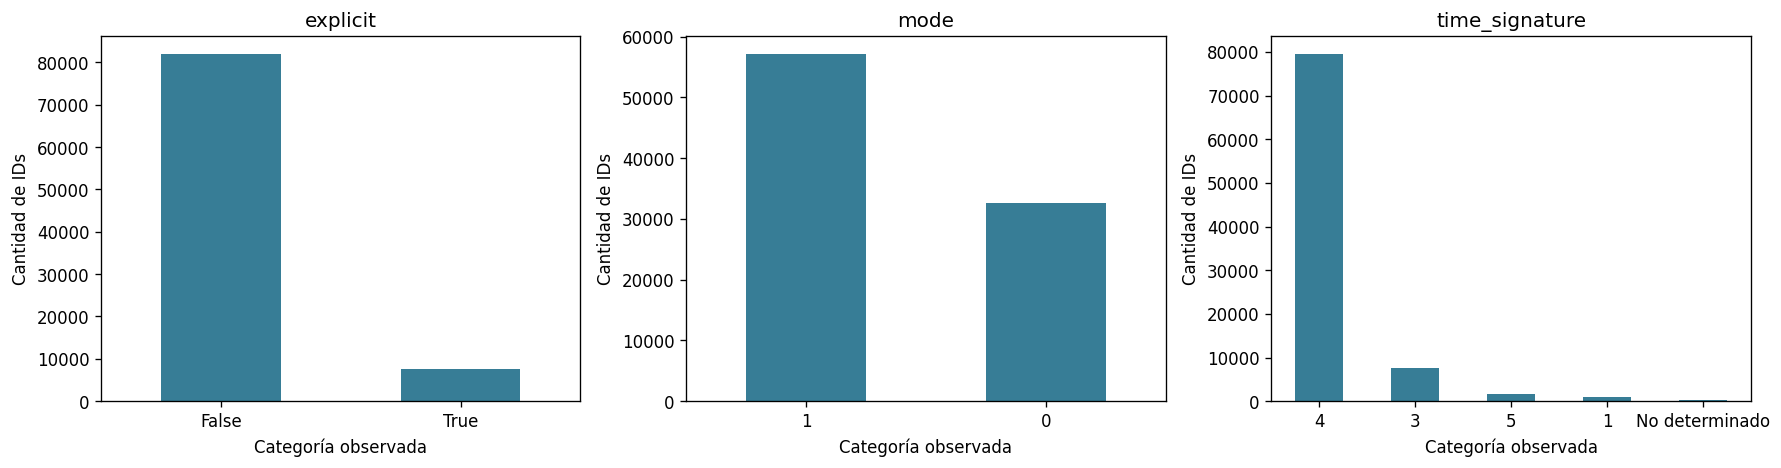

In [54]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, columna in zip(ejes, categorias_eda):
    etiquetas = df_categorias[columna].astype("string").fillna("No determinado")
    frecuencias = etiquetas.value_counts()
    frecuencias.plot.bar(ax=eje, color="#377D96", rot=0)
    eje.set(title=columna, xlabel="Categoría observada", ylabel="Cantidad de IDs")
fig.tight_layout()
plt.show()

### Interpretación de las categorías

En contenido explícito, `False` es «no marcado como explícito», no una garantía de comprobación manual. En modo, **0=menor** y **1=mayor**; no son cantidades que deban compararse como dobles o mitades.

En compás, observa qué categoría concentra más IDs y cuánto representan los no determinados. Las frecuencias de esta tabla pueden diferir de la auditoría porque ahora contamos **IDs una sola vez**, no registros.

Estos gráficos no muestran si una categoría tiene mayor popularidad: muestran cuántos IDs pertenecen a cada categoría.

### 15.12 Contar presencia de géneros sin perder etiquetas

**Línea 1:** seleccionamos `track_id` y `track_genre`; `.drop_duplicates()` conserva un par ID–género una sola vez. Un ID puede conservar varios pares con distintos géneros.

**Línea 2:** `.groupby("track_genre").size()` cuenta IDs asociados a cada género. `.sort_values(ascending=False)` ordena de mayor a menor.

**Línea 3:** `.head(10)` muestra diez géneros con mayor presencia; no necesariamente son un top único si hay empates.

No usamos el primer género de cada ID como si fuera su única etiqueta.

In [55]:
pares_genero = df_limpio[["track_id", "track_genre"]].drop_duplicates()
presencia_generos = pares_genero.groupby("track_genre").size().sort_values(ascending=False)
presencia_generos.head(10)

track_genre
acoustic      1000
rock          1000
funk          1000
garage        1000
industrial    1000
j-rock        1000
mandopop      1000
metalcore     1000
mpb           1000
pagode        1000
dtype: int64

### Graficar la presencia de diez géneros

**Línea 1:** crea figura y eje.

**Línea 2:** toma diez conteos, los ordena de menor a mayor para la presentación y dibuja barras horizontales con `.plot.barh(...)`.

**Línea 3:** asigna título y unidades.

**Líneas 4 y 5:** ajustan el espacio y muestran el gráfico.

**Interpretación:** cuenta IDs asociados a cada etiqueta. Un ID puede sumar en varias barras. Por eso la suma de conteos de todos los géneros puede superar 89.740 y sus porcentajes no tendrían que sumar 100%.

La representación de géneros de este dataset no es una medida de su popularidad mundial ni de su consumo en Spotify. En caso de empates, la selección de diez no establece superioridad sobre los géneros empatados que no se muestran.

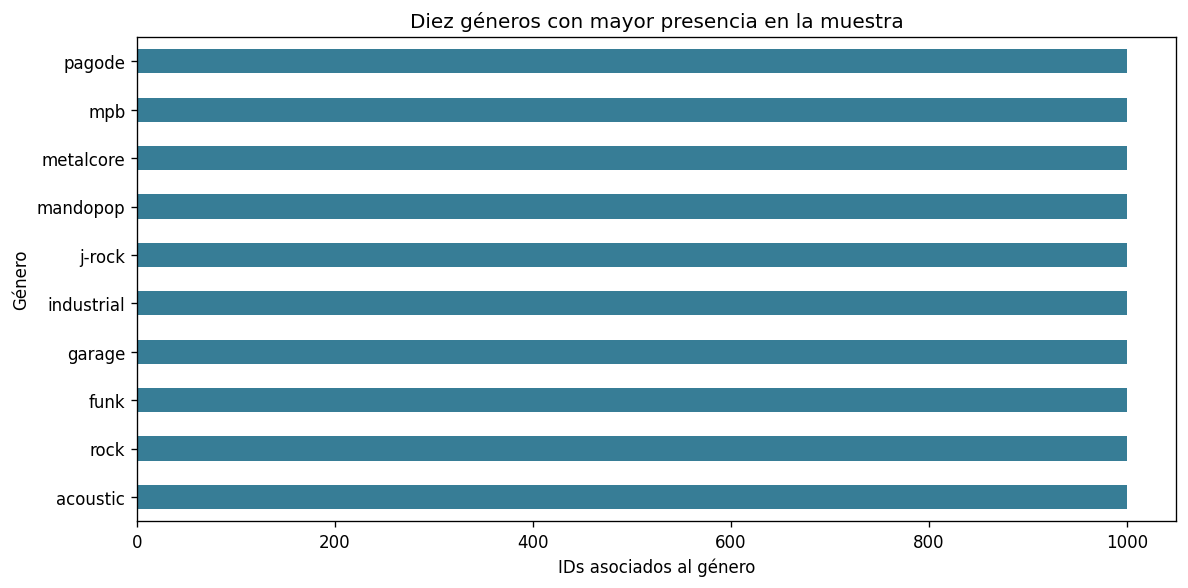

In [56]:
fig, ax = plt.subplots(figsize=(10, 5))
presencia_generos.head(10).sort_values().plot.barh(ax=ax, color="#377D96")
ax.set(title="Diez géneros con mayor presencia en la muestra", xlabel="IDs asociados al género", ylabel="Género")
fig.tight_layout()
plt.show()

## 16. Conclusiones del análisis descriptivo

1. La base limpia conserva **113.549 registros**; las distribuciones globales se describieron con **89.740 IDs** para no dar más peso a canciones con más filas.
2. **720 IDs** presentan popularidades discrepantes. La mediana por ID permite resumirlas de forma explícita, sin afirmar que recupera su valor correcto o más reciente.
3. La popularidad resumida tiene media **33,20**, mediana **33,00** y una mitad central aproximadamente entre **19,00 y 49,00** puntos.
4. **10,47%** de los IDs tiene popularidad resumida cero; el extremo alto es menos frecuente. No se descartaron valores por ser poco comunes.
5. La regla IQR identifica **11 IDs** atípicos en popularidad. No son automáticamente errores y permanecen en el análisis.
6. La duración presenta valores extremos y los histogramas muestran que las variables tienen formas diferentes. No se supone normalidad para todas ellas.
7. Tempo y compás mantienen ausencias explícitas. Los conteos válidos deben acompañar sus estadísticas.
8. Los géneros son etiquetas múltiples: sus frecuencias se analizaron mediante pares ID–género.

**Lo que todavía no podemos afirmar:** qué característica causa popularidad, qué variable predice mejor o cómo funcionaría un modelo. Para explorar asociaciones necesitaremos comparar variables; para evaluar predicción habrá que diseñar un modelamiento posterior.

`df_limpio` y el CSV original permanecen sin cambios durante este análisis. Las tablas y conversiones de unidades se hicieron en objetos auxiliares.

**Preguntas de comprensión:**

- ¿Qué diferencia hay entre una fila de `df_limpio` y una de `df_canciones`?
- ¿Por qué resumimos popularidad por ID y qué limitación introduce esa decisión?
- ¿Por qué la media no describe toda la distribución?
- ¿Qué diferencia hay entre la desviación estándar de popularidad y el error de un modelo?
- ¿Por qué un punto fuera del bigote puede ser válido?
- ¿Por qué las frecuencias de géneros pueden sumar más que el total de IDs?

**Siguiente etapa:** explorar relaciones entre características y popularidad, manteniendo explícitas la unidad de análisis y las limitaciones.

<a id="relaciones" ></a>

## 17. Relaciones entre características y popularidad

**Pregunta:** ¿cómo se asocian las características musicales con la popularidad registrada en esta muestra?

Usaremos **una observación por ID** en `df_canciones`. Para los 720 IDs con popularidades discrepantes se mantiene la mediana de sus registros, con la limitación ya documentada. `df_limpio` y el CSV original no se modifican.

La exploración usa toda la muestra disponible. Si después se construye un modelo, su evaluación final necesitará datos independientes que no se hayan usado para tomar decisiones de desarrollo.

**Asociación:** dos variables presentan un patrón conjunto.

**Causalidad:** modificar una variable produce un cambio en otra. Este análisis observacional no permite demostrarlo: pueden intervenir género, artista, antigüedad, promoción y otros factores que no estamos controlando.

### 17.1 Qué mide la correlación de Pearson

La correlación **r de Pearson** resume la dirección y fuerza de una relación **lineal** entre dos variables cuantitativas.

| Valor | Lectura |
|---|---|
| Cercano a +1 | Tendencia lineal creciente marcada |
| Cercano a −1 | Tendencia lineal decreciente marcada |
| Cercano a 0 | Poca relación lineal global |

**Ejemplo ficticio:** r=−0,10 no significa que subir una variable reduzca la otra un 10%. Es un índice sin unidades, no una pendiente ni un porcentaje de explicación.

La fuerza se aprecia por la distancia a cero, sin olvidar el contexto. No fijaremos un corte universal de «bueno/malo». Una correlación puede ser pequeña y estar calculada correctamente.

Un valor cercano a cero no descarta relaciones curvas, diferencias entre grupos o interacciones. Pearson puede ser sensible a extremos y no garantiza capacidad predictiva para canciones futuras.

**No calcularemos Pearson con IDs ni con códigos de tonalidad y compás.** Que se almacenen como números no los convierte en medidas continuas.

### 17.2 Calcular las correlaciones numéricas

**Línea 1:** `datos_correlacion = df_canciones[medidas_eda].copy()` selecciona popularidad, duración en minutos y las otras nueve medidas. `.copy()` crea una tabla auxiliar.

**Línea 2:** `.corr(method="pearson")` calcula una correlación para cada par de columnas. Pandas usa los valores disponibles en ambas columnas para cada par: no rellena los faltantes ni elimina automáticamente una fila de todas las comparaciones.

**Línea 3:** `.round(3)` muestra tres decimales. El redondeo no cambia `matriz_correlacion`.

En la diagonal cada variable se compara consigo misma y da 1. La matriz es simétrica: energía–popularidad tiene el mismo valor que popularidad–energía. Un `NaN`, si apareciera, podría indicar datos insuficientes o una variable constante; no se interpreta como cero.

In [57]:
datos_correlacion = df_canciones[medidas_eda].copy()
matriz_correlacion = datos_correlacion.corr(method="pearson")
matriz_correlacion.round(3)

,popularity,duration_min,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
popularity,1.000,-0.023,0.064,0.014,0.072,-0.047,-0.039,-0.127,-0.014,-0.012,0.009
duration_min,-0.023,1.000,-0.064,0.063,0.000,-0.061,-0.108,0.117,0.008,-0.147,0.023
danceability,0.064,-0.064,1.000,0.144,0.272,0.110,-0.177,-0.195,-0.132,0.493,-0.045
energy,0.014,0.063,0.144,1.000,0.759,0.141,-0.733,-0.181,0.189,0.256,0.249
loudness,0.072,0.000,0.272,0.759,1.000,0.055,-0.583,-0.435,0.077,0.289,0.215
speechiness,-0.047,-0.061,0.110,0.141,0.055,1.000,0.005,-0.100,0.225,0.033,-0.001
acousticness,-0.039,-0.108,-0.177,-0.733,-0.583,0.005,1.000,0.096,-0.019,-0.104,-0.220
instrumentalness,-0.127,0.117,-0.195,-0.181,-0.435,-0.100,0.096,1.000,-0.087,-0.331,-0.047
liveness,-0.014,0.008,-0.132,0.189,0.077,0.225,-0.019,-0.087,1.000,0.012,0.003
valence,-0.012,-0.147,0.493,0.256,0.289,0.033,-0.104,-0.331,0.012,1.000,0.079


### 17.3 Aislar la relación de cada característica con popularidad

**Línea 1:** selecciona la columna `popularity` de la matriz y `.drop("popularity")` retira de esa Serie la autocorrelación 1. No elimina la variable de los datos.

**Línea 2:** `.notna()` marca los valores presentes de cada columna. `.sum()` cuenta sus observaciones disponibles. Aquí popularidad está completa; por eso este conteo coincide con los pares disponibles para cada relación con popularidad.

**Línea 3:** `pd.DataFrame({...})` reúne correlación, valor absoluto y cantidad de pares.

**Línea 4:** `.sort_values("magnitud", ascending=False)` ordena por distancia a cero, no solo por los valores positivos.

**Línea 5:** muestra la tabla redondeada. Ordenar por magnitud no establece importancia causal ni selecciona automáticamente variables de un futuro modelo.

In [58]:
correlacion_popularidad = matriz_correlacion["popularity"].drop("popularity")
pares_disponibles = datos_correlacion.notna().sum().drop("popularity")
resumen_correlaciones = pd.DataFrame({"r_Pearson": correlacion_popularidad, "magnitud": correlacion_popularidad.abs(), "IDs_con_datos": pares_disponibles})
resumen_correlaciones = resumen_correlaciones.sort_values("magnitud", ascending=False)
resumen_correlaciones.round(4)

,r_Pearson,magnitud,IDs_con_datos
instrumentalness,-0.1275,0.1275,89740
loudness,0.0717,0.0717,89740
danceability,0.0643,0.0643,89740
speechiness,-0.0471,0.0471,89740
acousticness,-0.0389,0.0389,89740
duration_min,-0.0232,0.0232,89740
liveness,-0.0139,0.0139,89740
energy,0.0138,0.0138,89740
valence,-0.0115,0.0115,89740
tempo,0.0088,0.0088,89583


### Cómo interpretar la tabla con popularidad

La mayor magnitud observada corresponde a **instrumentalness**, con **r=-0,127**. Su magnitud es aproximadamente **0,127**; las otras nueve características tienen magnitudes inferiores a **0,10** en esta muestra.

Por tanto, **no aparece una relación lineal global marcada entre una característica individual y la popularidad**. Esto no significa que el sonido no importe, ni que sea imposible construir un modelo con varias variables.

Cada fila indica cuántos IDs participan. Tempo utiliza **89.583 pares**, porque 157 IDs no tienen estimación disponible; las otras características utilizan **89.740 pares**.

No llamaremos a estas correlaciones «porcentaje de acierto», «porcentaje de influencia» ni «aporte causal». Tampoco calculamos aquí pruebas de significación estadística o intervalos de confianza.

### 17.4 Graficar las correlaciones con popularidad

1. `plt.subplots(figsize=(10, 6))` crea la figura y el eje.
2. Seleccionamos `r_Pearson` y ordenamos sus valores para colocar las barras horizontalmente.
3. `.plot.barh(...)` dibuja una barra por característica.
4. `ax.axvline(0, ...)` marca la referencia de ausencia de relación lineal.
5. `ax.set(...)` fija título, unidades y rango **−1 a 1**, toda la escala de Pearson. Esto evita exagerar visualmente diferencias pequeñas.
6. `tight_layout()` ajusta espacios y `show()` muestra la figura.

Las barras a la izquierda son asociaciones negativas y a la derecha positivas; la longitud representa magnitud, no calidad.

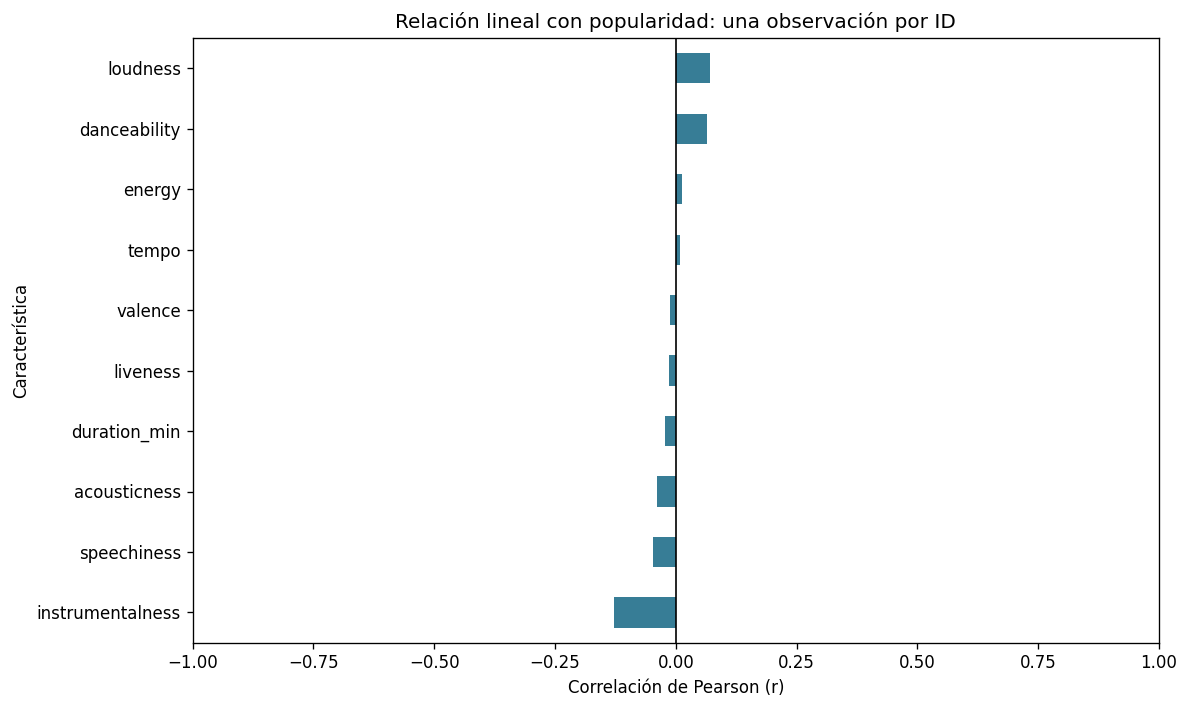

In [59]:
fig, ax = plt.subplots(figsize=(10, 6))
correlaciones_ordenadas = resumen_correlaciones["r_Pearson"].sort_values()
correlaciones_ordenadas.plot.barh(ax=ax, color="#377D96")
ax.axvline(0, color="black", linewidth=1)
ax.set(title="Relación lineal con popularidad: una observación por ID", xlabel="Correlación de Pearson (r)", ylabel="Característica", xlim=(-1, 1))
fig.tight_layout()
plt.show()

**Lectura del gráfico:** las barras quedan cerca de cero en la escala completa. Una barra negativa más larga indica una tendencia lineal decreciente algo mayor que la de otras variables, pero no demuestra que aumentar esa característica haga caer la popularidad.

Las diferencias pequeñas entre barras no justifican por sí solas decisiones de promoción o selección de canciones.

### 17.5 Mapa de calor entre todas las medidas

**¿Para qué?** La tabla anterior mira solo popularidad. Este mapa permite observar también relaciones entre características, como energía y sonoridad.

**Instrucciones del gráfico:**

1. `plt.subplots(...)` crea figura y eje.
2. `ax.imshow(...)` convierte la matriz en colores. `vmin=-1` y `vmax=1` fijan la escala; `coolwarm` representa negativos en azul y positivos en rojo.
3. `posiciones = range(len(medidas_eda))` prepara las posiciones de las 11 etiquetas.
4. `set_xticks` y `set_yticks` colocan nombres; `rotation=90` gira los del eje horizontal.
5. Los dos bucles `for` recorren filas y columnas de la matriz.
6. `.iloc[fila, columna]` consulta cada valor por posición y `ax.text(...)` lo escribe con dos decimales mediante una cadena `f"...:.2f"`.
7. `ax.set_title(...)` añade el título.
8. `fig.colorbar(...)` muestra la correspondencia entre colores y r.
9. `tight_layout()` ajusta y `show()` muestra.

No hay que interpretar el rojo como «bueno» ni el azul como «malo»: indican signo.

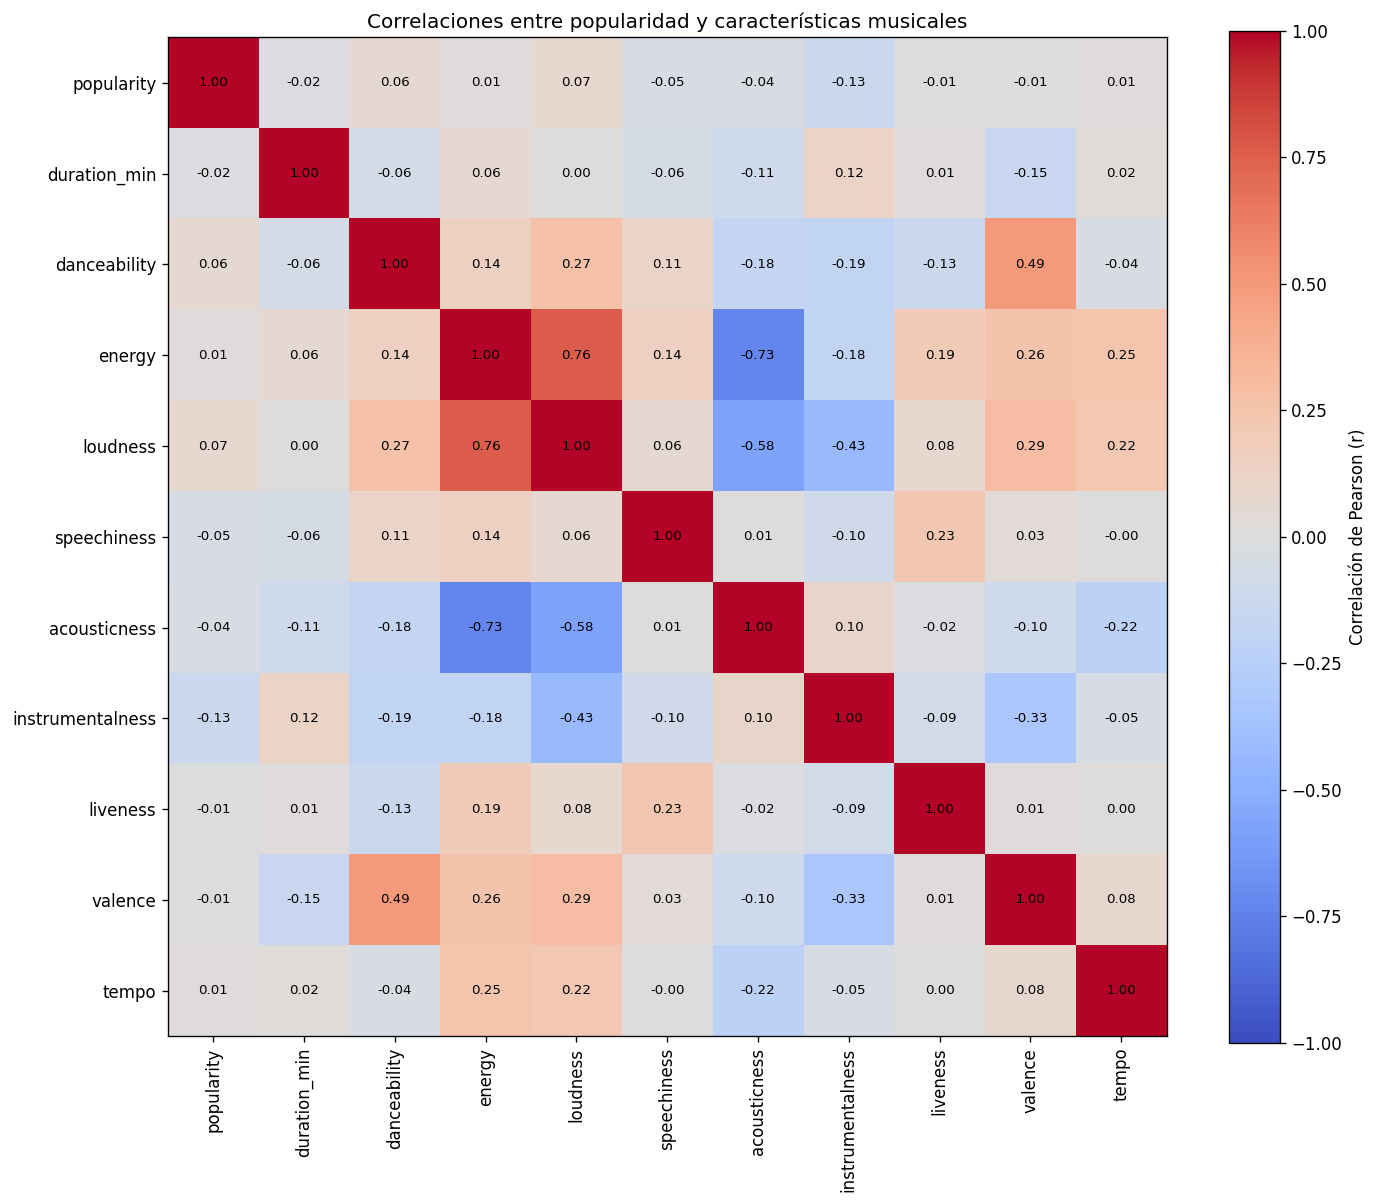

In [60]:
fig, ax = plt.subplots(figsize=(12, 10))
imagen = ax.imshow(matriz_correlacion, cmap="coolwarm", vmin=-1, vmax=1)
posiciones = range(len(medidas_eda))
ax.set_xticks(posiciones, labels=medidas_eda, rotation=90)
ax.set_yticks(posiciones, labels=medidas_eda)
for fila in posiciones:
    for columna in posiciones:
        ax.text(columna, fila, f"{matriz_correlacion.iloc[fila, columna]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Correlaciones entre popularidad y características musicales")
fig.colorbar(imagen, ax=ax, label="Correlación de Pearson (r)")
fig.tight_layout()
plt.show()

### Interpretación de las relaciones entre características

- **Energía–sonoridad: r=0,759.** En esta muestra, las canciones con mayor energía tienden a presentar sonoridad más alta, es decir, valores en dB generalmente menos negativos.
- **Energía–acusticidad: r=-0,733.** Una energía mayor tiende a acompañarse de menor acusticidad.
- La diagonal roja con valores 1 solo es autocorrelación; no es un hallazgo musical.

Estas relaciones entre características son bastante mayores que sus relaciones individuales con popularidad. Eso ayuda a comprender que pueden compartir información.

**Multicolinealidad:** cuando varias predictoras presentan dependencia lineal, interpretar sus coeficientes por separado en un modelo lineal puede ser difícil o inestable. Este mapa permite advertir pares relacionados, pero no demuestra por sí solo toda la dependencia entre varias columnas ni obliga a eliminar una variable.

Ejemplo de frase apropiada: «energía y sonoridad están asociadas». Frase que no podemos sostener aquí: «subir la energía causa mayor sonoridad o mayor popularidad».

### 17.6 Revisar las relaciones con diagramas de dispersión

Con tantos IDs, dibujar todos los puntos puede ocultar la estructura por superposición. Usaremos **una muestra reproducible de hasta 4.000 IDs solo para los gráficos**. Las correlaciones anteriores se calcularon con todos los pares disponibles.

**Línea 1:** `.head(3).index.tolist()` obtiene los nombres de las tres características con mayor magnitud de correlación en la tabla. Es una elección exploratoria, no una selección confirmada para modelar.

**Línea 2:** `.sample(n=min(4000, len(datos_correlacion)), random_state=42)` selecciona hasta 4.000 IDs al azar, sin reemplazo por defecto. `42` fija la semilla para reproducir la selección con la misma tabla; no mejora el resultado.

**Línea 3:** muestra los nombres seleccionados.

In [61]:
variables_graficas = resumen_correlaciones.head(3).index.tolist()
muestra_relaciones = datos_correlacion.sample(n=min(4000, len(datos_correlacion)), random_state=42)
variables_graficas

['instrumentalness', 'loudness', 'danceability']

### Dibujar los tres diagramas

1. `plt.subplots(1, 3, ...)` crea tres paneles. `sharey=True` mantiene el mismo eje de popularidad.
2. `zip(ejes, variables_graficas)` vincula cada panel con una característica.
3. `.dropna()` retira faltantes **solo de la tabla temporal de ese par**. No elimina filas del dataset.
4. `eje.scatter(x, y, ...)` dibuja característica en X y popularidad en Y. `s=7` controla el tamaño visual y `alpha=0.15` hace transparentes los puntos para ver concentraciones.
5. `eje.set(...)` asigna título, etiquetas y límites de popularidad.
6. `plt.suptitle(...)` comunica el muestreo de visualización.
7. `tight_layout()` ajusta el espacio y `show()` presenta la figura.

La muestra aleatoria puede variar en apariencia con otra semilla. Las conclusiones numéricas se apoyan en los datos completos.

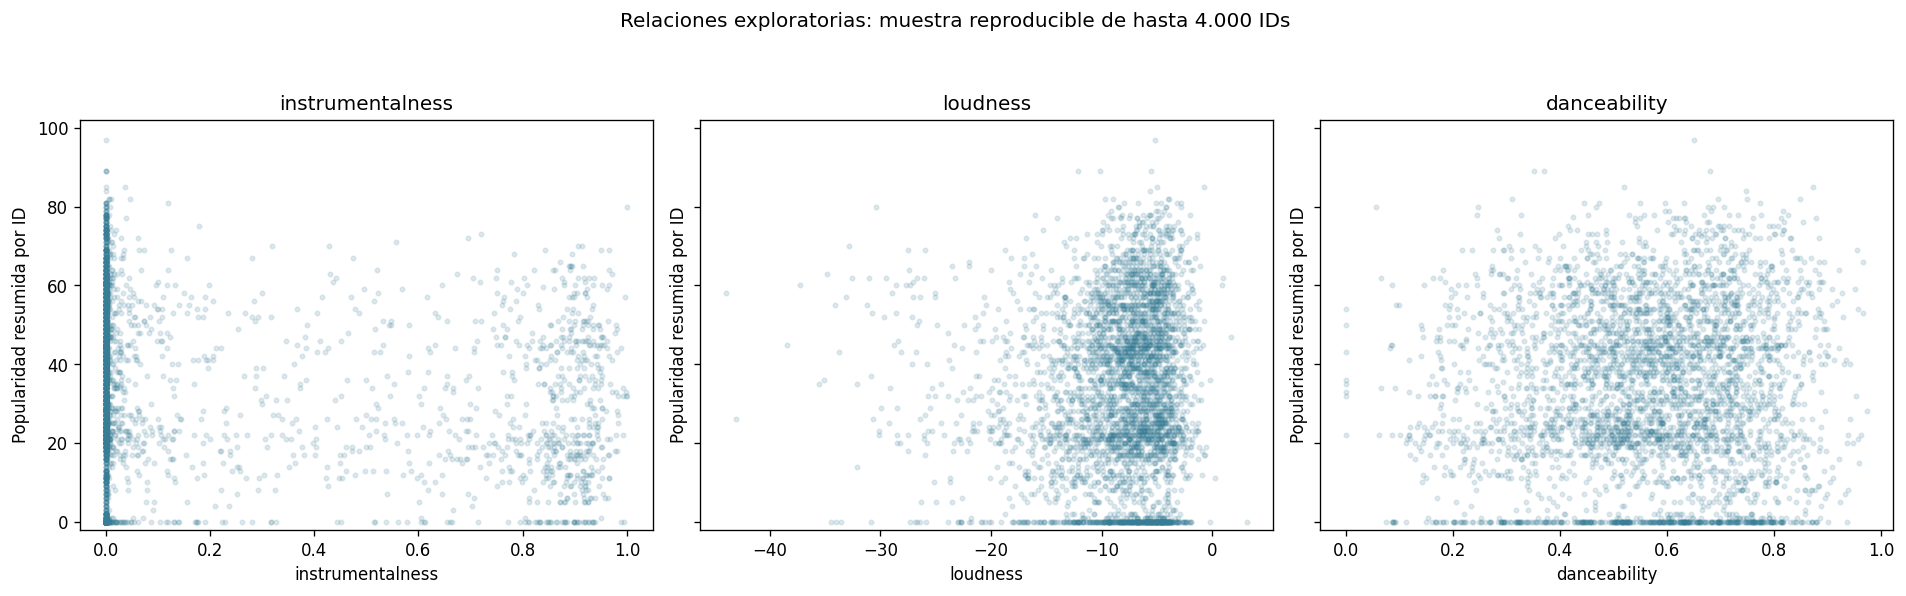

In [62]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for eje, columna in zip(ejes, variables_graficas):
    pares_grafico = muestra_relaciones[[columna, "popularity"]].dropna()
    eje.scatter(pares_grafico[columna], pares_grafico["popularity"], s=7, alpha=0.15, color="#377D96")
    eje.set(title=columna, xlabel=columna, ylabel="Popularidad resumida por ID", ylim=(-2, 102))
plt.suptitle("Relaciones exploratorias: muestra reproducible de hasta 4.000 IDs")
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

### Cómo interpretar los diagramas

Cada punto es un ID de la muestra visual. Si para un mismo valor aproximado de X hay popularidades muy distintas, esa característica por sí sola no determina el puntaje.

Observa si aparece una nube dispersa, una tendencia, concentraciones, curvatura o una acumulación en popularidad cero. Que los puntos se superpongan no implica que haya duplicados exactos.

**Correlación pequeña y nube dispersa son compatibles.** Una correlación cercana a cero tampoco excluye patrones curvos o de subgrupos que necesiten otro análisis.

No añadimos una recta de predicción ni calculamos rendimiento de un modelo. Este gráfico no demuestra cómo cambiaría una canción si alteráramos su audio.

### 17.7 Comparar popularidad entre categorías

Para contenido explícito y modo musical usaremos grupos y diagramas de caja, en lugar de tratar sus códigos como cantidades continuas.

**Línea 1:** `.set_index("track_id")` coloca los IDs como índice en la tabla auxiliar de categorías.

**Línea 2:** `.join(..., validate="one_to_one")` une la popularidad con sus categorías por ID. La validación exige que ambos índices sean únicos: evita multiplicar filas por una unión incorrecta.

**Línea 3:** `.groupby("explicit")["popularity"].agg(["count", "mean", "median", "std"])` calcula cantidad, media, mediana y desviación por categoría.

**Línea 4:** muestra el resumen redondeado. Esta unión no modifica ninguna tabla original.

In [63]:
categorias_por_id = df_categorias.set_index("track_id")
popularidad_categorias = df_canciones[["popularity"]].join(categorias_por_id[["explicit", "mode"]], validate="one_to_one")
resumen_explicit = popularidad_categorias.groupby("explicit")["popularity"].agg(["count", "mean", "median", "std"])
resumen_explicit.round(3)

,count,mean,median,std
explicit,,,,
False,82036,32.852,33.0,20.369
True,7704,36.884,37.0,22.352


### Interpretación de contenido explícito

La media observada es **32,85** para `False` y **36,88** para `True`, con **82.036** y **7.704 IDs**, respectivamente.

Estos grupos tienen tamaños diferentes y pueden diferir en género, artista, fecha o exposición. **La diferencia de medias no demuestra que incluir contenido explícito cause más o menos popularidad.**

`False` significa que el archivo no marca contenido explícito; también puede incluir información desconocida. El promedio y la mediana deben interpretarse junto con el tamaño y la dispersión de cada grupo.

### Resumir el modo musical

**Línea:** `.groupby("mode")["popularity"].agg(["count", "mean", "median", "std"]).round(3)` repite el cálculo por modo.

`mode=0` significa menor y `mode=1` mayor. La comparación no interpreta 1 como una cantidad superior a 0.

In [64]:
popularidad_categorias.groupby("mode")["popularity"].agg(["count", "mean", "median", "std"]).round(3)

,count,mean,median,std
mode,,,,
0,32578,33.641,34.0,20.864
1,57162,32.946,33.0,20.409


### Comparar distribuciones, no solo promedios

1. `plt.subplots(1, 2, ..., sharey=True)` crea dos paneles con la misma escala de popularidad.
2. `zip(...)` vincula cada panel con `explicit` o `mode`.
3. `groupby(columna)` genera pares de nombre de categoría y grupo de registros.
4. La lista `valores_grupo` guarda las series de popularidad; `.dropna()` evita pasar ausencias al gráfico.
5. `etiquetas_grupo` convierte cada categoría en texto para el eje.
6. `eje.boxplot(..., tick_labels=...)` dibuja una caja por categoría, sin equilibrar ni remuestrear sus tamaños.
7. `eje.set(...)` define título, unidades y límites.
8. `tight_layout()` y `show()` presentan la figura.

Los tamaños de muestra se consultan en las tablas: las cajas con igual anchura visual no representan igual cantidad de IDs.

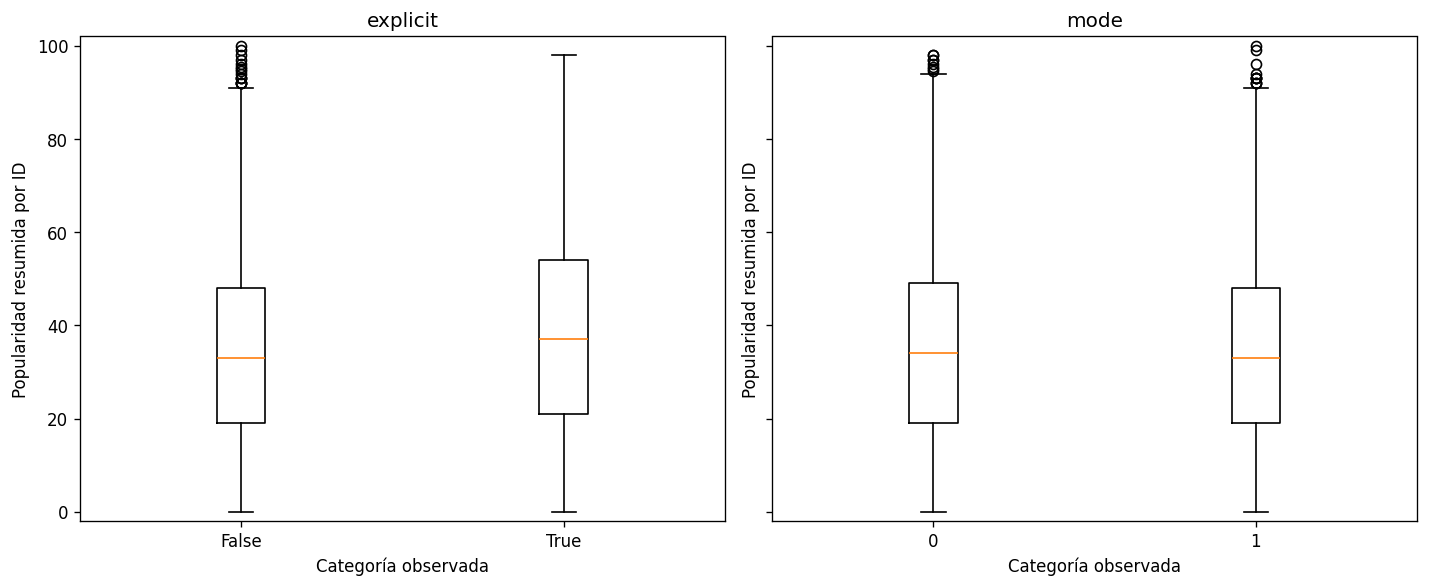

In [65]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for eje, columna in zip(ejes, ["explicit", "mode"]):
    grupos_categoria = list(popularidad_categorias.groupby(columna))
    valores_grupo = [grupo["popularity"].dropna() for etiqueta, grupo in grupos_categoria]
    etiquetas_grupo = [str(etiqueta) for etiqueta, grupo in grupos_categoria]
    eje.boxplot(valores_grupo, tick_labels=etiquetas_grupo)
    eje.set(title=columna, xlabel="Categoría observada", ylabel="Popularidad resumida por ID", ylim=(-2, 102))
fig.tight_layout()
plt.show()

### Interpretación de las cajas por categoría

Compara medianas, altura de las cajas y solapamiento. Si las distribuciones se solapan, pertenecer a una categoría no determina la popularidad individual.

Una diferencia visible no implica una prueba estadística de diferencia, ni un efecto causal. Este análisis no controla otros factores y no aporta intervalos de confianza.

Las cajas son resúmenes descriptivos del dataset. No justifican recomendaciones como «cambiar a modo mayor» o «añadir lenguaje explícito» para aumentar la popularidad.

## 18. Conclusiones de las relaciones exploradas

1. En la base por ID, ninguna de las diez características cuantitativas presenta una correlación lineal individual marcada con popularidad; la mayor magnitud es **instrumentalness, r=-0,127**.
2. Las relaciones entre características pueden ser mayores: energía–sonoridad **0,759** y energía–acusticidad **-0,733**.
3. Los diagramas de dispersión ayudan a revisar forma y dispersión, pero su muestra visual no reemplaza los cálculos completos.
4. Hay diferencias descriptivas de popularidad entre categorías; no se pueden atribuir a un efecto propio de la categoría sin controlar otros factores.
5. Las asociaciones dependen de la muestra, la representación por ID y las decisiones documentadas sobre discrepancias y ausencias.

**Cómo redactar una conclusión prudente:** «En esta muestra se observa una asociación lineal débil entre X y popularidad». No: «X produce popularidad».

**Lo que no hemos hecho:** demostrar causalidad, medir importancia predictiva, probar hipótesis o evaluar modelos. Tampoco eliminamos características por tener r pequeña.

**Preguntas de comprensión:**

- ¿Qué diferencia hay entre r=−0,10 y una reducción de popularidad del 10%?
- ¿Por qué r cercana a cero no descarta una relación curva?
- ¿Por qué tempo utiliza menos pares que energía?
- ¿Qué aporta el mapa completo frente a la columna de popularidad?
- ¿Por qué una diferencia de medias entre categorías no demuestra un efecto causal?
- ¿Por qué no podemos reutilizar sin más esta exploración como evidencia de rendimiento predictivo futuro?

Las tablas originales y el CSV permanecen intactos. Esta sección amplía la comprensión de los datos, sin añadir transformaciones de limpieza.

**Continuación:** representamos los géneros mediante Multi-Hot Encoding y después comparamos dos formas de escalamiento. Ambas tareas crean tablas auxiliares sin reemplazar las medidas originales.

<a id="multihot" ></a>

## 19. Multi-Hot Encoding de géneros musicales

**Objetivo:** construir una tabla con **una fila por ID de canción**, conservando todos sus géneros como columnas binarias.

Una canción puede tener varias etiquetas. Por eso no escogeremos un único género ni crearemos una categoría nueva como «pop-rock» para cada combinación.

| ID ficticio | genero__pop | genero__rock | genero__dance |
|---|---|---|---|
| A | 1 | 1 | 0 |
| B | 1 | 0 | 1 |

**1** indica que el género está registrado para ese ID y **0** que no está registrado en este dataset. Una fila puede tener varios unos. No son probabilidades, porcentajes ni grados de pertenencia.

**One-Hot:** una categoría por observación genera normalmente un único uno en ese bloque. **Multi-Hot:** varias etiquetas por observación permiten varios unos.

Trabajaremos con tablas auxiliares. El CSV, `df` y `df_limpio` permanecen intactos. El ID identifica una canción en la fuente; no garantiza una única obra o grabación entre reediciones.

### 19.1 Recuperar pares únicos de canción y género

**Línea 1:** `df_limpio[["track_id", "track_genre"]]` selecciona ambas columnas. `.drop_duplicates()` conserva cada combinación ID–género una vez. `.copy()` crea una tabla auxiliar independiente.

No usamos `drop_duplicates(subset="track_id")`: eso podría perder géneros de una canción.

**Línea 2:** `pares_multihot.isna().sum()` cuenta faltantes por columna antes de cruzarlas. Si hubiera faltantes, sería necesario resolver su tratamiento antes de codificar, porque el cruce podría omitirlos.

**Resultado observado:** no hay IDs ni etiquetas de género nulos en estos pares.

In [66]:
pares_multihot = df_limpio[["track_id", "track_genre"]].drop_duplicates().copy()
pares_multihot.isna().sum()

track_id       0
track_genre    0
dtype: int64

### 19.2 Crear la tabla de presencia de géneros

**Línea 1:** `pd.crosstab(...)` construye una tabla cruzada: los valores de `track_id` son sus filas y los valores de `track_genre` sus columnas. Cada celda cuenta pares de esa combinación. Al partir de pares únicos, cada combinación presente cuenta una vez.

**Línea 2:** `.gt(0)` convierte un conteo positivo en `True` y cero en `False`. `.astype("int8")` los representa como enteros 1 y 0, usando ocho bits por valor.

El paso explícito a presencia garantiza que la representación sea binaria: nunca interpretamos una repetición como «dos veces más pertenencia».

**Línea 3:** `.shape` muestra cantidad de IDs y géneros. El ID queda como índice, que identifica la fila sin ser una columna de género.

In [67]:
conteos_generos = pd.crosstab(pares_multihot["track_id"], pares_multihot["track_genre"])
generos_multihot = conteos_generos.gt(0).astype("int8")
generos_multihot.shape

(89740, 114)

**Resultado:** **89.740 filas y 114 columnas de género**. Cada fila representa un ID, y cada columna una etiqueta musical. No se crean 114 modelos ni 114 canciones por ID.

### 19.3 Identificar las columnas de género

**Línea 1:** `.add_prefix("genero__")` añade el prefijo a los nombres de columnas y asigna el resultado a la tabla auxiliar. No cambia los nombres de género en `df_limpio` ni los valores 0/1.

**Línea 2:** `.iloc[:5, :8]` muestra las primeras cinco filas y ocho columnas por posición. Los límites finales 5 y 8 no se incluyen.

El prefijo facilita reconocer las 114 columnas al unirlas con otras características. No significa que `pop` y `genero__pop` sean géneros distintos.

In [68]:
generos_multihot = generos_multihot.add_prefix("genero__")
generos_multihot.iloc[:5, :8]

track_genre,genero__acoustic,genero__afrobeat,genero__alt-rock,genero__alternative,genero__ambient,genero__anime,genero__black-metal,genero__bluegrass
track_id,,,,,,,,
0000vdREvCVMxbQTkS888c,0,0,0,0,0,0,0,0
000CC8EParg64OmTxVnZ0p,0,0,0,0,0,0,0,0
000Iz0K615UepwSJ5z2RE5,0,0,0,0,0,0,0,0
000RDCYioLteXcutOjeweY,0,0,0,0,0,0,0,0
000qpdoc97IMTBvF8gwcpy,0,0,0,0,0,0,0,0


### Interpretar la vista parcial

Un cero significa ausencia de esa etiqueta registrada, no falta de datos ni incompatibilidad musical.

Una fila puede mostrar solo ceros **en las ocho columnas visibles** y tener unos en otras columnas no mostradas. Esta vista no basta para concluir que una canción carece de géneros.

Los IDs aparecen como etiquetas del índice. El orden de filas o columnas no representa popularidad ni importancia.

### 19.4 Contar géneros por canción

**Línea 1:** `generos_multihot.sum(axis=1)` suma los 114 indicadores dentro de cada fila. `axis=1` recorre las columnas: el resultado es la cantidad de géneros registrados para cada ID.

**Línea 2:** `.value_counts()` cuenta cuántos IDs tienen uno, dos, tres o más géneros; `.sort_index()` ordena por esa cantidad.

Aquí el índice de la salida es **cantidad de géneros por ID** y el valor es **cantidad de IDs**. No es un conteo de popularidad.

In [69]:
cantidad_generos = generos_multihot.sum(axis=1)
cantidad_generos.value_counts().sort_index()

1    73441
2    11424
3     2955
4     1361
5      431
6      104
7       21
8        2
9        1
Name: count, dtype: int64

**Resultados:** hay **16.299 IDs con más de un género**, aproximadamente **18,16%** del total. El máximo observado es **9 géneros** para un ID.

Estos son conteos descriptivos. No indican que todas las canciones de Spotify tengan esa distribución ni que más géneros impliquen más popularidad.

### 19.5 Comprobar una canción con varios géneros

**Línea 1:** `cantidad_generos.gt(1)` selecciona IDs con más de una etiqueta. `.index[0]` toma el primero como ejemplo. El paso presupone que existen casos, como confirmó el conteo anterior.

**Línea 2:** `.eq(id_multigenero)` crea una máscara y `.loc[..., "track_genre"]` obtiene sus géneros desde los pares originales. `.sort_values().tolist()` los ordena y muestra como lista.

El ejemplo no es una canción elegida por popularidad ni una muestra representativa: sirve para verificar la transformación.

In [70]:
id_multigenero = cantidad_generos[cantidad_generos.gt(1)].index[0]
pares_multihot.loc[pares_multihot["track_id"].eq(id_multigenero), "track_genre"].sort_values().tolist()

['chill', 'soul']

### Leer sus indicadores activos

**Línea 1:** `.loc[id_multigenero]` obtiene la fila codificada de ese ID.

**Línea 2:** `.eq(1)` marca sus géneros activos y el filtro muestra únicamente esas columnas.

Los nombres, quitando el prefijo, deben coincidir con la lista anterior. Las 114 columnas siguen existiendo, aunque ahora mostramos solo las activas.

In [71]:
fila_multihot = generos_multihot.loc[id_multigenero]
fila_multihot[fila_multihot.eq(1)]

track_genre
genero__chill    1
genero__soul     1
Name: 001APMDOl3qtx1526T11n1, dtype: int8

### 19.6 Revisar estructura y valores binarios

**Línea 1:** `pd.Series({...})` reúne las comprobaciones con nombres comprensibles.

- `.index.is_unique`: confirma que cada ID aparece una sola vez.
- Comparar `len(...)` con `.nunique()` verifica el total esperado de IDs.
- `.isin([0, 1]).all().all()` verifica primero todas las filas de cada columna y después todas las columnas.
- `.ge(1).all()` confirma que cada ID tiene al menos un género.
- `.sum().sum()` suma todos los unos y los compara con la cantidad de pares únicos.

**Línea 2:** muestra los resultados. Esperamos `True` en todas. Estos controles revisan estructura y conteos; después comprobaremos también que las etiquetas correspondan a los IDs correctos.

In [72]:
comprobaciones_multihot = pd.Series({
    "Índice de ID sin duplicados": generos_multihot.index.is_unique,
    "Cantidad de IDs coincide con la fuente limpia": len(generos_multihot) == df_limpio["track_id"].nunique(),
    "Solo valores 0 y 1": generos_multihot.isin([0, 1]).all().all(),
    "Cada ID tiene al menos un género": cantidad_generos.ge(1).all(),
    "Total de unos coincide con pares ID–género": generos_multihot.sum().sum() == len(pares_multihot)
})
comprobaciones_multihot

Índice de ID sin duplicados                      True
Cantidad de IDs coincide con la fuente limpia    True
Solo valores 0 y 1                               True
Cada ID tiene al menos un género                 True
Total de unos coincide con pares ID–género       True
dtype: bool

### 19.7 Comprobar que ningún género se asoció a IDs incorrectos

Igualar totales no basta: dos etiquetas intercambiadas podrían conservar las sumas. Comparamos por género **el conjunto exacto de IDs** antes y después.

**Línea 1:** crea una lista para los resultados.

**Línea 2:** el bucle recorre los nombres de género de la tabla de conteos, sin prefijos.

**Línea 3:** `.loc` selecciona los IDs que tenían ese género y `set(...)` crea su conjunto, sin importar el orden.

**Línea 4:** construye el nombre de la columna codificada y selecciona los IDs cuyo indicador vale 1.

**Línea 5:** documenta si ambos conjuntos son iguales y sus tamaños.

**Línea 6:** convierte el registro en tabla y usa el género como índice.

**Línea 7:** cuenta `True` y `False` en la comprobación. Se espera coincidencia en los 114 géneros.

No comparamos solo una canción de ejemplo: verificamos todos los pares, sin reconstruir una tabla enorme de combinaciones ausentes.

In [73]:
revision_etiquetas = []
for genero in conteos_generos.columns:
    ids_esperados = set(pares_multihot.loc[pares_multihot["track_genre"].eq(genero), "track_id"])
    ids_codificados = set(generos_multihot.index[generos_multihot["genero__" + genero].eq(1)])
    revision_etiquetas.append({"genero": genero, "IDs_originales": len(ids_esperados), "IDs_codificados": len(ids_codificados), "coinciden": ids_esperados == ids_codificados})
verificacion_generos = pd.DataFrame(revision_etiquetas).set_index("genero")
verificacion_generos["coinciden"].value_counts()

coinciden
True    114
Name: count, dtype: int64

**Resultado:** **114 coincidencias y ninguna discrepancia**. Para cada género, los IDs con indicador 1 son exactamente los que lo tenían registrado en `pares_multihot`.

Esto verifica la conservación de las etiquetas de la fuente limpia, no la exactitud musical de cómo la fuente etiquetó cada canción.

### 19.8 Unir características, popularidad y todos los géneros

**Línea 1:** `.set_index("track_id")[categorias_eda]` prepara las tres categorías ya comprobadas por ID: contenido explícito, modo y compás.

**Línea 2:** `.join(..., how="left", validate="one_to_one")` une las medidas de `df_canciones` con esas categorías por ID. `left` conserva los IDs de la tabla de medidas; la validación impide duplicaciones de ID en la unión.

**Línea 3:** añade el bloque de géneros mediante otra unión por ID. No se unen las tablas por posición de fila.

**Línea 4:** muestra las dimensiones.

La popularidad mantiene el resumen por mediana de registros para los IDs con discrepancias. Las categorías mantienen los valores verificados; tempo y compás conservan sus ausencias explícitas.

**Alcance de esta tabla:** contiene las medidas, categorías y géneros para el análisis. Los nombres de artista, álbum y canción siguen en `df_limpio`; no elegimos arbitrariamente un texto para representarlos en esta tabla.

In [74]:
categorias_para_base = df_categorias.set_index("track_id")[categorias_eda]
df_base_canciones = df_canciones.join(categorias_para_base, how="left", validate="one_to_one")
df_base_canciones = df_base_canciones.join(generos_multihot, how="left", validate="one_to_one")
df_base_canciones.shape

(89740, 129)

**Resultado:** **89.740 filas y 129 columnas**, con `track_id` como índice:

- **12 columnas numéricas:** popularidad, diez características y la duración en minutos añadida para interpretar gráficos.
- **3 categorías:** contenido explícito, modo y compás.
- **114 indicadores de género.**

**12 + 3 + 114 = 129.** La duración aparece en milisegundos y minutos por utilidad didáctica. Antes de modelar, se elegiría una unidad en lugar de utilizar ambas como predictoras redundantes.

Las 129 columnas no equivalen a 129 predictoras: popularidad es la variable de interés y aún no estamos definiendo un modelo. El ID está en el índice y no se suma como otra característica.

### 19.9 Comprobar la base integrada

La Serie de comprobación verifica:

- Cantidad de filas igual al número de IDs de la fuente limpia.
- Índice único.
- Ausencia de nulos en el bloque de géneros: el cruce no dejó IDs sin correspondencia.
- Igualdad completa del bloque integrado con la matriz Multi-Hot, alineando el orden por ID con `.reindex(...)`.
- Igualdad de la popularidad integrada con su Serie de origen, mediante `.equals(...)`.

`all()` resume condiciones y `equals()` compara contenido y tipos. Los faltantes permitidos de tempo y compás no hacen fallar la comprobación del bloque de géneros.

In [75]:
comprobaciones_base = pd.Series({
    "Una fila por ID de la fuente limpia": len(df_base_canciones) == df_limpio["track_id"].nunique(),
    "Índice de base único": df_base_canciones.index.is_unique,
    "Bloque de géneros sin nulos": df_base_canciones[generos_multihot.columns].notna().all().all(),
    "Indicadores integrados sin cambios": df_base_canciones[generos_multihot.columns].equals(generos_multihot.reindex(df_base_canciones.index)),
    "Popularidad resumida sin cambios": df_base_canciones["popularity"].equals(df_canciones["popularity"])
})
comprobaciones_base

Una fila por ID de la fuente limpia    True
Índice de base único                   True
Bloque de géneros sin nulos            True
Indicadores integrados sin cambios     True
Popularidad resumida sin cambios       True
dtype: bool

### 19.10 Ver la canción de ejemplo en la base integrada

**Línea 1:** selecciona los nombres de las columnas activas del ejemplo anterior.

**Línea 2:** construye una lista con popularidad, duración, bailabilidad y esos géneros.

**Línea 3:** `.loc[[id_multigenero], columnas_ejemplo_base]` muestra la canción como tabla de una fila. El ID se envuelve en una lista para mantener una salida de DataFrame.

El ejemplo permite leer al mismo tiempo las medidas de una canción y sus varios géneros. Las columnas de género con cero se omiten solo de esta vista.

In [76]:
generos_activos_ejemplo = fila_multihot[fila_multihot.eq(1)].index.tolist()
columnas_ejemplo_base = ["popularity", "duration_min", "danceability"] + generos_activos_ejemplo
df_base_canciones.loc[[id_multigenero], columnas_ejemplo_base]

,popularity,duration_min,danceability,genero__chill,genero__soul
track_id,,,,,
001APMDOl3qtx1526T11n1,0.0,2.938667,0.613,1,1


## 20. Conclusiones de la representación Multi-Hot

1. Se creó una matriz de **89.740 IDs × 114 géneros**, con valores 0/1.
2. **16.299 IDs** conservan más de un género; sus etiquetas no se redujeron a una sola.
3. Las verificaciones estructurales son verdaderas y los conjuntos de IDs coinciden para **los 114 géneros** antes y después de codificar.
4. `df_base_canciones` reúne medidas, popularidad, tres categorías y géneros en **una fila por ID**.
5. No se modificó el CSV ni se reemplazó `df_limpio`. La tabla por registros permanece disponible para consultar los textos y la estructura original.

**Límites:** el indicador 0 significa «etiqueta no registrada», no demuestra que la canción nunca pueda pertenecer a ese género. La popularidad por ID conserva la decisión de resumen documentada. Las reediciones con distinto ID siguen como observaciones distintas.

**Para un modelamiento posterior:** habría que separar entrenamiento y evaluación y fijar cómo tratar géneros nuevos sin usar etiquetas de popularidad de prueba. Esta codificación descriptiva no demuestra rendimiento predictivo.

**Preguntas de comprensión:**

- ¿Por qué una fila puede tener varios unos?
- ¿Qué información perderíamos conservando solo el primer género por ID?
- ¿Por qué convertimos los conteos en presencia en lugar de utilizarlos como intensidad?
- ¿Por qué verificar solo el total de unos no basta para comprobar las etiquetas?
- ¿Qué diferencia hay entre la base limpia por registros y la base integrada por ID?
- ¿Por qué no todas las 129 columnas serían predictoras?

Esta representación completa la preparación de los géneros y puede reutilizarse en análisis posteriores, manteniendo la trazabilidad de sus etiquetas.

**Continuación:** la sección 21 presenta el escalamiento de las características, dejando fuera popularidad y etiquetas de género.

<a id="escalamiento" ></a>

## 21. Escalamiento de características: demostración de preparación

**Objetivo:** comprender cómo expresar características con unidades distintas en escalas comparables, conservando las tablas originales.

Duración se expresa en minutos, tempo en BPM y energía en una escala 0–1. Que una variable tenga números mayores no significa que sea más importante. Sin una preparación adecuada, algunas técnicas basadas en distancias pueden dar más peso a la magnitud numérica.

Compararemos dos transformaciones: **estandarización** y **escalamiento mínimo–máximo**. Implementaremos sus fórmulas con Pandas para entender cada operación sin añadir otra biblioteca.

**Alcance didáctico:** los parámetros se calculan con todos los IDs de esta muestra para mostrar el mecanismo. Estas tablas se llaman `demo` y **no son una preparación validada para evaluar un modelo**. Más adelante habrá que separar los datos y ajustar los parámetros exclusivamente con entrenamiento.

No se escala popularidad, porque es la variable de interés. Tampoco los códigos categóricos ni los indicadores de género. Se usa duración en minutos, sin añadir también milisegundos como una segunda característica equivalente.

### 21.1 Seleccionar características

**Línea 1:** la lista `variables_escalar` contiene las diez medidas musicales. Popularidad, categorías y géneros no están en ella.

**Línea 2:** selecciona esas columnas de la tabla por ID y `.copy()` crea una tabla auxiliar independiente.

**Línea 3:** `.describe().T.round(3)` muestra sus estadísticas originales por variable, redondeadas solo para presentación.

`df_base_canciones` permanece intacta con popularidad y Multi-Hot. Esta demostración conserva su mismo índice de IDs, sin reemplazar sus columnas.

In [77]:
variables_escalar = ["duration_min", "danceability", "energy", "loudness", "speechiness", "acousticness", "instrumentalness", "liveness", "valence", "tempo"]
datos_escalamiento = df_canciones[variables_escalar].copy()
datos_escalamiento.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
duration_min,89740.0,3.819,1.882,0.143,2.884,3.555,4.405,87.288
danceability,89740.0,0.562,0.177,0.000,0.450,0.576,0.692,0.985
energy,89740.0,0.634,0.257,0.000,0.457,0.676,0.853,1.000
loudness,89740.0,-8.499,5.222,-49.531,-10.322,-7.185,-5.108,4.532
speechiness,89740.0,0.087,0.113,0.000,0.036,0.049,0.086,0.965
acousticness,89740.0,0.328,0.338,0.000,0.017,0.188,0.625,0.996
instrumentalness,89740.0,0.173,0.324,0.000,0.000,0.000,0.098,1.000
liveness,89740.0,0.217,0.195,0.000,0.098,0.132,0.279,1.000
valence,89740.0,0.469,0.263,0.000,0.249,0.457,0.682,0.995
tempo,89583.0,122.272,29.707,30.200,99.515,122.021,140.087,243.372


### 21.2 Estandarización: distancia respecto de la media

**Fórmula:** `z = (valor − media) / desviación estándar`.

**Ejemplo ficticio:** si el tempo medio fuera 120 BPM y su desviación estándar 20 BPM, un tempo de 140 tendría z=1; uno de 120 tendría z=0 y uno de 100, z=−1.

- **0:** coincide con la media utilizada para ajustar.
- **1:** una desviación estándar por encima de esa media.
- **−1:** una desviación estándar por debajo.

No limita los resultados a −1 y 1 ni convierte los datos en una distribución normal. Los valores extremos siguen siendo extremos y las ausencias no se completan.

### Calcular los parámetros y transformar

**Línea 1:** `.mean()` calcula una media por columna, omitiendo faltantes.

**Línea 2:** `.std(ddof=0)` calcula una desviación estándar por columna con divisor n. Usamos esta convención para escalar; `describe()` utilizó la desviación muestral con divisor n−1. La diferencia entre ambas convenciones no es un error.

**Línea 3:** `.replace(0, 1)` crea un denominador seguro si alguna columna fuera constante. Al restar su propia media, sus valores presentes quedarían en cero, sin dividir por cero. No modifica los datos.

**Línea 4:** resta y divide por columna. Pandas alinea los parámetros por sus nombres; cada característica usa su propia media y desviación.

**Línea 5:** presenta los parámetros en una tabla auxiliar.

In [78]:
medias_demo = datos_escalamiento.mean()
desviaciones_demo = datos_escalamiento.std(ddof=0)
desviaciones_seguras_demo = desviaciones_demo.replace(0, 1)
df_demo_estandarizado = (datos_escalamiento - medias_demo) / desviaciones_seguras_demo
pd.DataFrame({"media_original": medias_demo, "desviacion_ddof_0": desviaciones_demo}).round(4)

,media_original,desviacion_ddof_0
duration_min,3.8191,1.8824
danceability,0.5622,0.1767
energy,0.6345,0.2566
loudness,-8.4990,5.2215
speechiness,0.0874,0.1133
acousticness,0.3283,0.3383
instrumentalness,0.1734,0.3238
liveness,0.2170,0.1949
valence,0.4695,0.2629
tempo,122.2720,29.7068


### Comprobar la estandarización

**Línea 1:** se crea un resumen con media, desviación con divisor n y faltantes después de escalar.

**Línea 2:** se muestra redondeado a seis decimales.

Para las columnas no constantes de esta muestra esperamos medias cercanas a 0 y desviaciones cercanas a 1. Pequeños residuos numéricos, como 0,0000000001, se deben al cálculo con decimales en el computador. Si aparece −0,000000 al redondear, también es prácticamente cero.

In [79]:
resumen_estandarizado = pd.DataFrame({"media": df_demo_estandarizado.mean(), "desviacion_ddof_0": df_demo_estandarizado.std(ddof=0), "faltantes": df_demo_estandarizado.isna().sum()})
resumen_estandarizado.round(6)

,media,desviacion_ddof_0,faltantes
duration_min,0.0,1.0,0
danceability,0.0,1.0,0
energy,-0.0,1.0,0
loudness,-0.0,1.0,0
speechiness,0.0,1.0,0
acousticness,-0.0,1.0,0
instrumentalness,-0.0,1.0,0
liveness,-0.0,1.0,0
valence,-0.0,1.0,0
tempo,-0.0,1.0,157


**Resultado:** las diez características tienen media aproximadamente 0 y desviación aproximadamente 1 en los datos disponibles usados para ajustar. Tempo conserva **157 ausencias**.

Esto no significa 100% de calidad ni mejor predicción. Solo comprueba que la transformación responde a su definición sobre esta muestra. En datos nuevos, la media y desviación transformadas no tienen por qué volver a ser 0 y 1.

### 21.3 Escalamiento mínimo–máximo

**Fórmula:** `valor_escalado = (valor − mínimo) / (máximo − mínimo)`.

**Ejemplo ficticio:** si en los datos de ajuste la duración mínima fuera 2 minutos y la máxima 6, una duración de 4 se convertiría en 0,5.

**Líneas 1 y 2:** `.min()` y `.max()` obtienen los extremos de cada columna, omitiendo faltantes.

**Línea 3:** resta los extremos para obtener el rango; `.replace(0, 1)` evita dividir por cero en una columna constante.

**Línea 4:** aplica la fórmula por columna, con alineación por nombres.

**Línea 5:** muestra los parámetros.

Los valores observados en esta muestra quedan entre 0 y 1, pero **0,5 no significa percentil 50 ni 50% de oyentes**. Es una posición relativa a sus extremos de ajuste.

In [80]:
minimos_demo = datos_escalamiento.min()
maximos_demo = datos_escalamiento.max()
rangos_seguros_demo = (maximos_demo - minimos_demo).replace(0, 1)
df_demo_minmax = (datos_escalamiento - minimos_demo) / rangos_seguros_demo
pd.DataFrame({"minimo_original": minimos_demo, "maximo_original": maximos_demo}).round(4)

,minimo_original,maximo_original
duration_min,0.1431,87.2882
danceability,0.0000,0.9850
energy,0.0000,1.0000
loudness,-49.5310,4.5320
speechiness,0.0000,0.9650
acousticness,0.0000,0.9960
instrumentalness,0.0000,1.0000
liveness,0.0000,1.0000
valence,0.0000,0.9950
tempo,30.2000,243.3720


### Comprobar mínimo–máximo

**Línea 1:** reúne mínimo, máximo y faltantes de cada columna transformada.

**Línea 2:** muestra la tabla redondeada.

En esta muestra las diez columnas varían, por lo que esperamos mínimo 0 y máximo 1 en cada una. Tempo mantiene 157 ausencias.

**Precaución:** un dato futuro menor que el mínimo de ajuste o mayor que el máximo puede transformarse a un valor fuera de 0–1. No se deben recalcular los extremos con prueba para forzar ese intervalo.

In [81]:
resumen_minmax = pd.DataFrame({"minimo": df_demo_minmax.min(), "maximo": df_demo_minmax.max(), "faltantes": df_demo_minmax.isna().sum()})
resumen_minmax.round(6)

,minimo,maximo,faltantes
duration_min,0.0,1.0,0
danceability,0.0,1.0,0
energy,0.0,1.0,0
loudness,0.0,1.0,0
speechiness,0.0,1.0,0
acousticness,0.0,1.0,0
instrumentalness,0.0,1.0,0
liveness,0.0,1.0,0
valence,0.0,1.0,0
tempo,0.0,1.0,157


### 21.4 Comparar las mismas canciones

**Línea 1:** selecciona duración en minutos, energía y tempo para una vista manejable.

**Línea 2:** `pd.concat({...}, axis=1)` coloca tres bloques lado a lado: original, estandarizado y mínimo–máximo. Las etiquetas del diccionario identifican cada bloque; el índice alinea las mismas canciones.

**Línea 3:** `.head(5).round(4)` muestra cinco IDs y redondea la presentación.

No se están comparando canciones distintas ni reemplazando los originales: son tres representaciones de las mismas medidas.

In [82]:
columnas_comparar_escala = ["duration_min", "energy", "tempo"]
comparacion_escalamiento = pd.concat({"Original": datos_escalamiento[columnas_comparar_escala], "Estandarizado": df_demo_estandarizado[columnas_comparar_escala], "MinMax": df_demo_minmax[columnas_comparar_escala]}, axis=1)
comparacion_escalamiento.head(5).round(4)

Original                  ...       MinMax               
                       duration_min energy    tempo  ... duration_min energy   tempo
track_id                                             ...                            
0000vdREvCVMxbQTkS888c       2.6788  0.374  104.042  ...       0.0291  0.374  0.3464
000CC8EParg64OmTxVnZ0p       5.3822  0.516  178.174  ...       0.0601  0.516  0.6942
000Iz0K615UepwSJ5z2RE5       8.5893  0.560  119.997  ...       0.0969  0.560  0.4212
000RDCYioLteXcutOjeweY       3.1700  0.770  161.721  ...       0.0347  0.770  0.6170
000qpdoc97IMTBvF8gwcpy       5.5207  0.431  129.971  ...       0.0617  0.431  0.4680

[5 rows x 9 columns]

### Cómo interpretar las representaciones

En el bloque original, duración mantiene minutos y tempo BPM. En el estandarizado, un valor negativo señala que está bajo la media de ajuste, no que la medida original sea inválida. En MinMax, cero señala el mínimo observado y uno el máximo.

Energía ya estaba en 0–1: el escalamiento no era necesario para describirla. Estandarizarla sigue cambiando su representación respecto de la media y dispersión.

**Los valores extremos influyen en ambos métodos:** en la media y desviación de la estandarización y en los extremos de MinMax. La duración máxima de unos 87 minutos puede comprimir visualmente gran parte de las duraciones al usar MinMax. Escalar no corrige ese extremo ni demuestra que sea un error.

### 21.5 Ver que cambia la escala, no la forma básica

1. `plt.subplots(1, 3, ...)` crea tres paneles.
2. `series_escala` reúne duración original, estandarizada y mínimo–máximo.
3. El bucle enlaza cada panel con una serie y una etiqueta.
4. `.dropna()` omite ausencias solo al dibujar; `.hist(..., bins=20)` calcula el histograma.
5. `eje.set(...)` indica la representación y sus unidades.
6. `tight_layout()` y `show()` presentan la figura.

La transformación lineal positiva cambia el eje horizontal y conserva el orden de las observaciones. La cola larga no desaparece. No se utiliza una escala distinta para ocultar registros.

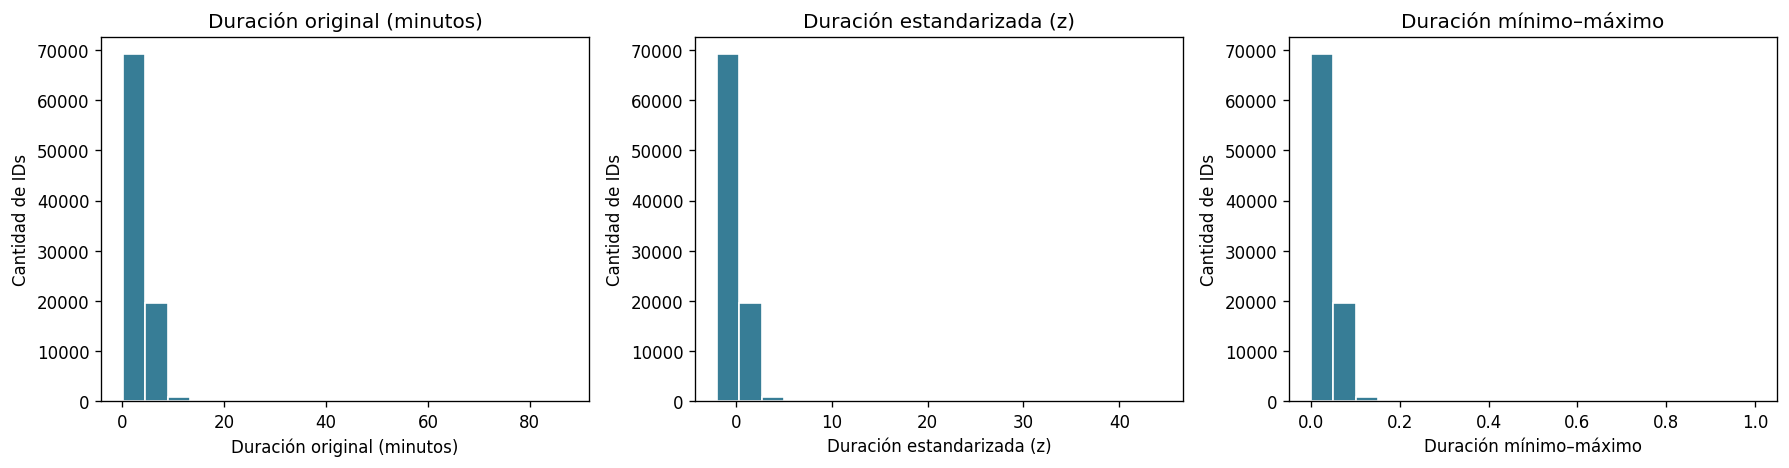

In [83]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
series_escala = [(datos_escalamiento["duration_min"], "Duración original (minutos)"), (df_demo_estandarizado["duration_min"], "Duración estandarizada (z)"), (df_demo_minmax["duration_min"], "Duración mínimo–máximo")]
for eje, (serie, etiqueta) in zip(ejes, series_escala):
    eje.hist(serie.dropna(), bins=20, color="#377D96", edgecolor="white")
    eje.set(title=etiqueta, xlabel=etiqueta, ylabel="Cantidad de IDs")
fig.tight_layout()
plt.show()

### 21.6 Comprobar las relaciones con popularidad

**Línea 1:** calcula Pearson entre las características originales y la popularidad resumida, alineando por ID con `.corrwith(...)`.

**Líneas 2 y 3:** repiten el cálculo para las dos representaciones.

**Línea 4:** presenta las correlaciones con seis decimales.

La popularidad no se transformó. Los pares disponibles siguen siendo los mismos, incluidas las ausencias de tempo.

In [84]:
pearson_original_escala = datos_escalamiento.corrwith(df_canciones["popularity"])
pearson_z_demo = df_demo_estandarizado.corrwith(df_canciones["popularity"])
pearson_minmax_demo = df_demo_minmax.corrwith(df_canciones["popularity"])
pd.DataFrame({"Original": pearson_original_escala, "Estandarizado": pearson_z_demo, "MinMax": pearson_minmax_demo}).round(6)

,Original,Estandarizado,MinMax
duration_min,-0.023165,-0.023165,-0.023165
danceability,0.064276,0.064276,0.064276
energy,0.013761,0.013761,0.013761
loudness,0.071705,0.071705,0.071705
speechiness,-0.047082,-0.047082,-0.047082
acousticness,-0.038885,-0.038885,-0.038885
instrumentalness,-0.127472,-0.127472,-0.127472
liveness,-0.013879,-0.013879,-0.013879
valence,-0.011521,-0.011521,-0.011521
tempo,0.008817,0.008817,0.008817


**Resultado:** las correlaciones coinciden salvo diferencias mínimas de precisión numérica. Cambiar una medida mediante estas transformaciones lineales positivas no cambia su correlación de Pearson, cuando tiene variación y se conservan los mismos pares.

Por eso no fue necesario escalar para el análisis de correlaciones previo. Tampoco podemos presentar el escalamiento como una mejora de la relación con popularidad.

### 21.7 Verificar ausencias, IDs y variables excluidas

La siguiente Serie comprueba que:

- El índice mantiene los mismos IDs y orden.
- Las posiciones de los faltantes coinciden exactamente antes y después, no solo su cantidad.
- Popularidad no forma parte de las columnas transformadas.

`.equals(...)` compara las máscaras de ausencias; `not in` comprueba que el nombre no esté en las columnas. Esperamos `True` en todos los controles.

In [85]:
pd.Series({
    "IDs de estandarización conservados": df_demo_estandarizado.index.equals(datos_escalamiento.index),
    "IDs de MinMax conservados": df_demo_minmax.index.equals(datos_escalamiento.index),
    "Ausencias de estandarización conservadas": df_demo_estandarizado.isna().equals(datos_escalamiento.isna()),
    "Ausencias de MinMax conservadas": df_demo_minmax.isna().equals(datos_escalamiento.isna()),
    "Popularidad excluida de estandarización": "popularity" not in df_demo_estandarizado.columns,
    "Popularidad excluida de MinMax": "popularity" not in df_demo_minmax.columns
})

IDs de estandarización conservados          True
IDs de MinMax conservados                   True
Ausencias de estandarización conservadas    True
Ausencias de MinMax conservadas             True
Popularidad excluida de estandarización     True
Popularidad excluida de MinMax              True
dtype: bool

## 22. Conclusiones y límite de uso del escalamiento

| Aspecto | Estandarización | Mínimo–máximo |
|---|---|---|
| Referencia | Media y desviación estándar | Mínimo y máximo |
| Resultado en datos de ajuste no constantes | Media ≈0 y desviación ≈1 | Mínimo 0 y máximo 1 |
| ¿Puede dar negativos? | Sí | Sí en datos nuevos bajo el mínimo de ajuste |
| ¿Elimina extremos o imputa ausencias? | No | No |
| ¿Demuestra mejor predicción? | No se ha evaluado un modelo | No se ha evaluado un modelo |

Esta demostración añade dos tablas auxiliares de diez características. **No reemplaza las tablas originales ni las conclusiones de los KPI**, que siguen evaluando la base preparada y su documentación.

**Al avanzar al modelamiento:**

1. Separar entrenamiento y evaluación respetando canciones relacionadas y el objetivo del uso.
2. Calcular medias/desviaciones o mínimos/máximos usando solo entrenamiento.
3. Aplicar esos mismos parámetros al resto de los datos; no ajustarlos otra vez con prueba.
4. En validación cruzada, ajustar el escalamiento dentro de cada pliegue de entrenamiento, normalmente mediante un pipeline.

Usar información de prueba para ajustar la preparación sería una fuga de información. Las tablas `demo` se calcularon con toda la muestra solo para aprender el mecanismo y no deben reutilizarse como preparación de una evaluación independiente.

La elección de escalar depende del modelo: resulta relevante en métodos sensibles a distancias o penalización de coeficientes; no se necesita del mismo modo para árboles. En esta unidad no seleccionamos un escalamiento ganador ni entrenamos modelos.

**Preguntas de comprensión:**

- ¿Por qué un valor estandarizado negativo puede ser válido?
- ¿Qué diferencia hay entre 0,5 en MinMax y el percentil 50?
- ¿Por qué no escalamos popularidad ni los códigos de categorías?
- ¿Por qué escalar no elimina la cola de duración?
- ¿Por qué las correlaciones de Pearson no mejoraron al escalar?
- ¿Qué parámetros habría que guardar para transformar canciones nuevas?

La preparación incluye una demostración explícita de escalamiento y conserva las unidades originales para interpretar estadísticas y gráficos.

**Continuación:** revisamos las implicaciones éticas y las limitaciones antes de evaluar los KPI y redactar las conclusiones generales.

<a id="etica" ></a>

## 23. Ética, sesgos y limitaciones del dataset

**Objetivo:** explicar cómo la selección de datos, su limpieza y la interpretación de los resultados pueden afectar las conclusiones y a las personas representadas por la música.

No basta con que el código funcione o los valores estén dentro de un rango. También debemos preguntar **a quién representa la muestra, qué información falta y qué decisiones sería razonable apoyar con ella**.

Esta sección interpreta las decisiones y resultados ya obtenidos. No modifica datos, no añade modelos y no introduce nuevas métricas. Los riesgos descritos son posibilidades que debemos considerar; no son pruebas de discriminación observada.

### 23.1 Popularidad no equivale a calidad artística

La variable `popularity` es un puntaje registrado en la fuente. No mide directamente talento, calidad de composición, originalidad o valor cultural.

**Ejemplo:** una canción con popularidad 0 puede ser reciente, tener poca exposición o pertenecer a un nicho. Son explicaciones posibles, no causas verificadas en este dataset. Su puntaje no permite afirmar que sea «mala» ni que nadie la haya escuchado.

**Decisión aplicada:** conservamos los ceros de popularidad porque están dentro de la escala 0–100. Eliminarlos habría quitado precisamente parte de la realidad que queremos describir.

**Consecuencia para las conclusiones:** escribimos «popularidad registrada baja», no «baja calidad musical». Tampoco interpretamos una popularidad alta como una recomendación automática de promoción.

### 23.2 ¿A quién representa nuestra muestra?

Tenemos muchas canciones y 114 etiquetas de género, pero el tamaño no garantiza representatividad. No conocemos un diseño de selección que permita extrapolar estos resultados a todo Spotify, a todos los países o a todos los periodos.

| Limitación | Cómo afecta al análisis |
|---|---|
| Selección de canciones de la fuente | Las frecuencias describen esta muestra; no necesariamente la oferta o el consumo global |
| Géneros etiquetados | Las categorías pueden ser amplias, solaparse o no cubrir todos los estilos |
| Fecha de extracción no verificada | Los puntajes no se pueden presentar como popularidad actual |
| Posibles reediciones con distintos IDs | Una obra puede estar representada más de una vez, aunque cada ID aparezca una vez |

**Decisión de comunicación:** usamos expresiones como «en este dataset» o «en la muestra analizada». El gráfico de géneros cuenta presencia de etiquetas, no cantidad de oyentes ni preferencias mundiales.

Una distribución desigual de géneros no demuestra por sí sola injusticia. Es una limitación de cobertura que debemos reconocer antes de generalizar.

### 23.3 Dos sentidos de la palabra «sesgo»

**Sesgo de los datos o del análisis:** una forma de seleccionar, repetir o tratar registros puede inclinar los resultados. Por ejemplo, calcular una media por filas da mayor peso a una canción que aparece en varios géneros.

**Riesgo ético de trato desigual:** una conclusión o un sistema podría perjudicar a ciertos artistas o estilos si se utiliza como criterio de valoración o selección sin contexto.

En esta unidad identificamos riesgos y limitaciones; **no hemos demostrado discriminación ni medido equidad entre grupos de personas**. Género musical no es lo mismo que género de una persona.

No inferimos sexo, edad, origen étnico u otras características personales a partir de nombres de artistas. El archivo no aporta una base suficiente para ese análisis.

### 23.4 Cómo influyen nuestras decisiones de limpieza

| Decisión aplicada | Beneficio buscado | Limitación o efecto que debemos comunicar |
|---|---|---|
| Retirar el índice exportado | Separar el contenido del registro técnico | El criterio se verificó para este archivo; no se generaliza a toda columna sin nombre |
| Retirar 450 copias exactas de contenido | Evitar peso adicional por copias idénticas | No sabemos por qué se originaron; no equivalen a 450 canciones distintas |
| Excluir una fila con duración cero | Trabajar con duraciones positivas utilizables | Se excluye también su resto de información, incluida popularidad; podría servir para otro análisis con distinto alcance |
| Etiquetar 20 álbumes como `DESCONOCIDO` | Hacer visible que falta el nombre | No se recuperó información; no son necesariamente un mismo álbum |
| Marcar 157 tempos y 163 compases como ausentes | Evitar interpretar ceros como estimaciones musicales determinadas | Los análisis de esas variables utilizan menos datos; sus resultados pueden diferir si las ausencias no son aleatorias |
| Conservar compás 1 y sonoridades positivas | Evitar descartes sin evidencia suficiente de error | Su significado o procedencia sigue necesitando revisión; conservar no equivale a validar |
| Conservar ceros válidos y valores atípicos | Mantener extremos y estilos poco comunes | Los promedios y correlaciones pueden ser sensibles a esos valores |

**Regla de interpretación:** no calificamos una limpieza como ética solo por conservar el 99,604% de los registros. El porcentaje resume cuánto se mantuvo, no a quién afectaron los cambios.

Las operaciones quedaron documentadas y el CSV original se mantuvo intacto. Esto facilita revisar decisiones y construir otra preparación si cambia el objetivo.

### 23.5 Los faltantes pueden cambiar qué canciones analizamos

Al estudiar tempo, utilizamos **89.583 IDs con dato disponible**, frente a los **89.740 IDs** de otras medidas. Esto es correcto como descripción de los datos presentes, pero no prueba que los 157 ausentes sean comparables al resto.

**Ejemplo hipotético:** si el tempo fuera más difícil de estimar en un estilo concreto, omitir sus faltantes en una correlación reduciría la presencia de ese estilo en ese cálculo. No afirmamos que eso esté demostrado aquí.

**Decisión aplicada:** informamos el número de pares disponibles y conservamos las ausencias sin inventar valores. No usamos el promedio como reemplazo solo para conseguir cero nulos.

**Límite pendiente:** no se ha realizado una comparación sistemática de ausencias por género ni una evaluación de sensibilidad de las conclusiones a otras reglas de limpieza. Por ello, no afirmamos que el tratamiento no afectó a ningún estilo.

### 23.6 Una fila por ID y popularidades discrepantes

En el análisis por canción identificamos **720 IDs con más de una popularidad registrada**. Sin fechas que permitan ordenar esos valores, no sabemos cuál sería el correcto o el más reciente.

**Decisión aplicada:** utilizamos la mediana por ID para resumirlos en las estadísticas, las correlaciones y la base integrada. El detalle original permanece en `df_limpio`.

**Qué resuelve:** ofrece una regla explícita de resumen y evita contar cada registro de género como una observación independiente en las distribuciones globales.

**Qué no resuelve:** no reconstruye una historia temporal, no recupera la verdad del puntaje y puede quedar influida por cuántos registros tiene cada valor dentro del ID. No se ha cuantificado aquí cómo cambiarían todas las conclusiones con otra regla.

Los resultados se presentan como **popularidad resumida por ID**, no como popularidad actual verificada.

### 23.7 Multi-Hot Encoding: conservar diversidad sin exagerar lo conocido

La representación Multi-Hot conserva todas las etiquetas registradas para cada ID. Así no forzamos a las **16.299 canciones con varios géneros** a tener un único género principal.

- **1:** la fuente registró esa etiqueta para el ID.
- **0:** esa etiqueta no aparece registrada; no demuestra que sea musicalmente imposible o incorrecta para la canción.

Las comprobaciones confirmaron que se conservaron las etiquetas de los 114 géneros. **Eso demuestra fidelidad a la fuente limpia, no exactitud de la clasificación musical original.**

Si se comparan géneros, una canción puede participar en varios grupos. Por ello, los grupos no son independientes ni sus tamaños deben sumar el total de IDs.

**Consecuencia ética:** no utilizamos las etiquetas como fronteras absolutas de identidad artística ni inferimos capacidades de un artista a partir de un género.

### 23.8 Asociación no es causalidad

Observamos una correlación débil entre instrumentalidad y popularidad (**r≈−0,127**) y relaciones mayores entre características de audio. También observamos diferencias de popularidad media entre categorías de contenido explícito.

**Lo observado no demuestra que cambiar una característica produzca un cambio de popularidad.** Podrían intervenir género musical, exposición, artista, antigüedad u otros factores que aquí no controlamos.

| Formulación sustentada | Formulación que este análisis no justifica |
|---|---|
| «En esta muestra, instrumentalidad y popularidad tienen una asociación lineal negativa débil» | «La música instrumental causa menor popularidad» |
| «Las categorías de contenido explícito presentan medias diferentes» | «Añadir contenido explícito aumenta el éxito» |
| «Los valores altos de popularidad son menos frecuentes en la muestra» | «Los estilos menos representados tienen menor calidad» |

**Decisión de comunicación:** describir los datos sin convertirlos en instrucciones para cambiar el trabajo artístico. Las métricas exploratorias no son una evaluación del mérito de artistas ni una garantía de éxito futuro.

### 23.9 Privacidad e información identificable

El dataset incluye nombres de artistas y títulos. Los nombres pueden identificar personas, aunque se utilicen públicamente en un catálogo musical.

No contiene perfiles de oyentes ni historiales individuales de escucha entre las columnas revisadas. Eso limita algunos riesgos, pero no convierte automáticamente toda información en anónima.

**Criterios de trabajo:**

- Utilizar los nombres solo cuando aporten contexto al análisis.
- No intentar vincular artistas con datos privados ni inferir atributos personales sensibles.
- Priorizar resultados agregados al redactar conclusiones.
- No construir listas que descalifiquen a personas por puntajes bajos.
- No asumir que el acceso público al CSV autoriza cualquier redistribución; antes de publicar los datos debe verificarse su licencia y procedencia.

En este trabajo no necesitamos aplicar hashing a nombres para demostrar privacidad. Esa operación tampoco garantizaría anonimato por sí sola si otros atributos permiten identificar la canción o al artista.

### 23.10 Uso responsable y conclusiones permitidas

**Este análisis permite:** describir esta muestra, detectar problemas de calidad, explorar asociaciones y preparar una base documentada para futuros estudios.

**No permite por sí solo:** valorar talento, demostrar causas, inferir preferencias de toda la población, justificar exclusiones de artistas o asegurar qué lanzamientos serán exitosos.

Si en una etapa posterior se utiliza un modelo para priorizar canciones, habría que evaluar sus errores y efectos por grupos relevantes, considerar artistas sin historial y mantener revisión humana. Es un trabajo posterior, no una validación ya realizada en esta unidad.

Cumplir los KPI de calidad verifica aspectos concretos de preparación. **No equivale a certificar representatividad, privacidad completa, ausencia de sesgos o equidad.**

## 24. Síntesis de ética y limitaciones

| Pregunta | Conclusión del trabajo |
|---|---|
| ¿Popularidad mide calidad artística? | No; se analiza como un puntaje registrado |
| ¿La muestra representa todo Spotify? | No contamos con evidencia para asegurarlo |
| ¿La limpieza es neutral? | Cada regla cambia la base o su interpretación; sus efectos se documentan |
| ¿Los faltantes dejaron de importar? | No; se informan los datos disponibles y sus límites |
| ¿La mediana recuperó la popularidad correcta? | No; es un resumen explícito ante discrepancias |
| ¿Multi-Hot verificó la verdad musical de los géneros? | No; verificó la conservación de las etiquetas disponibles |
| ¿Las correlaciones muestran causas? | No; son asociaciones observacionales |
| ¿La información es completamente anónima? | No; hay nombres identificables de artistas |
| ¿Se demostró ausencia de discriminación? | No; no se realizó una evaluación de equidad entre personas |

**Preguntas de comprensión:**

1. ¿Por qué conservar muchas filas no garantiza que la muestra sea representativa?
2. ¿Cómo podría la ausencia de tempo modificar una comparación aunque se calcule correctamente?
3. ¿Por qué `DESCONOCIDO` no significa que recuperamos el nombre del álbum?
4. ¿Qué incertidumbre permanece después de resumir popularidad por ID?
5. ¿Qué diferencia hay entre fidelidad de las etiquetas Multi-Hot y exactitud musical?
6. ¿Cómo redactarías una conclusión que describa una asociación sin culpar o descalificar a un artista?

**Siguiente etapa:** reunir los KPI y las evidencias en un cierre final, seguido de conclusiones generales que respondan al objetivo y reconozcan estas limitaciones. Esta reflexión no añade modificaciones al dataset.

<a id="kpi" ></a>

## 25. Cierre de los KPI: metas, resultados y evidencias

**Objetivo:** comprobar las cuatro metas definidas al inicio, mostrando el cálculo y la evidencia de cada resultado.

Un KPI reúne **indicador**, **meta** y **resultado**. El estado «cumple» significa que el resultado alcanza esa meta concreta; no certifica calidad perfecta ni ausencia de sesgos.

**Alcance del cálculo:** los dos primeros indicadores se calculan sobre `df_limpio`, la base preparada de **113.549 registros**, antes de resumir por ID. Los otros dos revisan la documentación de la limpieza y de las **13 reglas/aspectos de la auditoría inicial**.

`df_base_canciones`, con 89.740 IDs, mantiene sus propias comprobaciones de estructura y conservación Multi-Hot. Esas verificaciones complementan los KPI, pero no cambian sus denominadores ni sus metas.

No añadimos nuevas metas para aprobar resultados ya observados. En este cierre explicitamos los inventarios que permiten contar la documentación de operaciones y reglas.

### 25.1 KPI 1 · Porcentaje de popularidad inválida

**Fórmula:**

`registros con popularidad ausente, no numérica o fuera de 0–100 / total de registros preparados × 100`

**Meta:** 0%. **Dirección deseada:** menor.

**Líneas del código:**

1. `total_registros = len(df_limpio)` fija el denominador.
2. `if total_registros == 0:` detecta una base vacía.
3. `raise ValueError(...)` detiene el cálculo en ese caso: una base vacía no debe «aprobar» por tener cero problemas.
4. `pd.to_numeric(..., errors="coerce")` crea una Serie numérica auxiliar. Convierte texto no interpretable en ausente, sin modificar la columna original.
5. `.isna() | ~.between(0, 100)` marca los ausentes o fuera de rango; el intervalo incluye 0 y 100.
6. `.sum()` cuenta los registros señalados.
7. La división por `total_registros` y multiplicación por 100 obtiene el porcentaje.
8. La Serie final muestra numerador, denominador y resultado.

Una popularidad cero sigue siendo válida. Esta regla tampoco exige que la popularidad sea alta.

In [86]:
total_registros = len(df_limpio)
if total_registros == 0:
    raise ValueError("No se pueden evaluar los KPI sobre una base preparada vacía.")
popularidad_kpi = pd.to_numeric(df_limpio["popularity"], errors="coerce")
mascara_popularidad_invalida = popularidad_kpi.isna() | ~popularidad_kpi.between(0, 100)
registros_popularidad_invalida = mascara_popularidad_invalida.sum()
resultado_kpi_1 = registros_popularidad_invalida / total_registros * 100
pd.Series({"Registros inválidos": registros_popularidad_invalida, "Registros preparados": total_registros, "Porcentaje": resultado_kpi_1})

Registros inválidos          0.0
Registros preparados    113549.0
Porcentaje                   0.0
dtype: float64

**Resultado: 0 / 113.549 × 100 = 0%. Cumple.**

**Evidencia:** la auditoría no encontró popularidad ausente ni fuera de rango; aquí lo comprobamos nuevamente en la base preparada, incluyendo conversión numérica auxiliar.

**Qué significa:** todos los registros preparados tienen un valor utilizable según esta regla.

**Qué no significa:** que los valores sean actuales o correctos en la fuente. Permanecen las discrepancias entre registros de 720 IDs, que se resumieron con mediana en otra tabla.

### 25.2 KPI 2 · Porcentaje de copias exactas adicionales

**Fórmula:**

`copias adicionales de contenido idéntico / total de registros preparados × 100`

**Meta:** 0%. **Dirección deseada:** menor.

**Línea 1:** `df_limpio.duplicated().sum()` compara las 20 columnas preparadas, sin el índice exportado. Marca copias posteriores a la primera aparición; el índice de Pandas no interviene en esa comparación.

**Línea 2:** calcula el porcentaje con el mismo denominador de 113.549 registros.

**Línea 3:** muestra conteo, total y porcentaje.

No comprobamos aquí «IDs repetidos»: una canción con distinto género no es una copia exacta.

In [87]:
copias_adicionales_finales = df_limpio.duplicated().sum()
resultado_kpi_2 = copias_adicionales_finales / total_registros * 100
pd.Series({"Copias adicionales": copias_adicionales_finales, "Registros preparados": total_registros, "Porcentaje": resultado_kpi_2})

Copias adicionales           0.0
Registros preparados    113549.0
Porcentaje                   0.0
dtype: float64

**Resultado: 0 / 113.549 × 100 = 0%. Cumple.**

**Evidencia:** se retiraron 450 copias en la sección 12.3; el conteo actual confirma que no quedan copias exactas según las columnas definidas.

**Qué no significa:** que no existan reediciones o versiones semejantes con distinto ID, ni que toda la base sea de una fila por canción. Esa representación se construyó después mediante agrupación y Multi-Hot.

### 25.3 KPI 3 · Porcentaje de operaciones de limpieza documentadas

**Fórmula:**

`operaciones aplicadas con documentación mínima completa / operaciones de limpieza aplicadas × 100`

**Meta:** 100%. **Dirección deseada:** mayor.

Para no confundir «cantidad de anotaciones» con «cantidad de operaciones», enumeramos las siete transformaciones del código de limpieza en secciones 12.2–12.8. Este inventario se reconstruye de esas secciones para cerrar el KPI; no es un sistema automático que detecte cualquier modificación futura.

La documentación mínima revisada incluye nombre de operación, cantidad afectada, unidad y motivo. Sus efectos y límites se explican en las secciones de limpieza y ética.

Si después se agrega una operación, deberá actualizarse el inventario y registrarse su evidencia. Tener campos completos no garantiza que su justificación sea suficiente: requiere lectura y revisión.

### Inventariar las operaciones y vincular sus evidencias

**Línea 1:** la Serie `operaciones_aplicadas_kpi` enumera los nombres de las siete operaciones, con referencias a las secciones donde se ejecutan. El índice identifica cada operación y los valores indican la evidencia.

**Línea 2:** `tabla_limpieza["operacion"].is_unique` comprueba que no hay nombres repetidos en el registro.

**Línea 3:** si los hay, se detiene con un mensaje para revisar la ambigüedad.

**Línea 4:** `.set_index("operacion").reindex(...)` alinea la tabla de limpieza con el inventario. Una operación no registrada quedaría con campos ausentes.

**Línea 5:** añade la sección de evidencia por nombre, sin modificar `tabla_limpieza`.

La lista y sus secciones son evidencia documental mantenida por el equipo; no una medición de calidad musical.

In [88]:
operaciones_aplicadas_kpi = pd.Series({
    "Retirar índice exportado": "Sección 12.2",
    "Retirar copias exactas": "Sección 12.3",
    "Excluir duración no positiva": "Sección 12.4",
    "Etiquetar álbum no informado": "Sección 12.5",
    "Marcar tempo no determinado": "Sección 12.6",
    "Marcar compás no determinado": "Sección 12.7",
    "Reiniciar índice de la copia": "Sección 12.8"
})
if not tabla_limpieza["operacion"].is_unique:
    raise ValueError("Hay nombres de operaciones repetidos; revisar el registro antes de calcular el KPI.")
evidencia_operaciones_kpi = tabla_limpieza.set_index("operacion").reindex(operaciones_aplicadas_kpi.index)
evidencia_operaciones_kpi["evidencia"] = operaciones_aplicadas_kpi

### Revisar que la documentación esté completa

**Línea 1:** `.notna()` verifica presencia de cantidad. `& .ge(0)` exige que no sea negativa.

**Línea 2:** el bucle revisa las tres columnas de texto de documentación: unidad, motivo y evidencia.

**Línea 3:** convierte temporalmente a texto, sustituye ausencias por texto vacío y quita espacios. `.ne("")` exige contenido no vacío. `&` acumula el requisito para cada operación.

**Línea 4:** guarda el resultado booleano en una columna auxiliar.

**Línea 5:** muestra toda la evidencia. **True** significa que los campos mínimos están completos, no que se haya demostrado ausencia de sesgos.

In [89]:
operaciones_documentadas_kpi = evidencia_operaciones_kpi["cantidad"].notna() & evidencia_operaciones_kpi["cantidad"].ge(0)
for campo in ["unidad", "motivo", "evidencia"]:
    operaciones_documentadas_kpi = operaciones_documentadas_kpi & evidencia_operaciones_kpi[campo].astype("string").fillna("").str.strip().ne("")
evidencia_operaciones_kpi["documentacion_minima_completa"] = operaciones_documentadas_kpi
evidencia_operaciones_kpi

,cantidad,unidad,motivo,evidencia,documentacion_minima_completa
Retirar índice exportado,1,columna,Reproduce el índice y no describe la canción,Sección 12.2,True
Retirar copias exactas,450,filas,Contenido idéntico en las 20 columnas; conserv...,Sección 12.3,True
Excluir duración no positiva,1,fila,Duración cero; fila conservada en tabla auxili...,Sección 12.4,True
Etiquetar álbum no informado,20,celdas,Explicitar ausencia sin inventar el nombre del...,Sección 12.5,True
Marcar tempo no determinado,157,celdas,Valor no positivo no utilizable como estimació...,Sección 12.6,True
Marcar compás no determinado,163,celdas,Código 0 no representa un compás determinado; ...,Sección 12.7,True
Reiniciar índice de la copia,113549,etiquetas de fila,Índice consecutivo para consultar la base prep...,Sección 12.8,True


### Calcular el tercer indicador

**Línea 1:** `.sum()` cuenta las operaciones con documentación mínima completa.

**Línea 2:** `len(operaciones_aplicadas_kpi)` cuenta las operaciones del inventario, no solo las anotaciones existentes.

**Línea 3:** calcula el porcentaje si hay operaciones; en ausencia de operaciones devuelve `None` para representar «no aplica», no 100% automáticamente.

**Línea 4:** muestra el detalle del cálculo.

In [90]:
numero_operaciones_documentadas = operaciones_documentadas_kpi.sum()
numero_operaciones_aplicadas = len(operaciones_aplicadas_kpi)
resultado_kpi_3 = numero_operaciones_documentadas / numero_operaciones_aplicadas * 100 if numero_operaciones_aplicadas > 0 else None
pd.Series({"Operaciones documentadas": numero_operaciones_documentadas, "Operaciones aplicadas": numero_operaciones_aplicadas, "Porcentaje": resultado_kpi_3})

Operaciones documentadas      7.0
Operaciones aplicadas         7.0
Porcentaje                  100.0
dtype: float64

**Resultado: 7 / 7 × 100 = 100%. Cumple la documentación mínima.**

Se documentaron transformaciones, no una operación por cada celda cambiada. La codificación Multi-Hot y las tablas de análisis no forman parte de estas siete operaciones de limpieza; tienen comprobaciones propias en otras secciones.

No sumamos las cantidades afectadas del registro: unas están expresadas en columnas, otras en filas y otras en celdas.

### 25.4 KPI 4 · Porcentaje de reglas de auditoría con conclusión documentada

**Fórmula:**

`reglas de la auditoría con resultado, conclusión y evidencia / total de reglas de la auditoría inicial × 100`

**Meta:** 100%. **Dirección deseada:** mayor.

La sección 10.1 definió **13 aspectos de revisión**. Esa será la unidad de conteo: no cada celda, columna ni condición auxiliar. Por ejemplo, las siete escalas 0–1 se agrupan bajo el aspecto «Escalas de audio», tal como se presentó al inicio.

**Una conclusión documentada puede ser conservar con una limitación abierta.** Por eso el KPI no se llama «porcentaje de problemas resueltos». Compás 1 y sonoridad positiva seguirán marcados para revisión de significado.

El siguiente registro reúne resultados ya obtenidos y referencias a las secciones. Es una síntesis documental redactada por el equipo, no una nueva comprobación automática de todos los valores.

### Reunir las 13 conclusiones y evidencias

**Línea 1:** la lista `reglas_iniciales_kpi` mantiene los 13 aspectos, con los mismos nombres de la tabla inicial.

**Línea 2:** `pd.DataFrame([...], columns=[...])` crea el registro final. Cada lista interior aporta una fila con regla, resultado, conclusión y evidencia. Los conteos se expresan indicando si corresponden al archivo auditado o a la base preparada.

**Línea 3:** `.set_index("regla").reindex(reglas_iniciales_kpi)` alinea con el inventario inicial; una conclusión omitida aparecería vacía. Las alertas abiertas se expresan explícitamente en el texto.

In [91]:
reglas_iniciales_kpi = ["Faltantes", "Texto", "Duplicados", "ID repetido", "Popularidad", "Escalas de audio", "Duración", "Tempo", "Tonalidad", "Modo", "Contenido explícito", "Compás", "Sonoridad"]
registro_reglas_kpi = pd.DataFrame([
    ["Faltantes", "Tres celdas en una fila auditada; 320 ausencias explícitas tras preparar", "Fila incompleta excluida por duración cero; tempo y compás no determinados se mantienen como ausentes", "10.2–10.3, 12.4, 12.6–12.7 y 13.1"],
    ["Texto", "20 marcadores de álbum en auditoría y preparación", "Se etiquetan DESCONOCIDO sin afirmar que se recuperó el nombre real", "10.4 y 12.5"],
    ["Duplicados", "450 copias de contenido iniciales; cero en base preparada", "Se conserva la primera aparición exacta sin índice técnico", "10.5–10.7, 12.3 y 25.2"],
    ["ID repetido", "89.741 IDs auditados; 89.740 tras excluir una fila", "Se conservan géneros por registro; la base por ID y Multi-Hot es una representación adicional", "10.8–10.9 y 19.1–19.9"],
    ["Popularidad", "Cero faltantes o fuera de rango en base preparada", "Se conservan ceros válidos; discrepancias por ID se resumen con mediana y limitación", "10.11, 15.1–15.2 y 25.1"],
    ["Escalas de audio", "Cero incumplimientos del intervalo 0–1 en las siete escalas", "Se conservan extremos válidos; no se eliminan por ser cero", "10.11 y 10.15"],
    ["Duración", "Una duración cero excluida", "Se conserva trazabilidad de la fila; no se imputa duración", "12.4"],
    ["Tempo", "157 ceros representados como ausencias", "Se conservan filas; se informa el número disponible de datos en análisis", "12.6 y 15.9"],
    ["Tonalidad", "Cero códigos fuera de −1 a 11 en la auditoría", "Se conservan códigos; cero representa Do, no un faltante", "10.12 y 10.15"],
    ["Modo", "Cero códigos fuera de 0 y 1 en la auditoría", "Se conservan categorías; no se promedian como cantidades musicales", "10.12 y 15.11"],
    ["Contenido explícito", "Valores booleanos en la auditoría", "Se conserva indicador; False no garantiza comprobación manual", "8.5, 10.12 y 17.7"],
    ["Compás", "163 ceros marcados ausentes; 967 unos conservados tras limpieza", "Conclusión documentada con alerta abierta: compás 1 necesita revisión de significado", "10.12–10.13, 12.7 y 23.4"],
    ["Sonoridad", "90 valores positivos observados en auditoría", "Conclusión documentada con alerta abierta: se conservan sin confirmar error; pendiente contexto", "10.10–10.13 y 23.4"]
], columns=["regla", "resultado", "conclusion", "evidencia"])
registro_reglas_kpi = registro_reglas_kpi.set_index("regla").reindex(reglas_iniciales_kpi)

### Comprobar y mostrar el registro de reglas

**Línea 1:** el conjunto `set(...)` permite comparar los nombres únicos del inventario escrito aquí con los 13 aspectos. Este inventario se coteja con la tabla de la sección 10.1; no se descubren reglas nuevas para elevar el resultado.

**Línea 2:** si se detectan nombres repetidos, se detiene el cálculo.

**Línea 3:** verifica que ninguna celda documental está ausente. `.all(axis=1)` exige presencia en las tres columnas de cada regla.

**Líneas 4–5:** comprueban que tampoco sean textos vacíos, acumulando el requisito para resultado, conclusión y evidencia.

**Línea 6:** guarda el estado documental.

**Línea 7:** muestra el registro completo. La existencia de texto y referencias se comprueba mediante código; la corrección y suficiencia de la interpretación requieren revisión humana.

In [92]:
nombres_reglas_unicos = len(set(reglas_iniciales_kpi)) == len(reglas_iniciales_kpi)
if not nombres_reglas_unicos:
    raise ValueError("El inventario de reglas contiene nombres repetidos.")
reglas_documentadas_kpi = registro_reglas_kpi[["resultado", "conclusion", "evidencia"]].notna().all(axis=1)
for campo in ["resultado", "conclusion", "evidencia"]:
    reglas_documentadas_kpi = reglas_documentadas_kpi & registro_reglas_kpi[campo].astype("string").fillna("").str.strip().ne("")
registro_reglas_kpi["conclusion_documentada"] = reglas_documentadas_kpi
registro_reglas_kpi

,resultado,conclusion,evidencia,conclusion_documentada
regla,,,,
Faltantes,Tres celdas en una fila auditada; 320 ausencia...,Fila incompleta excluida por duración cero; te...,"10.2–10.3, 12.4, 12.6–12.7 y 13.1",True
Texto,20 marcadores de álbum en auditoría y preparación,Se etiquetan DESCONOCIDO sin afirmar que se re...,10.4 y 12.5,True
Duplicados,450 copias de contenido iniciales; cero en bas...,Se conserva la primera aparición exacta sin ín...,"10.5–10.7, 12.3 y 25.2",True
ID repetido,89.741 IDs auditados; 89.740 tras excluir una ...,Se conservan géneros por registro; la base por...,10.8–10.9 y 19.1–19.9,True
Popularidad,Cero faltantes o fuera de rango en base preparada,Se conservan ceros válidos; discrepancias por ...,"10.11, 15.1–15.2 y 25.1",True
Escalas de audio,Cero incumplimientos del intervalo 0–1 en las ...,Se conservan extremos válidos; no se eliminan ...,10.11 y 10.15,True
Duración,Una duración cero excluida,Se conserva trazabilidad de la fila; no se imp...,12.4,True
Tempo,157 ceros representados como ausencias,Se conservan filas; se informa el número dispo...,12.6 y 15.9,True
Tonalidad,Cero códigos fuera de −1 a 11 en la auditoría,"Se conservan códigos; cero representa Do, no u...",10.12 y 10.15,True


### Calcular el cuarto indicador

**Línea 1:** suma las reglas con documentación mínima completa.

**Línea 2:** cuenta las reglas iniciales: 13 aspectos.

**Línea 3:** calcula el porcentaje; si no existiera inventario, devuelve `None` en lugar de un porcentaje artificial.

**Línea 4:** muestra numerador, denominador y resultado.

In [93]:
numero_reglas_documentadas = reglas_documentadas_kpi.sum()
numero_reglas_iniciales = len(reglas_iniciales_kpi)
resultado_kpi_4 = numero_reglas_documentadas / numero_reglas_iniciales * 100 if numero_reglas_iniciales > 0 else None
pd.Series({"Reglas documentadas": numero_reglas_documentadas, "Reglas iniciales": numero_reglas_iniciales, "Porcentaje": resultado_kpi_4})

Reglas documentadas     13.0
Reglas iniciales        13.0
Porcentaje             100.0
dtype: float64

**Resultado: 13 / 13 × 100 = 100%. Cumple el cierre documental.**

Significa que cada aspecto inicial tiene resultado, conclusión y referencia. **No significa que los 13 aspectos estén libres de incertidumbre.** Compás 1 y sonoridad positiva siguen con alertas abiertas de interpretación; además permanecen las limitaciones generales de muestra, tiempo y popularidad.

Conservar un dato con una limitación comunicada puede cerrar su documentación sin resolver definitivamente su significado.

### 25.5 Construir la tabla final de KPI

**Línea 1:** `pd.DataFrame([...])` reúne cuatro diccionarios, uno por indicador. Cada fila contiene meta, numerador, denominador, porcentaje, comparación de cumplimiento y evidencia.

- Para los KPI 1 y 2, `== 0` comprueba la meta de ausencia de incumplimientos detectados.
- Para los KPI 3 y 4, `== 100` comprueba documentación completa del inventario.
- El campo «cumple» es booleano: True o False. No es una predicción.

**Línea 2:** `.set_index("KPI")` usa el nombre de indicador como índice de presentación.

**Línea 3:** `.round(3)` redondea la tabla mostrada; no cambia el cálculo ni altera los datos.

In [94]:
tabla_kpi_final = pd.DataFrame([
    {"KPI": "1. Popularidad inválida", "Meta": "0%", "Numerador": registros_popularidad_invalida, "Denominador": total_registros, "Resultado (%)": resultado_kpi_1, "cumple": resultado_kpi_1 == 0, "Evidencia": "Máscara y cálculo 25.1; base df_limpio"},
    {"KPI": "2. Copias exactas adicionales", "Meta": "0%", "Numerador": copias_adicionales_finales, "Denominador": total_registros, "Resultado (%)": resultado_kpi_2, "cumple": resultado_kpi_2 == 0, "Evidencia": "Conteo duplicated en 25.2; limpieza 12.3"},
    {"KPI": "3. Operaciones documentadas", "Meta": "100%", "Numerador": numero_operaciones_documentadas, "Denominador": numero_operaciones_aplicadas, "Resultado (%)": resultado_kpi_3, "cumple": resultado_kpi_3 == 100, "Evidencia": "Inventario y evidencia_operaciones_kpi en 25.3"},
    {"KPI": "4. Reglas con conclusión documentada", "Meta": "100%", "Numerador": numero_reglas_documentadas, "Denominador": numero_reglas_iniciales, "Resultado (%)": resultado_kpi_4, "cumple": resultado_kpi_4 == 100, "Evidencia": "13 aspectos de 10.1 y registro_reglas_kpi en 25.4"}
])
tabla_kpi_final = tabla_kpi_final.set_index("KPI")
tabla_kpi_final.round(3)

,Meta,Numerador,Denominador,Resultado (%),cumple,Evidencia
KPI,,,,,,
1. Popularidad inválida,0%,0,113549,0.0,True,Máscara y cálculo 25.1; base df_limpio
2. Copias exactas adicionales,0%,0,113549,0.0,True,Conteo duplicated en 25.2; limpieza 12.3
3. Operaciones documentadas,100%,7,7,100.0,True,Inventario y evidencia_operaciones_kpi en 25.3
4. Reglas con conclusión documentada,100%,13,13,100.0,True,13 aspectos de 10.1 y registro_reglas_kpi en 25.4


## 26. Interpretación del cierre de los KPI

| Indicador | Cálculo | Resultado | Significado del cumplimiento |
|---|---|---|---|
| Popularidad inválida | 0 / 113.549 × 100 | **0%** | Los valores preparados cumplen presencia, tipo numérico y rango |
| Copias exactas adicionales | 0 / 113.549 × 100 | **0%** | No quedan copias de contenido idéntico según el criterio definido |
| Operaciones documentadas | 7 / 7 × 100 | **100%** | Las siete transformaciones de limpieza tienen documentación mínima y referencia |
| Reglas con conclusión documentada | 13 / 13 × 100 | **100%** | Los 13 aspectos iniciales tienen resultado, conclusión y evidencia; algunos conservan alertas |

**Los cuatro KPI cumplen sus metas concretas.** No sumamos sus porcentajes ni los promediamos como una «nota de calidad»: miden aspectos diferentes y en dos de ellos menor es mejor, mientras en los otros mayor es mejor.

**Evidencias complementarias:** las verificaciones Multi-Hot confirmaron una fila por ID, indicadores binarios y conservación exacta de pertenencia en los 114 géneros. No forman parte de los denominadores de los cuatro KPI originales.

**Limitaciones que no desaparecen por cumplir:** popularidad temporal no verificada, 720 IDs con discrepancias resumidas, compases y sonoridades pendientes de contexto, ausencias explícitas de tempo y compás, posible falta de representatividad y ausencia de evidencia causal.

**Preguntas de comprensión:**

1. ¿Por qué el denominador de los dos primeros KPI es 113.549 y no 89.740?
2. ¿Por qué popularidad inválida 0% no significa ausencia de incertidumbre de popularidad?
3. ¿Por qué siete operaciones no equivalen a siete celdas cambiadas?
4. ¿Qué demuestra y qué no demuestra una documentación mínima completa?
5. ¿Cómo puede compás tener conclusión documentada y seguir con una alerta abierta?
6. ¿Por qué no tendría sentido promediar los cuatro porcentajes?

**Siguiente etapa:** redactar conclusiones generales que respondan al objetivo de la unidad 1, utilizando los hallazgos principales y estas limitaciones. El cierre no añade cambios al dataset ni sobrescribe archivos.

<a id="conclusiones" ></a>

## 27. Conclusiones generales de la unidad 1

El objetivo fue **comprender, revisar y preparar el dataset de Spotify para describir la popularidad y explorar sus relaciones con las características disponibles, documentando la calidad y las limitaciones de los datos**.

El trabajo desarrolló esas actividades mediante una auditoría, una limpieza justificada, estadísticas descriptivas, gráficos y una representación de géneros por canción. El resultado es una base preparada y documentada para continuar el análisis, junto con evidencia de qué contiene y qué incertidumbres conserva.

**La conclusión central es que la popularidad varía ampliamente entre canciones y no muestra una relación lineal individual marcada con las características de audio examinadas.** Esto describe la muestra; no demuestra qué causa la popularidad ni anticipa el éxito de una canción.

### 27.1 Qué aprendimos sobre la calidad de los datos

El archivo original contenía **114.000 registros**. Una fila no equivalía necesariamente a una canción diferente: había repeticiones de contenido y canciones asociadas a varios géneros.

La limpieza dejó **113.549 registros y 20 columnas**. Se retiraron 450 copias exactas de contenido y una fila con duración cero. Esta última también contenía los faltantes de artista, álbum y título, por lo que no se contabilizó como varias exclusiones.

Se etiquetaron 20 álbumes no informados y se representaron los tempos y compases cero como ausencias explícitas. **No se inventaron medidas para reducir el número de datos faltantes.** Los ceros válidos de popularidad y de las escalas de audio permanecieron.

El CSV original y `df` se conservaron; las modificaciones se realizaron en `df_limpio`. Esto permite revisar las decisiones y repetir el proceso.

**Aprendizaje:** un dataset preparado no es necesariamente uno sin faltantes. Es uno cuyo contenido y tratamiento podemos explicar, con sus límites visibles.

### 27.2 Qué aprendimos sobre la popularidad

Para las estadísticas globales contamos cada **ID una sola vez**, evitando dar más peso a canciones que aparecen en varios registros de género. En 720 IDs había popularidades discrepantes; se resumieron mediante la mediana de sus registros, sin afirmar que ese valor sea el más reciente o el verdadero.

| Hallazgo en los 89.740 IDs | Interpretación sencilla |
|---|---|
| Media de **33,20 puntos** | Es el promedio de la popularidad resumida por ID |
| Mediana de **33 puntos** | Es el valor central de esa distribución, con posibles empates |
| Mitad central entre **19 y 49 puntos** | Una parte importante de la muestra se concentra en valores bajos e intermedios |
| **10,47%** con popularidad resumida cero | Aproximadamente uno de cada diez IDs está en ese extremo de la escala |

El histograma mostró concentración en valores bajos e intermedios y menos observaciones en el extremo alto. La cercanía entre media y mediana no permite afirmar por sí sola que la distribución sea normal.

El diagrama de caja señaló valores altos poco frecuentes, pero permanecieron porque estar fuera del límite IQR no equivale a estar fuera de la escala válida.

**Aprendizaje:** la popularidad no queda bien descrita por un único promedio. También debemos observar su distribución, dispersión y extremos. El puntaje no mide calidad artística ni representa un porcentaje de oyentes.

### 27.3 Qué aprendimos sobre las relaciones entre variables

La mayor magnitud de correlación individual con popularidad correspondió a instrumentalidad, con **r≈−0,127**, una asociación lineal negativa débil. Las otras nueve características cuantitativas tuvieron magnitudes inferiores a 0,10.

Esto indica que, en esta muestra, ninguna característica de audio examinada por separado presenta una relación lineal global marcada con la popularidad. **No significa que el audio sea irrelevante:** Pearson no descarta relaciones curvas, combinaciones de variables o diferencias entre subgrupos.

Entre características sí aparecieron relaciones mayores, como energía–sonoridad (**r≈0,759**) y energía–acusticidad (**r≈−0,733**). Esto sugiere información compartida, pero no obliga a eliminar columnas automáticamente.

También se observaron diferencias descriptivas entre categorías de contenido explícito. No se controlaron factores como artista, género o exposición, por lo que no podemos atribuir la diferencia a un efecto propio de esa categoría.

**Aprendizaje:** correlación no es causalidad, importancia predictiva ni porcentaje de aciertos. No podemos recomendar alterar una característica musical para aumentar popularidad basándonos únicamente en estas asociaciones.

### 27.4 Qué aporta la representación Multi-Hot

Se construyó una tabla de **89.740 filas, una por ID**, que reúne características, popularidad resumida y **114 indicadores de género**.

Las **16.299 canciones con varias etiquetas** conservaron todos sus géneros. No se eligió arbitrariamente una sola etiqueta por canción.

Las verificaciones confirmaron que cada indicador es 0 o 1 y que, para los 114 géneros, el conjunto de IDs coincide exactamente antes y después de codificar.

**Qué demuestra:** la transformación conserva las pertenencias registradas en la fuente limpia.

**Qué no demuestra:** que la fuente haya clasificado perfectamente la música. Un cero significa que la etiqueta no está registrada; no prueba incompatibilidad con ese género.

**Aprendizaje:** preparar datos no consiste solo en eliminar problemas. También significa representarlos de una manera que preserve información y permita contar cada observación adecuadamente.

### 27.5 Qué indican los KPI finales

| KPI | Resultado | Conclusión |
|---|---|---|
| Popularidad inválida en registros preparados | **0%** | Cumple presencia, tipo numérico y rango definidos |
| Copias exactas adicionales en registros preparados | **0%** | Cumple el criterio de ausencia de copias de contenido |
| Operaciones de limpieza documentadas | **100%: 7 de 7** | Cumple la documentación mínima del inventario |
| Reglas de auditoría con conclusión documentada | **100%: 13 de 13** | Cumple el cierre documental de los aspectos revisados |

Los dos primeros KPI se calcularon sobre **113.549 registros preparados**, no sobre los 89.740 IDs de la tabla integrada. Los otros dos cuentan operaciones y reglas, respectivamente.

**Los cuatro cumplen sus metas concretas**, con evidencias reunidas en la sección 23. El cumplimiento no se promedia para obtener una nota global.

**Aprendizaje:** cumplir una meta de calidad o documentación no demuestra representatividad ni ausencia de sesgos. Compás 1 y sonoridad positiva tienen conclusiones documentadas, pero conservan alertas de interpretación abiertas.

### 27.6 Qué limitaciones debemos mantener al comunicar los resultados

| Limitación | Consecuencia para las conclusiones |
|---|---|
| Selección de canciones y fecha de extracción no verificadas | No generalizamos a todo Spotify ni presentamos los puntajes como actuales |
| Popularidades discrepantes en 720 IDs | La mediana es un resumen metodológico; no reconstruye la historia del puntaje |
| Tempo y compás no determinados | Algunos análisis utilizan menos datos; sus ausencias podrían concentrarse en ciertos estilos |
| Códigos y sonoridades conservados con advertencias | La conservación evita descartes injustificados, pero no confirma su significado o validez |
| Reediciones con distintos IDs | Una fila por ID no garantiza una fila por obra o grabación musical |
| Etiquetas de género múltiples y posiblemente incompletas | Los grupos se solapan y su codificación no corrige la clasificación de la fuente |
| Datos observacionales sin control de otros factores | Las asociaciones no demuestran causas ni garantizan predicción futura |

No se realizó una evaluación sistemática de sensibilidad a otras reglas de limpieza ni una evaluación de equidad entre grupos de personas. Por tanto, no afirmamos que el tratamiento sea neutral o que no perjudique a ningún grupo.

La presencia de nombres de artistas requiere comunicar resultados con respeto y sin inferir atributos personales. Una popularidad baja no justifica descalificar a una persona o estilo.

### 27.7 Respuesta final al objetivo del proyecto

**Se comprendió y documentó la estructura del dataset, se revisaron sus principales problemas de calidad y se prepararon versiones diferenciadas por registro y por ID, conservando los múltiples géneros.** Las estadísticas y gráficos permitieron describir una popularidad heterogénea y explorar asociaciones individuales débiles con el audio.

Las decisiones de limpieza y los cuatro KPI tienen evidencias de revisión. Al mismo tiempo, se mantuvieron visibles las ausencias, las discrepancias y las limitaciones temporales, de cobertura e interpretación.

El resultado de esta unidad es una **base de trabajo trazable y una comprensión más clara de la muestra**, no un modelo que predice éxitos. Antes de modelar habrá que definir el uso de la predicción, la partición de evaluación, las variables disponibles en ese momento y el tratamiento de las limitaciones pendientes.

**Síntesis para explicar el trabajo:** «Primero entendimos qué representa cada fila, revisamos la calidad y justificamos los cambios. Después describimos la popularidad y sus relaciones, sin confundir asociaciones con causas. Conservamos todos los géneros por canción, comprobamos la transformación y cerramos los KPI con evidencia, reconociendo qué aspectos siguen siendo inciertos».

**Escalamiento:** las secciones 21–22 comparan estandarización y mínimo–máximo sobre tablas auxiliares. Se verificó que preservan las ausencias y las correlaciones de Pearson, sin afirmar una mejora predictiva ni sustituir un ajuste exclusivo con entrenamiento.